# Turn-Based Lexical Combat Game — Text Analytics Report Notebook

This notebook produces every result, figure and table for the project report, from raw data to the final model:

| Step | Section | Output |
|---|---|---|
| Data acquisition | 1 | anchors, vocabularies, labelled sets, a Wikipedia / WordNet domain corpus |
| Data understanding (EDA) | 2 | word frequency, word clouds, length and label distributions, vocabulary overlap / coverage |
| Preprocessing | 3 | classical pipeline (stopwords, lemmatization, bigrams) vs game pipeline, ablation |
| Keyword extraction | 4 | frequency vs class-based TF-IDF, anchor coverage |
| Topic modelling | 5 | LDA with coherence / perplexity model selection, topic × domain heatmap |
| Modelling | 6 | game engine, fine-tuning (MNRL + hard negatives), calibration, TF-IDF / GloVe / SBERT representations, K-means |
| Model comparison | 7 | the same calibration and cross-validation for every variant (one change at a time) |
| Similarity analysis | 8 | cosine vs human tiers, ROC, per-target normalisation |
| Calibration results | 9 | gate grid, tuned vs CV, confusion matrix, damage curve, pacing |
| Fine-tuning results | 10 | training data, validation retrieval, embedding shift, criterion |
| Holdout | 11 | single-use evaluation on unseen targets, error analysis linked to LDA and anchors |
| Findings and final model | 12–13 | generated findings, evidence-based model choice |
| Report assets | 14 | numbered figures (PNG 300 dpi), tables (CSV + Markdown), `report_assets.md`, zip |

**How to run:** set the flags in 0.1, then *Runtime → Run all*. The first run trains the fine-tuned model if no checkpoint
exists (`TRAIN_FINE_TUNED = "if_missing"`; use `"always"` to retrain from scratch) and runs every grid search
(about 15–30 minutes on a CPU runtime). Later runs reuse the checkpoint, the corpus and the calibration files from Drive.

Every figure and table is numbered in creation order and printed with a caption and an interpretation computed from the
results, so the text can be copied into the report.

## 0. Setup
- **0.1** Flags · **0.2** Installs and imports · **0.3** Paths (Google Drive) · **0.4** Report helpers

In [1]:
# 0.1 Flags — the only cell you normally edit. Then: Runtime → Run all.
# What this cell does:
#   - Run flags for the whole report pipeline (data, text analytics, models, evaluation, assets).
#   - Preset: FULL RETRAIN — retrain the fine-tuned model from scratch and re-run every calibration grid.
USE_DRIVE = True               # cache corpus, checkpoints, calibration and report assets on Google Drive
MODEL_CHOICE = "auto"          # model for the game / export: "auto" (chosen in Section 13) | "base" | "fine_tuned"
TRAIN_FINE_TUNED = "always"    # "if_missing" (train once) | "always" (retrain from scratch) | "never"
LOAD_TUNED_PARAMS = False      # False = run every gate / damage grid search again
RUN_HOLDOUT = True             # Section 11: evaluate the human-labelled holdout (single use)
RUN_GLOVE = True               # GloVe baseline (downloads glove-wiki-gigaword-100, ~130 MB)
REBUILD_CORPUS = False         # True = fetch the Wikipedia corpus again instead of using the cached CSV
FAST_MODE = False              # True = smaller LDA / K-means grids for a quick test run
LDA_K_RANGE = range(2, 13)     # number of LDA topics to try
KMEANS_K_RANGE = range(2, 11)  # number of K-means clusters to try
RUN_PYLDAVIS = False           # optional interactive LDA view (extra install)
PLAY_INTERACTIVE = False       # Appendix: True = type guesses with input(); False = one simulated battle
PLAY_MODE = "classic"          # Appendix: "random" | "classic"
RUN_WEB_EXPORT = False         # Appendix: export the calibrated settings for the web game (pretrained_dev/)
SEED = 42                      # numpy / random / LDA / K-means / fine-tuning seed

if FAST_MODE:
    LDA_K_RANGE, KMEANS_K_RANGE = range(2, 7), range(2, 7)
RUN_FINE_TUNING = TRAIN_FINE_TUNED != "never"   # used by the installer (fine-tuning needs wordfreq)

In [2]:
# 0.2 Installs (only what Colab lacks), imports, seeds, run tracker
# What this cell does:
#   - Installs only missing packages (sentence-transformers; nltk / wordfreq for fine-tuning).
#   - Pins numpy / pandas / scipy / torch so Colab never needs a restart.
#   - Imports every library and sets random seeds.
#   - Defines section() / log_section() to time each section for the run summary.
import importlib.metadata as _metadata
import subprocess
import sys

ST_REQUIREMENT = "sentence-transformers>=3.0,<6"     # pinned major range used by this notebook
FINE_TUNE_REQUIREMENTS = ["nltk", "wordfreq"]         # needed only by the Appendix
NEVER_UPGRADE = ["numpy", "pandas", "scipy", "torch"] # upgrading these forces a runtime restart

def _installed_version(package: str):
    try:
        return _metadata.version(package)
    except _metadata.PackageNotFoundError:
        return None

def _requirement_met(requirement: str) -> bool:
    from packaging.requirements import Requirement
    req = Requirement(requirement)
    version = _installed_version(req.name)
    return version is not None and req.specifier.contains(version, prereleases=True)

def pip_install(requirements: list) -> bool:
    """Install packages while pinning numpy/pandas/scipy/torch to the installed versions."""
    pins = [f"{p}=={_installed_version(p)}" for p in NEVER_UPGRADE if _installed_version(p)]
    constraints = "/tmp/lexical_constraints.txt"
    with open(constraints, "w") as handle:
        handle.write("\n".join(pins))
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requirements, "-c", constraints],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f"WARNING: pip install {requirements} failed; continuing with installed packages. "
              f"{result.stderr.strip().splitlines()[-1] if result.stderr.strip() else ''}")
        return False
    return True

_needed = [] if _requirement_met(ST_REQUIREMENT) else [ST_REQUIREMENT]
if RUN_FINE_TUNING:
    _needed += [r for r in FINE_TUNE_REQUIREMENTS if not _requirement_met(r)]
if _needed:
    print("Installing:", _needed)
    pip_install(_needed)
else:
    print("All required packages are already installed.")

import hashlib
import html as _html
import itertools
import json
import os
import random
import time
import warnings
from contextlib import contextmanager
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.ndimage import uniform_filter
from sklearn.metrics import cohen_kappa_score, roc_auc_score
from sentence_transformers import SentenceTransformer

np.random.seed(SEED)
random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)

# Run tracker: one entry per section, reset on every Run all (R8 summary).
RUN_LOG = []

class _SectionEntry(dict):
    def skip(self, reason: str) -> None:
        """Mark the section as skipped and say why."""
        self["status"], self["reason"] = "skipped", reason
        print(f"Skipped: {reason}")

@contextmanager
def section(name: str):
    """Time a section and record ran / skipped for the final summary."""
    entry = _SectionEntry(section=name, status="ran", reason="", seconds=0.0)
    RUN_LOG[:] = [e for e in RUN_LOG if e["section"] != name]   # idempotent re-runs
    RUN_LOG.append(entry)
    start = time.perf_counter()
    try:
        yield entry
    finally:
        entry["seconds"] = round(time.perf_counter() - start, 2)

def log_section(name: str, start: float) -> None:
    """Record a section that has no skip path (Sections 0–3)."""
    RUN_LOG[:] = [e for e in RUN_LOG if e["section"] != name]
    RUN_LOG.append(_SectionEntry(section=name, status="ran", reason="",
                                 seconds=round(time.perf_counter() - start, 2)))

RUN_START = time.perf_counter()
print(f"sentence-transformers {_installed_version('sentence-transformers')} | numpy {np.__version__} | "
      f"pandas {pd.__version__} | seed {SEED}")

Installing: ['wordfreq']
sentence-transformers 5.7.0 | numpy 2.4.6 | pandas 2.2.3 | seed 42


In [3]:
# 0.3 Paths with Google Drive fallback
# What this cell does:
#   - Mounts Google Drive (falls back to local folders if it fails).
#   - Creates the artifacts / labels / models folders and lists old checkpoint locations.
DRIVE_ROOT = Path("/content/drive/MyDrive")

@dataclass(frozen=True)
class Paths:
    """Where files live. persistent=False means nothing here survives the session."""
    root: Path
    artifacts: Path        # tuned params, holdout run log
    labels: Path           # annotator_*.xlsx / .csv
    models: Path           # new fine-tuned checkpoints
    legacy_models: tuple   # older checkpoints to look for
    persistent: bool

def mount_drive(use_drive: bool) -> bool:
    """Try to mount Drive; return True only if MyDrive is reachable."""
    if not use_drive:
        print("WARNING: USE_DRIVE = False — using local paths; nothing will persist.")
        return False
    try:
        from google.colab import drive
    except ImportError:
        print("WARNING: google.colab is not available — using local paths; nothing will persist.")
        return False
    try:
        drive.mount("/content/drive")
    except Exception as error:   # mount refused / auth failed
        print(f"WARNING: Drive mount failed ({error}) — using local paths; nothing will persist.")
        return False
    if not DRIVE_ROOT.is_dir():
        print("WARNING: Drive mounted but MyDrive not found — using local paths; nothing will persist.")
        return False
    return True

def resolve_paths(use_drive: bool) -> Paths:
    """Drive paths when mounted, else local paths under /content (or the working folder)."""
    if mount_drive(use_drive):
        root = DRIVE_ROOT / "lexical_combat"
        paths = Paths(root, root / "artifacts", DRIVE_ROOT / "lexical_holdout_labels", root / "models",
                      (DRIVE_ROOT / "fine_tuned_lexical_minilm_v3", DRIVE_ROOT / "fine_tuned_lexical_minilm_v2"),
                      True)
    else:
        base = Path("/content") if Path("/content").is_dir() else Path.cwd()
        root = base / "lexical_combat"
        paths = Paths(root, root / "artifacts", root / "labels", root / "models", (), False)
    for folder in (paths.artifacts, paths.labels, paths.models):
        folder.mkdir(parents=True, exist_ok=True)
    return paths

PATHS = resolve_paths(USE_DRIVE)
PERSISTENT = PATHS.persistent
LABEL_SEARCH_DIRS = [PATHS.labels] + ([Path("/content")] if Path("/content").is_dir() else [])
print(f"Paths root: {PATHS.root} | PERSISTENT = {PERSISTENT}")
log_section("0. Setup", RUN_START)

Mounted at /content/drive
Paths root: /content/drive/MyDrive/lexical_combat | PERSISTENT = True


In [4]:
# 0.4 Report helpers: numbered figures / tables saved as report assets, plot style, text tools
# What this cell does:
#   - save_figure() / save_table(): number every figure and table, save PNG (300 dpi) / CSV + Markdown,
#     and print the caption and an interpretation written from the computed values.
#   - One colour per domain, used in every chart.
#   - Installs / imports the extra text-analytics libraries (nltk data, wordcloud, gensim, scikit-learn).
_t_r0 = time.perf_counter()
_extra = [r for r in ("gensim>=4.3,<5", "wordcloud", "nltk", "wordfreq") if not _requirement_met(r)]
if _extra:
    print("Installing:", _extra)
    pip_install(_extra)

import contextlib
import io
import re
import shutil
import zipfile
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import nltk
from IPython.display import Markdown
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (adjusted_rand_score, classification_report, normalized_mutual_info_score,
                             roc_curve, silhouette_score)

for _pkg in ("wordnet", "omw-1.4", "stopwords", "averaged_perceptron_tagger",
             "averaged_perceptron_tagger_eng", "punkt", "punkt_tab"):
    nltk.download(_pkg, quiet=True)
from nltk.corpus import stopwords as _nltk_stopwords
from nltk.corpus import wordnet as wn

REPORT_DIR = PATHS.root / "report_assets"
FIG_DIR, TAB_DIR = REPORT_DIR / "figures", REPORT_DIR / "tables"
for _d in (FIG_DIR, TAB_DIR):
    _d.mkdir(parents=True, exist_ok=True)
ASSETS = []   # one dict per figure / table, in creation order

DOMAIN_COLORS = {"Business": "#2563eb", "Technology": "#059669", "Science": "#9333ea", "Arts": "#e11d48"}
LABEL_COLORS = {"in_domain": "#16a34a", "ambiguous": "#f59e0b", "out_of_domain": "#dc2626"}
TIER_ORDER = ["blocked", "weak", "medium", "strong"]
REPR_COLORS = {"TF-IDF": "#64748b", "GloVe": "#f59e0b", "SBERT base": "#2563eb", "SBERT fine-tuned": "#9333ea"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5})

def _asset(kind: str, slug: str, caption: str, section: str, file: str, interpretation: str) -> int:
    """Register (or replace on re-run) an asset; returns its number."""
    for a in ASSETS:
        if a["kind"] == kind and a["slug"] == slug:
            a.update(caption=caption, section=section, file=file, interpretation=interpretation)
            return a["number"]
    number = 1 + sum(a["kind"] == kind for a in ASSETS)
    ASSETS.append({"kind": kind, "number": number, "slug": slug, "caption": caption, "section": section,
                   "file": file, "interpretation": interpretation})
    return number

def save_figure(fig, slug: str, caption: str, section: str, interpretation: str = "") -> int:
    """Save a figure as a numbered PNG asset, show it, print caption + interpretation."""
    number = _asset("Figure", slug, caption, section, "", interpretation)
    path = FIG_DIR / f"fig{number:02d}_{slug}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    next(a for a in ASSETS if a["kind"] == "Figure" and a["slug"] == slug)["file"] = f"figures/{path.name}"
    plt.show()
    plt.close(fig)
    print(f"Figure {number}. {caption}")
    if interpretation:
        print(f"Interpretation: {interpretation}")
    return number

def _markdown_table(df: pd.DataFrame) -> str:
    """Minimal Markdown table (no extra dependency)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for row in df.itertuples(index=False):
        lines.append("| " + " | ".join("" if v is None else str(v) for v in row) + " |")
    return "\n".join(lines)

def save_table(df: pd.DataFrame, slug: str, caption: str, section: str, interpretation: str = "",
               show_rows: int = 20, index: bool = False, decimals: int = 3) -> int:
    """Save a table as numbered CSV + Markdown assets, display the first rows, print caption + interpretation."""
    frame = df.reset_index() if index else df.copy()
    frame = frame.round(decimals) if hasattr(frame, "round") else frame
    number = _asset("Table", slug, caption, section, "", interpretation)
    stem = f"table{number:02d}_{slug}"
    frame.to_csv(TAB_DIR / f"{stem}.csv", index=False)
    (TAB_DIR / f"{stem}.md").write_text(f"**Table {number}.** {caption}\n\n{_markdown_table(frame)}\n")
    next(a for a in ASSETS if a["kind"] == "Table" and a["slug"] == slug)["file"] = f"tables/{stem}.csv"
    print(f"Table {number}. {caption}")
    display(frame.head(show_rows))
    if len(frame) > show_rows:
        print(f"... {len(frame) - show_rows} more rows in {stem}.csv")
    if interpretation:
        print(f"Interpretation: {interpretation}")
    return number

def ref(kind: str, slug: str) -> str:
    """'Fig. 3' / 'Table 2' for an asset already created (used in interpretations and findings)."""
    for a in ASSETS:
        if a["kind"] == kind and a["slug"] == slug:
            return f"{'Fig.' if kind == 'Figure' else 'Table'} {a['number']}"
    return f"{kind} ({slug})"

def pct(x: float, digits: int = 1) -> str:
    return f"{100 * x:.{digits}f}%"

# Shared text tools for the classical pipeline (Pipeline A, Section 3)
STOP_WORDS = set(_nltk_stopwords.words("english")) | {"also", "may", "used", "use", "using", "one", "two",
                                                      "first", "known", "often", "many", "however", "include",
                                                      "includes", "including", "within", "well", "would",
                                                      # dictionary-gloss words (WordNet definitions)
                                                      "someone", "something", "person", "persons", "especially",
                                                      "usually", "various", "etc", "make", "made", "give", "given",
                                                      "thing", "things", "kind", "type", "act", "part", "consisting",
                                                      "consist", "relating", "related", "particular", "certain"}
_TOKEN_RE = re.compile(r"[a-z]+")

def basic_tokens(text: str) -> list:
    """Lowercase alphabetic tokens without stopwords (used for EDA)."""
    return [t for t in _TOKEN_RE.findall(str(text).lower()) if t not in STOP_WORDS and len(t) > 1]

log_section("0.4 Report helpers", _t_r0)
print(f"Report assets folder: {REPORT_DIR}")

Installing: ['gensim>=4.3,<5']
Report assets folder: /content/drive/MyDrive/lexical_combat/report_assets


## 1. Data acquisition
- **1.1–1.3** Domains, anchor sentences, vocabularies, labelled calibration / holdout sets, game stages (written and labelled by the team).
- **1.4–1.5** Text normalisation and derived phrase sets with leakage checks.
- **1.6** Domain document corpus (Wikipedia summaries, WordNet fallback) for text mining, plus the dataset inventory.

In [5]:
# 1.1 Domains, anchors and vocabularies (pure data, no model calls)
# What this cell does:
#   - Defines the 4 domains and their anchor sentences (used by the domain gate).
#   - Example phrases, out-of-domain cases and the original 19 test pairs.
#   - Noise vocabulary (everyday nouns) and curated term pools per domain.
_t_s1 = time.perf_counter()
DOMAINS = ["Business", "Technology", "Science", "Arts"]

# Curated phrase bank: example guesses per domain (gate data and term pools).
# Each entry is an example guess associated with one domain.
# These examples support demonstration and evaluation; expand them with human-reviewed data.
DOMAIN_EXAMPLES = {
    "Business": [
        "executive", "ceo", "director", "manager", "revenue", "profit",
        "business logic", "market strategy", "financial analysis",
        "shareholder value", "corporate leadership", "sales forecast"
    ],
    "Technology": [
        "algorithm", "software", "database", "network", "compiler",
        "logic gate", "machine learning", "source code", "cloud computing",
        "data structure", "neural network", "operating system"
    ],
    "Science": [
        "catalyst", "molecule", "quantum mechanics", "chemical reaction",
        "cell biology", "gravity", "atomic structure", "genetic mutation",
        "laboratory experiment", "thermodynamics", "electron", "ecosystem"
    ],
    "Arts": [
        "painting", "sculpture", "abstract painting", "classical music",
        "stage performance", "poetry", "portrait art", "modern dance",
        "cinematography", "watercolor technique", "orchestra", "theater"
    ]
}


# Explicit out-of-domain examples: plausible English phrases that do not belong to
# the stated domain. They help test whether the soft domain gate blocks irrelevant inputs.
OUT_OF_DOMAIN_CASES = [
    ("banana", "Business"), ("sonata", "Business"), ("quantum mechanics", "Business"),
    ("quarterly earnings", "Technology"), ("abstract painting", "Technology"),
    ("shareholder value", "Science"), ("database", "Arts"), ("chemical reaction", "Arts"),
    ("market strategy", "Science"), ("sculpture", "Technology")
]

# Original 19 pair-level tests; kept only so fine-tuning (Appendix) excludes them.
TEST_CASES = [
    # Business target: executive
    ("executive", "ceo", "Business", "in_domain", "strong"),
    ("executive", "director", "Business", "in_domain", "strong"),
    ("executive", "business logic", "Business", "in_domain", "medium"),
    ("executive", "logic", "Business", "ambiguous", "medium"),
    ("executive", "logic gate", "Business", "out_of_domain", "blocked"),
    ("executive", "banana", "Business", "out_of_domain", "blocked"),
    # Technology target: algorithm
    ("algorithm", "data structure", "Technology", "in_domain", "strong"),
    ("algorithm", "source code", "Technology", "in_domain", "medium"),
    ("algorithm", "logic gate", "Technology", "in_domain", "strong"),
    ("algorithm", "business logic", "Technology", "ambiguous", "medium"),
    ("algorithm", "logic", "Technology", "ambiguous", "medium"),
    ("algorithm", "abstract painting", "Technology", "out_of_domain", "blocked"),
    # Science target: catalyst
    ("catalyst", "chemical reaction", "Science", "in_domain", "strong"),
    ("catalyst", "molecule", "Science", "in_domain", "medium"),
    ("catalyst", "market strategy", "Science", "out_of_domain", "blocked"),
    ("catalyst", "quantum mechanics", "Science", "in_domain", "medium"),
    # Arts target: painting (evaluation only; game stages below use three domains)
    ("painting", "abstract painting", "Arts", "in_domain", "strong"),
    ("painting", "sculpture", "Arts", "in_domain", "medium"),
    ("painting", "database", "Arts", "out_of_domain", "blocked")
]

# Rich descriptions provide context beyond isolated category labels.
# V2 anchor bank: exactly 8 anchors per domain. The old bank had 8/10/4/3
# (Business/Technology/Science/Arts); with max-over-anchors scoring, domains
# with more anchors won unrelated words more often (banana -> Technology 40%).
# New coverage: digital logic (logic gate), software architecture (business
# logic layer), chemical kinetics (catalyst), and a full Arts set.
DOMAIN_ANCHORS = {
    "Business": [
        "Business finance accounting financial reporting quarterly report annual report balance sheet income statement cash flow revenue profit budget audit forecast",
        "Business management leadership executive chief executive officer CEO president director manager supervisor board of directors chairman team organization",
        "Business operations strategy planning human resources payroll hiring project management sales marketing procurement supply chain logistics customer service",
        "Commerce and markets include companies, corporations, startups, entrepreneurs, investors, shareholders, the stock market, trade, competition, mergers and acquisitions.",
        "Management roles include director, managing director, chief executive officer, chief financial officer, chief operating officer, department manager and team leader.",
        "Corporate governance covers the board of directors, executives, stakeholders, company policy, compliance, decision-making and business performance.",
        "Financial reporting covers quarterly reports, annual reports, financial statements, balance sheets, income statements, audits and revenue forecasts.",
        "Economics and finance include investment, banking, loans, interest, assets, liabilities, pricing, costs and profit margins."
    ],
    "Technology": [
        "Technology computing computer science software development programming source code debugging compiler API application database",
        "Algorithms and data structures array linked list stack queue tree graph hash table heap sorting searching recursion time complexity pseudocode",
        "Artificial intelligence AI machine learning deep learning neural network model training inference natural language processing computer vision",
        "Computer hardware motherboard CPU processor GPU RAM memory storage hard drive SSD circuit board peripherals input output devices",
        "Digital logic and electronics logic gate AND OR NOT XOR boolean logic binary circuit transistor flip-flop microcontroller embedded system",
        "Cybersecurity and networks encryption cryptography firewall router switch protocol IP address authentication malware vulnerability",
        "Software architecture includes the backend, the frontend, the business logic layer, the data access layer, microservices, APIs, cloud computing, servers and deployment.",
        "An algorithm is a finite sequence of computational instructions used to solve a problem or process data in a software system."
    ],
    "Science": [
        "Science scientific research physics chemistry biology experiments hypotheses theories measurements natural phenomena",
        "Chemistry studies molecules, atoms, elements, compounds, chemical reactions, chemical bonds, acids, bases and the periodic table.",
        "Chemical kinetics covers catalysts, enzymes, reaction rates, activation energy, reagents, oxidation, reduction, equilibrium and thermodynamics.",
        "Physics includes mechanics, gravity, electricity, magnetism, quantum mechanics, particles, electrons, forces, energy and motion.",
        "Biology includes genetics, DNA, cells, proteins, organisms, evolution, ecosystems, photosynthesis and molecular biology.",
        "Laboratory science uses microscopes, test tubes, beakers, samples, data collection, the scientific method, observation and peer review.",
        "Earth and space science covers geology, astronomy, planets, stars, climate, the atmosphere, oceans and natural forces.",
        "Science keywords atom molecule electron proton neutron catalyst enzyme gene cell energy force gravity laboratory experiment"
    ],
    "Arts": [
        "Arts visual art painting sculpture drawing illustration design creativity aesthetics artist gallery museum",
        "Painting is a visual art form that uses pigment, color, composition, canvas, brushwork and artistic expression.",
        "Music includes melody, harmony, rhythm, songs, composers, orchestras, symphonies, opera, concerts and instruments such as guitar and piano.",
        "The performing arts include theater, drama, acting, stage performance, ballet, modern dance, choreography and musicals.",
        "Literature and writing include poetry, novels, short stories, poems, authors, storytelling, fiction and literary style.",
        "Film and photography include cinema, movies, cinematography, the film director, screenplays, camera shots and photography.",
        "Art history and styles include the renaissance, impressionism, abstract art, portraits, landscapes, still life and modern art.",
        "Crafts and design include graphic design, fashion design, pottery, ceramics, calligraphy, printmaking and textile art."
    ]
}


# Everyday nouns with no game-domain sense. Words with a common technical,
# business, science or art meaning (apple, cookie, cloud, tree, window, plate,
# bucket, forest, lake, candle, zipper, ...) are deliberately left out.
NOISE_VOCAB = [
    "banana", "grape", "lemon", "mango", "peach", "cherry", "watermelon", "pineapple",
    "strawberry", "potato", "carrot", "onion", "tomato", "cabbage", "pumpkin", "rice",
    "bread", "cheese", "butter", "soup", "sandwich", "pizza", "noodle", "pancake",
    "coffee", "tea", "juice", "milk", "honey", "popcorn", "cupcake", "lollipop",
    "dog", "cat", "horse", "cow", "sheep", "rabbit", "duck", "frog", "tiger",
    "elephant", "giraffe", "monkey", "squirrel", "butterfly", "penguin", "dolphin",
    "turtle", "parrot", "chair", "sofa", "pillow", "blanket", "curtain", "carpet",
    "cup", "spoon", "fork", "kettle", "broom", "towel", "soap", "shampoo",
    "toothbrush", "shoe", "sock", "hat", "scarf", "glove", "jacket", "umbrella",
    "backpack", "bicycle", "skateboard", "kite", "doll", "teddy bear", "beach",
    "river", "mountain", "meadow", "desert", "island", "rain", "snow", "sunset",
    "rainbow", "garden", "flower", "grass", "sand", "pebble", "door", "roof",
    "staircase", "kitchen", "bathroom", "bedroom", "picnic", "holiday", "birthday",
    "wedding", "breakfast", "lunch", "dinner", "nap", "sneeze", "yawn", "hug",
    "playground", "sandcastle", "snowman", "balloon", "ladder", "fence", "mailbox",
    "doorbell", "slipper", "raincoat",
]

# Curated in-domain terms. Used for the per-target ceiling and for hints.
# Holdout guesses are intentionally NOT listed here.
DOMAIN_VOCAB_EXTRA = {
    "Business": [
        "chief executive officer", "president", "vice president", "chairman",
        "managing director", "board of directors", "executive officer", "boss",
        "leadership", "management", "administrator", "entrepreneur", "investor",
        "stakeholder", "budget", "salary", "merger", "acquisition", "marketing",
        "accounting", "invoice", "governance", "corporation", "headquarters",
    ],
    "Technology": [
        "program", "programming", "code", "sorting", "searching", "recursion",
        "pseudocode", "flowchart", "heuristic", "computation", "software engineering",
        "function", "loop", "binary search", "optimization", "processor", "router",
        "server", "artificial intelligence", "deep learning", "data mining",
        "automation", "cryptography", "debugging",
    ],
    "Science": [
        "enzyme", "reaction rate", "activation energy", "chemical compound",
        "oxidation", "reagent", "chemical bond", "acid", "hydrogen", "oxygen",
        "element", "photosynthesis", "evolution", "velocity", "energy", "dna",
        "hypothesis", "microscope", "periodic table", "accelerant", "laboratory",
        "compound",
    ],
    "Arts": [
        "canvas", "brushstroke", "oil painting", "watercolor", "fresco", "mural",
        "sketch", "drawing", "illustration", "artist", "painter", "gallery",
        "masterpiece", "color palette", "portrait", "landscape painting",
        "still life", "impressionism", "renaissance art", "ballet", "opera",
        "symphony", "novel", "photography", "composer",
    ],
}
# Broader general coverage (round 3). The old pools were built around the
# stage targets only, so new targets (manager, encryption, enzyme, melody) got
# a low ceiling and good guesses saturated at r = 1. These are general domain
# terms; holdout guesses are excluded automatically below.
DOMAIN_VOCAB_COVERAGE = {
    "Business": ["staff", "personnel", "recruitment", "workplace", "department", "organization",
                 "customer", "client", "sales", "logistics", "supply chain", "procurement",
                 "human resources", "performance review", "business plan"],
    "Technology": ["software development", "hardware", "network security", "authentication",
                   "malware", "firewall", "web development", "mobile app", "user interface",
                   "data analysis", "computer vision", "cybersecurity", "internet protocol",
                   "microchip", "operating system"],
    "Science": ["biochemistry", "molecular biology", "organic chemistry", "physiology",
                "microbiology", "cell", "gene", "organism", "atom", "particle", "magnetism",
                "nucleus", "chemical process", "glucose", "nutrient"],
    "Arts": ["musical note", "chord", "lyrics", "singer", "piano", "concert", "musician",
             "choreography", "poet", "sculptor", "film director", "sonata", "drama",
             "aesthetic", "pottery"],
}

# Broad field labels. Correct but lazy guesses -> generic penalty.
# The old R2 list also contained DOMAIN_SEEDS (director, manager, molecule,
# database, neural network, ...), which wrongly penalised the best answers.
GENERIC_TERMS_V2 = {
    "business", "commerce", "economy", "economics", "company", "industry", "finance",
    "money", "work", "job", "office", "technology", "tech", "computing", "computer",
    "computer science", "engineering", "digital", "internet", "it", "science",
    "scientific", "research", "chemistry", "physics", "biology", "nature",
    "art", "arts", "creativity", "culture", "music", "entertainment", "design",
}

# One target per domain: sets the median span floor and the damaging-leak check.
CALIBRATION_TARGETS = {"executive": "Business", "algorithm": "Technology",
                       "catalyst": "Science", "painting": "Arts"}

In [6]:
# 1.2 Calibration, holdout and diagnostic sets (pure data)
# What this cell does:
#   - Calibration cases: (target, guess, domain, gate label, damage tier).
#   - Fresh gate vocabulary that is NOT written in the anchors (avoids circular tuning).
#   - Holdout v2 (all-new targets) and the old holdout (diagnostic use only).
#   - Label overrides, cross-domain ambiguous pairs and reference plays for pacing.
# ------------------------------------------------------------
# 1. Pair-level calibration cases (target, guess, domain, gate label, tier)
# ------------------------------------------------------------
# Tiers: strong | medium | weak | blocked.
TEST_CASES_V2 = [
    ("executive", "ceo", "Business", "in_domain", "strong"),
    ("executive", "director", "Business", "in_domain", "strong"),
    ("executive", "business logic", "Business", "in_domain", "weak"),
    ("executive", "logic", "Business", "out_of_domain", "blocked"),
    ("executive", "logic gate", "Business", "out_of_domain", "blocked"),
    ("executive", "banana", "Business", "out_of_domain", "blocked"),
    ("algorithm", "data structure", "Technology", "in_domain", "strong"),
    ("algorithm", "source code", "Technology", "in_domain", "medium"),
    ("algorithm", "logic gate", "Technology", "in_domain", "medium"),
    ("algorithm", "business logic", "Technology", "ambiguous", "weak"),
    ("algorithm", "logic", "Technology", "ambiguous", "weak"),
    ("algorithm", "abstract painting", "Technology", "out_of_domain", "blocked"),
    ("catalyst", "chemical reaction", "Science", "in_domain", "strong"),
    ("catalyst", "molecule", "Science", "in_domain", "medium"),
    ("catalyst", "market strategy", "Science", "out_of_domain", "blocked"),
    ("catalyst", "quantum mechanics", "Science", "in_domain", "weak"),
    ("painting", "artwork", "Arts", "in_domain", "strong"),
    ("painting", "sculpture", "Arts", "in_domain", "medium"),
    ("painting", "database", "Arts", "out_of_domain", "blocked"),
]

# Extra banded cases so every calibration target has >= 8 cases (damage calibration, LOTO-CV).
# Not in the term pools, the holdout or the reference plays.
DAMAGE_CASES_EXTRA = [
    ("executive", "senior management", "Business", "in_domain", "strong"),
    ("executive", "company boss", "Business", "in_domain", "strong"),
    ("executive", "board member", "Business", "in_domain", "medium"),
    ("executive", "senior official", "Business", "in_domain", "medium"),
    ("executive", "office worker", "Business", "in_domain", "weak"),
    ("executive", "sales team", "Business", "in_domain", "weak"),
    ("executive", "sunflower", "Business", "out_of_domain", "blocked"),
    ("executive", "symphony", "Business", "out_of_domain", "blocked"),
    ("algorithm", "computer instructions", "Technology", "in_domain", "strong"),
    ("algorithm", "problem solving", "Technology", "in_domain", "medium"),
    ("algorithm", "graph theory", "Technology", "in_domain", "medium"),
    ("algorithm", "calculator", "Technology", "in_domain", "weak"),
    ("algorithm", "computer screen", "Technology", "in_domain", "weak"),
    ("algorithm", "dinosaur", "Technology", "out_of_domain", "blocked"),
    ("algorithm", "ballet", "Technology", "out_of_domain", "blocked"),
    ("catalyst", "reaction speed", "Science", "in_domain", "strong"),
    ("catalyst", "chemical agent", "Science", "in_domain", "medium"),
    ("catalyst", "platinum", "Science", "in_domain", "medium"),
    ("catalyst", "chemistry lab", "Science", "in_domain", "medium"),
    ("catalyst", "thermodynamics", "Science", "in_domain", "weak"),
    ("catalyst", "electron", "Science", "in_domain", "weak"),
    ("catalyst", "teacup", "Science", "out_of_domain", "blocked"),
    ("catalyst", "stock price", "Science", "out_of_domain", "blocked"),
    ("painting", "brush stroke", "Arts", "in_domain", "strong"),
    ("painting", "picture", "Arts", "in_domain", "medium"),
    ("painting", "art gallery", "Arts", "in_domain", "medium"),
    ("painting", "photograph", "Arts", "in_domain", "medium"),
    ("painting", "poem", "Arts", "in_domain", "weak"),
    ("painting", "dance", "Arts", "in_domain", "weak"),
    ("painting", "tractor", "Arts", "out_of_domain", "blocked"),
    ("painting", "algebra", "Arts", "out_of_domain", "blocked"),
]

# ------------------------------------------------------------
# 2. Fresh gate-calibration vocabulary (not written in DOMAIN_ANCHORS,
#    DOMAIN_EXAMPLES, the term pools or the holdout; V2 re-checks this)
# ------------------------------------------------------------
FRESH_GATE_IN_DOMAIN = {
    "Business": ["bankruptcy", "franchise", "wholesale", "retail", "bookkeeping", "inflation",
                 "recession", "advertising", "negotiation", "contract", "partnership",
                 "consultant", "tariff", "commission", "workforce", "pension", "inventory",
                 "monopoly", "layoff", "accountant"],
    "Technology": ["keyboard", "browser", "laptop", "smartphone", "bandwidth", "javascript",
                   "pixel", "bluetooth", "search engine", "website", "chatbot", "robotics",
                   "virtual reality", "blockchain", "byte", "touchscreen", "printer", "modem",
                   "antivirus"],
    "Science": ["volcano", "fossil", "telescope", "galaxy", "magnet", "bacteria", "chromosome",
                "mitochondria", "isotope", "radiation", "friction", "momentum", "wavelength",
                "solvent", "titration", "earthquake", "vaccine", "neuron", "photon",
                "black hole", "inertia"],
    "Arts": ["violin", "choir", "jazz", "novelist", "playwright", "sonnet", "comedy", "tragedy",
             "mosaic", "origami", "graffiti", "animation", "costume", "actor", "documentary",
             "ballerina", "stained glass", "woodcarving", "hip hop"],
}
# Fresh words whose cross-domain row is defensible -> 'ambiguous' instead of 'out_of_domain'.
FRESH_CROSS_AMBIGUOUS = {
    ("pixel", "Arts"), ("animation", "Technology"), ("blockchain", "Business"),
    ("robotics", "Science"), ("virtual reality", "Arts"), ("neuron", "Technology"),
    ("advertising", "Arts"), ("magnet", "Technology"),
}
# Cross-domain phrases a player could defend in the listed domain (should pass, x0.75 / x0.5).
FRESH_AMBIGUOUS_PAIRS = [
    ("film producer", "Business"), ("art auction", "Business"), ("music industry", "Business"),
    ("tech company", "Business"), ("software startup", "Business"),
    ("biotech startup", "Science"), ("data scientist", "Science"), ("rocket engine", "Science"),
    ("solar panel", "Science"), ("pharmaceutical company", "Science"),
    ("bioinformatics", "Technology"), ("medical device", "Technology"),
    ("game design", "Technology"), ("digital art", "Technology"), ("lab equipment", "Technology"),
    ("sound engineer", "Arts"), ("building architect", "Arts"), ("video game", "Arts"),
    ("web design", "Arts"), ("science museum", "Arts"), ("graphic tablet", "Arts"),
]
# Everyday words NOT in NOISE_VOCAB (that list sets the debias background), out for every domain.
FRESH_NOISE_OUT = ["lighthouse", "sailboat", "cactus", "pajamas", "volleyball", "marshmallow",
                   "waterfall", "hammock", "crocodile", "necklace", "flamingo", "haystack"]

# ------------------------------------------------------------
# 3. Holdout v2 — balanced design, 4 domains x 7 guesses, all-new targets
# ------------------------------------------------------------
# Per domain: 4 in-domain (1 strong, 2 medium, 1 weak), 1 ambiguous (weak),
# 2 out-of-domain (1 tempting distractor, 1 everyday word). Every target and
# guess is absent from DOMAIN_ANCHORS, DOMAIN_EXAMPLES, the term pools,
# NOISE_VOCAB, calibration sets, fine-tuning curated pairs and the old holdout.
# Labels below are the design intent; Section 7 replaces them with human labels.
HOLDOUT_CASES_DRAFT = [
    ("brand", "trademark", "Business", "in_domain", "strong"),
    ("brand", "logo", "Business", "in_domain", "medium"),
    ("brand", "customer loyalty", "Business", "in_domain", "medium"),
    ("brand", "packaging", "Business", "in_domain", "weak"),
    ("brand", "fashion label", "Business", "ambiguous", "weak"),
    ("brand", "cowboy", "Business", "out_of_domain", "blocked"),
    ("brand", "jellyfish", "Business", "out_of_domain", "blocked"),
    ("email", "inbox", "Technology", "in_domain", "strong"),
    ("email", "spam filter", "Technology", "in_domain", "medium"),
    ("email", "mail server", "Technology", "in_domain", "medium"),
    ("email", "chat app", "Technology", "in_domain", "weak"),
    ("email", "newsletter", "Technology", "ambiguous", "weak"),
    ("email", "postcard", "Technology", "out_of_domain", "blocked"),
    ("email", "seashell", "Technology", "out_of_domain", "blocked"),
    ("comet", "asteroid", "Science", "in_domain", "strong"),
    ("comet", "orbit", "Science", "in_domain", "medium"),
    ("comet", "solar system", "Science", "in_domain", "medium"),
    ("comet", "light year", "Science", "in_domain", "weak"),
    ("comet", "space shuttle", "Science", "ambiguous", "weak"),
    ("comet", "horoscope", "Science", "out_of_domain", "blocked"),
    ("comet", "doorknob", "Science", "out_of_domain", "blocked"),
    ("cartoon", "comic strip", "Arts", "in_domain", "strong"),
    ("cartoon", "caricature", "Arts", "in_domain", "medium"),
    ("cartoon", "animated film", "Arts", "in_domain", "medium"),
    ("cartoon", "puppet show", "Arts", "in_domain", "weak"),
    ("cartoon", "television channel", "Arts", "ambiguous", "weak"),
    ("cartoon", "stock chart", "Arts", "out_of_domain", "blocked"),
    ("cartoon", "toothpaste", "Arts", "out_of_domain", "blocked"),
]
HOLDOUT_SELECTION_NOTES = pd.DataFrame([
    ("brand", "target", "Not in any anchor/pool; has a second sense (cattle brand) that tests polysemy."),
    ("brand", "trademark", "Near-synonym: checks that a true synonym reaches the strong band without r saturation."),
    ("brand", "logo / customer loyalty", "Clearly related, not synonyms: one visual, one marketing outcome."),
    ("brand", "packaging", "Loose marketing link: should only graze."),
    ("brand", "fashion label", "Arts/fashion phrase with a real business sense: tests ambiguous -> secondary."),
    ("brand", "cowboy", "Tempting distractor via the cattle-brand sense: tests damaging leak."),
    ("brand", "jellyfish", "Everyday word: plain negative control."),
    ("email", "target", "Common tech word outside the anchors; tests a target with an everyday sense."),
    ("email", "inbox", "Near-synonym in use."),
    ("email", "spam filter / mail server", "Related components of an email system."),
    ("email", "chat app", "Another messaging technology: loose link."),
    ("email", "newsletter", "Business/writing sense, delivered by email: ambiguous."),
    ("email", "postcard", "Tempting distractor: physical mail, not technology."),
    ("email", "seashell", "Everyday word: plain negative control."),
    ("comet", "target", "Astronomy is the thinnest Science area in pools and anchors: tests coverage."),
    ("comet", "asteroid", "Sibling object: closest valid answer."),
    ("comet", "orbit / solar system", "Related concepts at two levels (motion, system)."),
    ("comet", "light year", "Astronomy unit: weak link to comets."),
    ("comet", "space shuttle", "Technology/engineering with a science sense: ambiguous."),
    ("comet", "horoscope", "Tempting distractor: astrology is not science."),
    ("comet", "doorknob", "Everyday word: plain negative control."),
    ("cartoon", "target", "Visual Arts outside painting/music, which dominate the calibration data."),
    ("cartoon", "comic strip", "Near-synonym form."),
    ("cartoon", "caricature / animated film", "Related art forms: drawing style and moving image."),
    ("cartoon", "puppet show", "Children's entertainment: loose link."),
    ("cartoon", "television channel", "Technology/business phrase with an entertainment sense: ambiguous."),
    ("cartoon", "stock chart", "Tempting distractor: a drawn chart, but finance."),
    ("cartoon", "toothpaste", "Everyday word: plain negative control."),
], columns=["target", "guess", "why chosen"])

# Old holdout (manager / encryption / enzyme / melody). It was inspected while
# fixing the gate, so it is now a DIAGNOSTIC set (Section 5.2), not a holdout.
OLD_HOLDOUT_DIAG_CASES = [
    ("manager", "supervisor", "Business", "in_domain", "strong"),
    ("manager", "team leader", "Business", "in_domain", "strong"),
    ("manager", "employee", "Business", "in_domain", "medium"),
    ("manager", "payroll", "Business", "in_domain", "weak"),
    ("manager", "spreadsheet", "Business", "ambiguous", "weak"),
    ("manager", "orchestra conductor", "Business", "out_of_domain", "blocked"),
    ("manager", "giraffe", "Business", "out_of_domain", "blocked"),
    ("manager", "firmware", "Business", "out_of_domain", "blocked"),
    ("encryption", "cipher", "Technology", "in_domain", "strong"),
    ("encryption", "private key", "Technology", "in_domain", "strong"),
    ("encryption", "password", "Technology", "in_domain", "medium"),
    ("encryption", "hacker", "Technology", "in_domain", "medium"),
    ("encryption", "secret message", "Technology", "ambiguous", "weak"),
    ("encryption", "tulip", "Technology", "out_of_domain", "blocked"),
    ("encryption", "stock market", "Technology", "out_of_domain", "blocked"),
    ("enzyme", "protein", "Science", "in_domain", "strong"),
    ("enzyme", "metabolism", "Science", "in_domain", "medium"),
    ("enzyme", "amino acid", "Science", "in_domain", "medium"),
    ("enzyme", "digestion", "Science", "in_domain", "medium"),
    ("enzyme", "fermentation", "Science", "in_domain", "weak"),
    ("enzyme", "guitar", "Science", "out_of_domain", "blocked"),
    ("enzyme", "dividend", "Science", "out_of_domain", "blocked"),
    ("melody", "harmony", "Arts", "in_domain", "strong"),
    ("melody", "tune", "Arts", "in_domain", "strong"),
    ("melody", "rhythm", "Arts", "in_domain", "medium"),
    ("melody", "song", "Arts", "in_domain", "medium"),
    ("melody", "frequency", "Arts", "ambiguous", "weak"),
    ("melody", "spreadsheet", "Arts", "out_of_domain", "blocked"),
]


RELABEL_NOTES = pd.DataFrame([
    ("executive / logic", "ambiguous · medium", "out_of_domain · blocked",
     "Bare 'logic' has no business sense; a player would not expect it to hurt a Business boss."),
    ("executive / business logic", "in_domain · medium", "in_domain · weak",
     "Business-flavoured but not about executives: graze, not a solid hit."),
    ("algorithm / logic gate", "in_domain · strong", "in_domain · medium",
     "Hardware building block, related to but not a synonym of 'algorithm'."),
    ("algorithm / logic, business logic", "ambiguous · medium", "ambiguous · weak",
     "Loose overlap only; should chip, not hit."),
    ("catalyst / quantum mechanics", "in_domain · medium", "in_domain · weak",
     "Correct domain, wrong sub-field: a graze is the fair outcome."),
    ("painting / abstract painting", "in_domain · strong", "painting / artwork",
     "'abstract painting' contains the target word and is now rejected as input."),
], columns=["Case", "Old label", "New label", "Reason"])

# Round 3: review of CROSS_DOMAIN_AMBIGUOUS. Policy: 'ambiguous' = a player can
# name a real, common sense in the stage domain -> should PASS as secondary.
RELABEL_NOTES_V3 = pd.DataFrame([
    ("director / Arts", "ambiguous", "ambiguous (keep, should pass)",
     "'film director' is a common Arts sense; secondary x0.75 is fair."),
    ("neural network / Science", "ambiguous", "ambiguous (keep)",
     "Computational neuroscience is a real science sense."),
    ("machine learning / Science", "ambiguous", "ambiguous (keep)",
     "Data science / scientific ML is a real sense."),
    ("electron / Technology", "ambiguous", "ambiguous (keep)", "Electronics."),
    ("algorithm / Science", "ambiguous", "ambiguous (keep)", "Computer science / computational science."),
    ("thermodynamics / Technology", "ambiguous", "ambiguous (keep)", "Engine and heat-system engineering."),
    ("network / Science", "ambiguous", "out_of_domain",
     "Bare 'network' points to computing; the science senses need a modifier."),
    ("cinematography / Technology", "ambiguous", "out_of_domain",
     "Camera craft is an Arts skill; the technology link is indirect."),
    ("ecosystem / Business", "ambiguous", "out_of_domain",
     "'business ecosystem' is jargon; bare 'ecosystem' is biology."),
], columns=["Case", "Old label", "New label", "Reason"])


# Per-hit damage bands in percent of boss HP. Tiers: Critical >=38, Strong >=26,
# Solid >=14, Graze <14. "strong" therefore accepts Strong or Critical.
TIER_BANDS_V2 = {"strong": (30, 45), "medium": (14, 30), "weak": (4, 14), "blocked": (0, 0)}


GATE_LABEL_OVERRIDES = {
    ("logic", "Technology"): "ambiguous", ("logic", "Business"): "out_of_domain",
    ("business logic", "Business"): "in_domain", ("business logic", "Technology"): "ambiguous",
    ("logic gate", "Technology"): "in_domain", ("logic gate", "Business"): "out_of_domain",
    ("strategy", "Business"): "in_domain", ("strategy", "Technology"): "ambiguous",
    ("model", "Science"): "ambiguous", ("model", "Arts"): "ambiguous",
}
CROSS_DOMAIN_AMBIGUOUS = {
    ("director", "Arts"), ("neural network", "Science"), ("machine learning", "Science"),
    ("electron", "Technology"), ("algorithm", "Science"), ("thermodynamics", "Technology"),
}
CROSS_DOMAIN_RELABELLED_OUT = {("network", "Science"), ("cinematography", "Technology"),
                               ("ecosystem", "Business")}


REFERENCE_PLAYS = {
    "executive": {
        "expert": (["ceo", "president", "managing director", "chairman"], (3, 4)),
        "typical": (["banana", "logic", "business logic", "market strategy", "director",
                     "manager", "leadership", "revenue", "ceo", "accounting"], (5, 8)),
    },
    "algorithm": {
        "expert": (["pseudocode", "sorting", "binary search", "recursion"], (3, 4)),
        "typical": (["banana", "logic", "programming", "source code", "software", "database",
                     "data structure", "sorting", "machine learning", "neural network"], (5, 8)),
    },
    "catalyst": {
        "expert": (["enzyme", "chemical reaction", "reaction rate", "activation energy"], (3, 4)),
        "typical": (["banana", "market strategy", "quantum mechanics", "molecule", "electron",
                     "thermodynamics", "chemistry", "chemical reaction", "gravity",
                     "reaction rate"], (5, 8)),
    },
}
PLAYER_LOG_GUESSES_V2 = {
    "executive": ["watermelon", "captain", "marketing", "management", "accounting",
                  "governor", "managing director", "leadership", "corporate officer", "ceo"],
    "algorithm": ["sorting", "programming", "hard drive", "symphony", "blueprint",
                  "software", "database", "neural network"],
    "catalyst": ["chemistry", "molecule", "electron", "thermodynamics", "chemical reaction"],
}

In [7]:
# 1.3 Game data and holdout annotations (pure data)
# What this cell does:
#   - The 3 fixed stages of classic mode and the boss names.
#   - Holdout annotations used as human labels in Section 7.

# The three fixed stages of classic mode.
GAME_STAGES = [
    {"stage": 1, "enemy": "Corporate Titan", "target": "executive", "domain": "Business", "hp": 180},
    {"stage": 2, "enemy": "Cyber Sentinel", "target": "algorithm", "domain": "Technology", "hp": 200},
    {"stage": 3, "enemy": "Alchemist Golem", "target": "catalyst", "domain": "Science", "hp": 200},
]

# Boss names per topic for random mode.
BOSS_NAMES = {
    "Business": ["Corporate Titan", "Boardroom Baron", "Market Hydra"],
    "Technology": ["Cyber Sentinel", "Kernel Wraith", "Firewall Golem"],
    "Science": ["Alchemist Golem", "Quantum Specter", "Nebula Warden"],
    "Arts": ["Muse Phantom", "Canvas Chimera", "Symphony Siren"],
}

# Holdout labels: (gate_label, tier) per item, same order as HOLDOUT_CASES_DRAFT.
# Files named annotator_<n>.xlsx / .csv (Section 7) override entries with the same name.
GATE_CHOICES = ["in_domain", "ambiguous", "out_of_domain"]
TIER_CHOICES = ["strong", "medium", "weak", "blocked"]
HOLDOUT_ANNOTATIONS = {
    # Annotator 1 (project owner), labelled independently on 2026-11-17 via annotator_1.xlsx.
    "annotator_1": [
        ("in_domain", "strong"),        #  0 brand / trademark
        ("in_domain", "strong"),        #  1 brand / logo
        ("in_domain", "medium"),        #  2 brand / customer loyalty
        ("in_domain", "medium"),        #  3 brand / packaging
        ("ambiguous", "weak"),          #  4 brand / fashion label
        ("out_of_domain", "blocked"),   #  5 brand / cowboy
        ("out_of_domain", "blocked"),   #  6 brand / jellyfish
        ("in_domain", "strong"),        #  7 email / inbox
        ("in_domain", "strong"),        #  8 email / spam filter
        ("in_domain", "strong"),        #  9 email / mail server
        ("in_domain", "medium"),        # 10 email / chat app
        ("in_domain", "medium"),        # 11 email / newsletter
        ("out_of_domain", "blocked"),   # 12 email / postcard
        ("out_of_domain", "blocked"),   # 13 email / seashell
        ("in_domain", "strong"),        # 14 comet / asteroid
        ("in_domain", "strong"),        # 15 comet / orbit
        ("in_domain", "medium"),        # 16 comet / solar system
        ("in_domain", "medium"),        # 17 comet / light year
        ("ambiguous", "weak"),          # 18 comet / space shuttle
        ("out_of_domain", "blocked"),   # 19 comet / horoscope
        ("out_of_domain", "blocked"),   # 20 comet / doorknob
        ("in_domain", "strong"),        # 21 cartoon / comic strip
        ("in_domain", "strong"),        # 22 cartoon / caricature
        ("in_domain", "strong"),        # 23 cartoon / animated film
        ("in_domain", "medium"),        # 24 cartoon / puppet show
        ("ambiguous", "weak"),          # 25 cartoon / television channel
        ("out_of_domain", "blocked"),   # 26 cartoon / stock chart
        ("out_of_domain", "blocked"),   # 27 cartoon / toothpaste
    ],
    "annotator_2": [None] * len(HOLDOUT_CASES_DRAFT),
    "annotator_3": [None] * len(HOLDOUT_CASES_DRAFT),
}
log_section("1. Data registry", _t_s1)

In [8]:
# 1.4 Text utilities (pure functions, used by the engine and the data checks)
# What this cell does:
#   - clean_text(): lowercase, non-letters -> spaces.
#   - Helpers for duplicate checks, generic terms, term pools and input validation.
#   - anchor_domains_of(): finds which domains' anchors contain a phrase.
_t_s2 = time.perf_counter()

def clean_text(text: str) -> str:
    """Lowercase, replace non-letters with spaces, collapse spaces ('data-base' -> 'data base')."""
    text = str(text).lower().strip()
    text = "".join(ch if (ch.isalpha() or ch.isspace()) else " " for ch in text)
    return " ".join(text.split())

def duplicate_key(text: str) -> str:
    """Key that ignores word order and simple plurals ('business logics' == 'logic business')."""
    words = []
    for word in clean_text(text).split():
        if len(word) > 3 and word.endswith("s") and not word.endswith("ss"):
            word = word[:-1]
        words.append(word)
    return " ".join(sorted(words))

def word_keys(text: str) -> set:
    """Normalised word keys ('ceos' -> 'ceo') used for target-word checks."""
    return {duplicate_key(w) for w in clean_text(text).split()}

def is_generic_term(cleaned_guess: str, generic_terms) -> bool:
    """True for broad field labels such as 'science' or 'business'."""
    return (cleaned_guess in generic_terms
            or duplicate_key(cleaned_guess) in {duplicate_key(t) for t in generic_terms})

def domain_term_pool(domain: str, examples: dict, vocab: dict, generic_terms) -> list:
    """De-duplicated, non-generic in-domain terms for one domain."""
    out, seen = [], set()
    for term in list(examples.get(domain, [])) + vocab.get(domain, []):
        cleaned = clean_text(term)
        if cleaned and cleaned not in seen and not is_generic_term(cleaned, generic_terms):
            seen.add(cleaned)
            out.append(cleaned)
    return out

def validate_player_input(guess: str, target: str, used_guesses, block_target_word: bool = True) -> tuple:
    """Clean and validate a 1–3 word guess. Returns (is_valid, cleaned, reason)."""
    cleaned = clean_text(guess)
    target_clean = clean_text(target)
    if not cleaned:
        return False, cleaned, "Please enter 1–3 English words."
    if not 1 <= len(cleaned.split()) <= 3:
        return False, cleaned, "Your guess must contain between 1 and 3 words."
    if duplicate_key(cleaned) == duplicate_key(target_clean):
        return False, cleaned, "Your guess cannot be the target word itself."
    if block_target_word and (word_keys(cleaned) & word_keys(target_clean)):
        return False, cleaned, "Your guess cannot contain the target word."
    if cleaned in used_guesses:
        return False, cleaned, f"'{cleaned}' was already used in this battle."
    if duplicate_key(cleaned) in {duplicate_key(u) for u in used_guesses}:
        return False, cleaned, f"'{cleaned}' is too similar to a guess already used in this battle."
    return True, cleaned, ""

def norm_tokens(text: str) -> list:
    """Lowercase tokens with simple plural stripping ('reactions' -> 'reaction')."""
    out = []
    for word in clean_text(text).split():
        if len(word) > 3 and word.endswith("s") and not word.endswith("ss"):
            word = word[:-1]
        out.append(word)
    return out

ANCHOR_TOKEN_SEQS = {d: [norm_tokens(a) for a in DOMAIN_ANCHORS[d]] for d in DOMAINS}

def anchor_domains_of(phrase: str) -> list:
    """Domains whose anchor text contains the phrase as a contiguous token run."""
    toks = norm_tokens(phrase)
    hits = []
    for d, seqs in ANCHOR_TOKEN_SEQS.items():
        if any(seq[i:i + len(toks)] == toks for seq in seqs for i in range(len(seq) - len(toks) + 1)):
            hits.append(d)
    return hits

In [9]:
# 1.5 Derived phrase sets, gate calibration set and leakage checks (no model calls)
# What this cell does:
#   - Builds term pools without any holdout phrase.
#   - Builds the gate calibration set (in-domain / ambiguous / out-of-domain phrases).
#   - Runs leakage checks and prints the set sizes.

# Term pools: curated extras + general coverage, minus every holdout phrase.
HOLDOUT_PHRASES = {clean_text(p) for case in HOLDOUT_CASES_DRAFT + OLD_HOLDOUT_DIAG_CASES for p in case[:2]}
POOL_VOCAB = {d: DOMAIN_VOCAB_EXTRA[d] + [t for t in DOMAIN_VOCAB_COVERAGE[d] if clean_text(t) not in HOLDOUT_PHRASES]
              for d in DOMAINS}
CALIBRATION_PHRASES = (
    {clean_text(p) for case in TEST_CASES_V2 + DAMAGE_CASES_EXTRA for p in case[:2]}
    | {clean_text(p) for terms in FRESH_GATE_IN_DOMAIN.values() for p in terms}
    | {clean_text(p) for p, _ in FRESH_AMBIGUOUS_PAIRS}
    | {clean_text(p) for p in FRESH_NOISE_OUT}
)
EVAL_PHRASES = HOLDOUT_PHRASES | CALIBRATION_PHRASES   # excluded from fine-tuning (Appendix)

test_df_v2 = pd.DataFrame(TEST_CASES_V2, columns=[
    "target", "guess", "required_domain", "human_label", "human_expected_tier"])
damage_cases_df = pd.DataFrame(TEST_CASES_V2 + DAMAGE_CASES_EXTRA, columns=[
    "target", "guess", "required_domain", "human_label", "human_expected_tier"])
DOMAIN_REFERENCE_TARGET = {d: t for t, d in CALIBRATION_TARGETS.items()}

# Fresh vocabulary: drop any term that also appears in anchors, examples, holdout, pools or noise.
_examples = {clean_text(p) for ps in DOMAIN_EXAMPLES.values() for p in ps}
_pool_terms = {t for d in DOMAINS for t in domain_term_pool(d, DOMAIN_EXAMPLES, POOL_VOCAB, GENERIC_TERMS_V2)}
_noise_set = {clean_text(w) for w in NOISE_VOCAB}

def fresh_violation(phrase: str):
    """Reason a fresh calibration term overlaps another set, else None."""
    p = clean_text(phrase)
    if anchor_domains_of(p): return "in anchors"
    if p in _examples: return "in DOMAIN_EXAMPLES"
    if p in HOLDOUT_PHRASES: return "in holdout"
    if p in _pool_terms: return "in term pool"
    if p in _noise_set: return "in NOISE_VOCAB"
    return None

fresh_dropped = []
FRESH_IN_DOMAIN_CLEAN = {}
for d, terms in FRESH_GATE_IN_DOMAIN.items():
    FRESH_IN_DOMAIN_CLEAN[d] = []
    for t in terms:
        why = fresh_violation(t)
        if why:
            fresh_dropped.append((t, d, why))
        else:
            FRESH_IN_DOMAIN_CLEAN[d].append(clean_text(t))
FRESH_AMBIGUOUS_CLEAN = [(clean_text(p), d) for p, d in FRESH_AMBIGUOUS_PAIRS if not fresh_violation(p)]
FRESH_NOISE_CLEAN = [clean_text(w) for w in FRESH_NOISE_OUT if not fresh_violation(w)]
fresh_dropped += [(p, d, fresh_violation(p)) for p, d in FRESH_AMBIGUOUS_PAIRS if fresh_violation(p)]
fresh_dropped += [(w, "all", fresh_violation(w)) for w in FRESH_NOISE_OUT if fresh_violation(w)]
for d, terms in FRESH_IN_DOMAIN_CLEAN.items():
    assert len(terms) >= 15, f"{d}: only {len(terms)} fresh terms left; add more in Section 1.2."

def build_gate_calibration_set() -> pd.DataFrame:
    """One label per (phrase, domain); later sources override earlier ones."""
    labels, sources = {}, {}
    def put(phrase, domain, label, source):
        labels[(clean_text(phrase), domain)] = label
        sources[(clean_text(phrase), domain)] = source
    for domain, phrases in DOMAIN_EXAMPLES.items():          # lowest priority
        for phrase in phrases:
            for other in DOMAINS:
                put(phrase, other, "in_domain" if other == domain else "out_of_domain",
                    "DOMAIN_EXAMPLES")
    for phrase, domain in OUT_OF_DOMAIN_CASES:
        put(phrase, domain, "out_of_domain", "OUT_OF_DOMAIN_CASES")
    for phrase, domain in CROSS_DOMAIN_AMBIGUOUS:
        put(phrase, domain, "ambiguous", "CROSS_DOMAIN_AMBIGUOUS")
    for phrase, domain in CROSS_DOMAIN_RELABELLED_OUT:
        put(phrase, domain, "out_of_domain", "CROSS_DOMAIN_RELABELLED")
    for (phrase, domain), label in GATE_LABEL_OVERRIDES.items():
        put(phrase, domain, label, "GATE_LABEL_OVERRIDES")
    for domain, terms in FRESH_IN_DOMAIN_CLEAN.items():
        for term in terms:
            for other in DOMAINS:
                if other == domain:
                    put(term, other, "in_domain", "FRESH_IN_DOMAIN")
                elif (term, other) in FRESH_CROSS_AMBIGUOUS:
                    put(term, other, "ambiguous", "FRESH_CROSS_AMBIGUOUS")
                else:
                    put(term, other, "out_of_domain", "FRESH_CROSS_OUT")
    for phrase, domain in FRESH_AMBIGUOUS_CLEAN:
        put(phrase, domain, "ambiguous", "FRESH_AMBIGUOUS")
    for word in FRESH_NOISE_CLEAN:
        for domain in DOMAINS:
            put(word, domain, "out_of_domain", "FRESH_NOISE_OUT")
    for _, guess, domain, label, _ in TEST_CASES_V2 + DAMAGE_CASES_EXTRA:   # highest priority
        put(guess, domain, label, "BANDED_CASES")
    frame = pd.DataFrame([{"phrase": p, "domain": d, "label": l, "source": sources[(p, d)]}
                          for (p, d), l in labels.items()])
    frame["anchor_domains"] = frame["phrase"].map(lambda p: ",".join(anchor_domains_of(p)))
    frame["anchor_echo"] = frame["anchor_domains"] != ""
    return frame

gate_set_all_df = build_gate_calibration_set()
gate_set_df = gate_set_all_df[~gate_set_all_df["anchor_echo"]].reset_index(drop=True)   # tuning
anchor_echo_df = gate_set_all_df[gate_set_all_df["anchor_echo"]].reset_index(drop=True)  # sanity only

print(f"Registry: {len(TEST_CASES_V2) + len(DAMAGE_CASES_EXTRA)} banded cases | "
      f"{sum(map(len, FRESH_GATE_IN_DOMAIN.values()))} fresh in-domain terms | "
      f"{len(FRESH_AMBIGUOUS_PAIRS)} fresh ambiguous pairs | {len(HOLDOUT_CASES_DRAFT)} holdout cases")
print("Holdout per domain:", pd.Series([d for _, _, d, _, _ in HOLDOUT_CASES_DRAFT]).value_counts().to_dict())
_leaks = sorted({g for _, g, _, _, _ in HOLDOUT_CASES_DRAFT
                 if clean_text(g) in _pool_terms or clean_text(g) in set(gate_set_all_df["phrase"])})
print("Relabelled TEST_CASES (round 2):")
display(RELABEL_NOTES)
print("CROSS_DOMAIN_AMBIGUOUS review (round 3):")
display(RELABEL_NOTES_V3)
print("Banded cases per target (need >= 8):")
display(damage_cases_df.groupby(["target", "human_expected_tier"]).size().unstack(fill_value=0)
        .assign(total=lambda f: f.sum(axis=1)))
print(f"Gate set: {len(gate_set_all_df)} rows -> tuning {len(gate_set_df)} | anchor-echo (sanity only) "
      f"{len(anchor_echo_df)}")
display(gate_set_df.groupby(["label", "source"]).size().rename("rows").reset_index())
print("Fresh in-domain terms per domain:", {d: len(t) for d, t in FRESH_IN_DOMAIN_CLEAN.items()})
if fresh_dropped:
    print("Fresh terms dropped by the overlap check:", fresh_dropped)
_anchor_holdout = [g for _, g, _, _, _ in HOLDOUT_CASES_DRAFT if anchor_domains_of(g)]
print(f"Holdout leakage into pools / gate set: {_leaks if _leaks else 'none'} | "
      f"holdout guesses written in anchors: {_anchor_holdout if _anchor_holdout else 'none'}")
print("Holdout design (why each word was chosen):")
display(HOLDOUT_SELECTION_NOTES)
log_section("2. Text utilities and checks", _t_s2)

Registry: 50 banded cases | 79 fresh in-domain terms | 21 fresh ambiguous pairs | 28 holdout cases
Holdout per domain: {'Business': 7, 'Technology': 7, 'Science': 7, 'Arts': 7}
Relabelled TEST_CASES (round 2):


,Case,Old label,New label,Reason
0,executive / logic,ambiguous · medium,out_of_domain · blocked,Bare 'logic' has no business sense; a player would not expect it to hurt a Business boss.
1,executive / business logic,in_domain · medium,in_domain · weak,"Business-flavoured but not about executives: graze, not a solid hit."
2,algorithm / logic gate,in_domain · strong,in_domain · medium,"Hardware building block, related to but not a synonym of 'algorithm'."
3,"algorithm / logic, business logic",ambiguous · medium,ambiguous · weak,"Loose overlap only; should chip, not hit."
4,catalyst / quantum mechanics,in_domain · medium,in_domain · weak,"Correct domain, wrong sub-field: a graze is the fair outcome."
5,painting / abstract painting,in_domain · strong,painting / artwork,'abstract painting' contains the target word and is now rejected as input.


CROSS_DOMAIN_AMBIGUOUS review (round 3):


,Case,Old label,New label,Reason
0,director / Arts,ambiguous,"ambiguous (keep, should pass)",'film director' is a common Arts sense; secondary x0.75 is fair.
1,neural network / Science,ambiguous,ambiguous (keep),Computational neuroscience is a real science sense.
2,machine learning / Science,ambiguous,ambiguous (keep),Data science / scientific ML is a real sense.
3,electron / Technology,ambiguous,ambiguous (keep),Electronics.
4,algorithm / Science,ambiguous,ambiguous (keep),Computer science / computational science.
5,thermodynamics / Technology,ambiguous,ambiguous (keep),Engine and heat-system engineering.
6,network / Science,ambiguous,out_of_domain,Bare 'network' points to computing; the science senses need a modifier.
7,cinematography / Technology,ambiguous,out_of_domain,Camera craft is an Arts skill; the technology link is indirect.
8,ecosystem / Business,ambiguous,out_of_domain,'business ecosystem' is jargon; bare 'ecosystem' is biology.


Banded cases per target (need >= 8):


human_expected_tier,blocked,medium,strong,weak,total
target,,,,,
algorithm,3,4,2,4,13
catalyst,3,4,2,3,12
executive,5,2,4,3,14
painting,3,4,2,2,11


Gate set: 616 rows -> tuning 467 | anchor-echo (sanity only) 149


,label,source,rows
0,ambiguous,FRESH_AMBIGUOUS,21
1,ambiguous,FRESH_CROSS_AMBIGUOUS,8
2,in_domain,BANDED_CASES,20
3,in_domain,DOMAIN_EXAMPLES,13
4,in_domain,FRESH_IN_DOMAIN,79
5,out_of_domain,BANDED_CASES,10
6,out_of_domain,DOMAIN_EXAMPLES,36
7,out_of_domain,FRESH_CROSS_OUT,229
8,out_of_domain,FRESH_NOISE_OUT,48
9,out_of_domain,OUT_OF_DOMAIN_CASES,3


Fresh in-domain terms per domain: {'Business': 20, 'Technology': 19, 'Science': 21, 'Arts': 19}
Holdout leakage into pools / gate set: none | holdout guesses written in anchors: none
Holdout design (why each word was chosen):


,target,guess,why chosen
0,brand,target,Not in any anchor/pool; has a second sense (cattle brand) that tests polysemy.
1,brand,trademark,Near-synonym: checks that a true synonym reaches the strong band without r saturation.
2,brand,logo / customer loyalty,"Clearly related, not synonyms: one visual, one marketing outcome."
3,brand,packaging,Loose marketing link: should only graze.
4,brand,fashion label,Arts/fashion phrase with a real business sense: tests ambiguous -> secondary.
5,brand,cowboy,Tempting distractor via the cattle-brand sense: tests damaging leak.
6,brand,jellyfish,Everyday word: plain negative control.
7,email,target,Common tech word outside the anchors; tests a target with an everyday sense.
8,email,inbox,Near-synonym in use.
9,email,spam filter / mail server,Related components of an email system.


In [10]:
# 1.6 Domain document corpus (Wikipedia summaries, WordNet fallback) + dataset inventory
# What this cell does:
#   - Builds a small labelled corpus: one document per term-pool / example / calibration term, labelled with
#     the term's domain (needed because 1–3 word phrases are too short for EDA, LDA and clustering).
#   - Source: English Wikipedia page summary; WordNet glosses when the page is missing or ambiguous.
#   - Holdout targets and guesses are never fetched (no leakage). Cached to Drive as corpus/domain_docs.csv.
_t_c1 = time.perf_counter()
import requests
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import quote

CORPUS_DIR = PATHS.root / "corpus"
CORPUS_DIR.mkdir(parents=True, exist_ok=True)
CORPUS_FILE = CORPUS_DIR / "domain_docs.csv"
WIKI_URL = "https://en.wikipedia.org/api/rest_v1/page/summary/{}"
WIKI_HEADERS = {"User-Agent": "LexicalCombatGame-TextAnalytics/1.0 (KMUTT CPE393 student project)"}
MIN_DOC_WORDS = 12
HOLDOUT_TERMS = HOLDOUT_PHRASES | {clean_text(t) for t, _, _, _, _ in HOLDOUT_CASES_DRAFT}

def corpus_terms() -> list:
    """(term, domain) pairs: term pools, domain examples, calibration and stage targets; holdout excluded."""
    pairs = []
    for domain in DOMAINS:
        for term in domain_term_pool(domain, DOMAIN_EXAMPLES, POOL_VOCAB, GENERIC_TERMS_V2):
            pairs.append((term, domain))
    pairs += [(clean_text(t), d) for t, d in CALIBRATION_TARGETS.items()]
    pairs += [(clean_text(s["target"]), s["domain"]) for s in GAME_STAGES]
    seen, out = set(), []
    for term, domain in pairs:
        if term and term not in seen and term not in HOLDOUT_TERMS:
            seen.add(term)
            out.append((term, domain))
    return out

def fetch_wikipedia(term: str):
    """(title, summary) from the Wikipedia REST API, or None (missing / disambiguation / too short)."""
    try:
        response = requests.get(WIKI_URL.format(quote(term.replace(" ", "_"))), headers=WIKI_HEADERS, timeout=10)
        if response.status_code != 200:
            return None
        data = response.json()
        text = data.get("extract", "")
        if data.get("type") == "disambiguation" or len(text.split()) < MIN_DOC_WORDS:
            return None
        return data.get("title", term), text
    except (requests.RequestException, ValueError):
        return None

def wordnet_text(term: str):
    """(title, text) from WordNet definitions + examples of the first noun senses, or None."""
    synsets = wn.synsets(term.replace(" ", "_"), pos=wn.NOUN) or wn.synsets(term.replace(" ", "_"))
    if not synsets and " " in term:
        synsets = wn.synsets(term.split()[-1], pos=wn.NOUN)
    parts = []
    for s in synsets[:3]:
        parts.append(s.definition())
        parts.extend(s.examples()[:2])
    text = ". ".join(parts)
    return (term, text) if text else None

def build_corpus() -> pd.DataFrame:
    terms = corpus_terms()
    with ThreadPoolExecutor(max_workers=8) as pool:
        wiki = list(pool.map(lambda td: fetch_wikipedia(td[0]), terms))
    rows, stamp = [], time.strftime("%Y-%m-%d")
    for (term, domain), w in zip(terms, wiki):
        source, hit = ("wikipedia", w) if w else ("wordnet", wordnet_text(term))
        if hit is None:
            continue
        title, text = hit
        rows.append({"term": term, "domain": domain, "source": source, "title": title, "text": text,
                     "n_words": len(text.split()), "retrieved_at": stamp})
    frame = pd.DataFrame(rows)
    frame.insert(0, "doc_id", [f"d{i:03d}" for i in range(len(frame))])
    return frame

if CORPUS_FILE.is_file() and not REBUILD_CORPUS:
    corpus_df = pd.read_csv(CORPUS_FILE)
    print(f"Loaded cached corpus: {CORPUS_FILE} ({len(corpus_df)} documents)")
else:
    print("Building the domain corpus (Wikipedia summaries, WordNet fallback) ...")
    corpus_df = build_corpus()
    corpus_df.to_csv(CORPUS_FILE, index=False)
    print(f"Saved {len(corpus_df)} documents to {CORPUS_FILE}")

_leak = sorted(set(corpus_df["term"]) & HOLDOUT_TERMS)
assert not _leak, f"holdout terms leaked into the corpus: {_leak}"
assert corpus_df["domain"].isin(DOMAINS).all()

_corpus_counts = (corpus_df.groupby(["domain", "source"]).size().unstack(fill_value=0)
                  .reindex(DOMAINS).assign(total=lambda f: f.sum(axis=1)))
for _col in ("wikipedia", "wordnet"):
    if _col not in _corpus_counts:
        _corpus_counts[_col] = 0
_corpus_counts = _corpus_counts[["wikipedia", "wordnet", "total"]]

dataset_inventory = pd.DataFrame([
    ["Domain anchor sentences", "Written by the team", sum(len(v) for v in DOMAIN_ANCHORS.values()),
     "domain", "reference data (gate)", "1.1, 6–7"],
    ["Noise vocabulary", "Written by the team", len(NOISE_VOCAB), "none (everyday nouns)",
     "baseline / debiasing", "1.1, 6–8"],
    ["Term pools + examples", "Written by the team",
     sum(len(domain_term_pool(d, DOMAIN_EXAMPLES, POOL_VOCAB, GENERIC_TERMS_V2)) for d in DOMAINS),
     "domain", "relevance ceiling, hints, corpus seeds", "1.1, 4–6"],
    ["Banded cases", "Human-labelled", len(damage_cases_df), "domain label + damage tier",
     "damage calibration", "7, 9"],
    ["Gate tuning set", "Human-labelled", len(gate_set_df), "in / ambiguous / out of domain",
     "gate calibration (5-fold grouped CV)", "7"],
    ["Anchor-echo sanity set", "Human-labelled", len(anchor_echo_df), "in / ambiguous / out of domain",
     "sanity check only", "7"],
    ["Holdout", "Human-labelled (1 annotator)", len(HOLDOUT_CASES_DRAFT), "domain label + damage tier",
     "final evaluation (single use)", "11"],
    ["Domain document corpus", "Wikipedia REST API / WordNet", len(corpus_df), "domain",
     "EDA, keywords, LDA, clustering", "2–6"],
    ["Fine-tuning pairs", "WordNet synonyms / definitions + curated", None, "domain (pair)",
     "fine-tuning (MNRL)", "6.1, 10"],
], columns=["Dataset", "Source", "Size", "Label", "Role", "Notebook section"])

save_table(dataset_inventory, "dataset_inventory", "Datasets used in this study", "Method 1 Data acquisition",
           f"The study combines {len(gate_set_df) + len(damage_cases_df) + len(HOLDOUT_CASES_DRAFT)} human-labelled "
           f"rows (tuning, damage calibration and a separate holdout) with a {len(corpus_df)}-document domain corpus "
           "that is used only for text-mining analysis; the holdout terms are excluded from every other set.")
save_table(_corpus_counts, "corpus_counts", "Corpus documents per domain and source", "Method 1 Data acquisition",
           f"{pct((corpus_df['source'] == 'wikipedia').mean())} of the documents are Wikipedia summaries; the rest "
           "use WordNet glosses because the page was missing, ambiguous or too short.", index=True)
save_table(corpus_df[["doc_id", "term", "domain", "source", "n_words", "text"]]
           .assign(text=lambda f: f["text"].str.slice(0, 90) + "…").head(8),
           "corpus_examples", "Example documents of the domain corpus", "Method 1 Data acquisition")
log_section("1.4 Domain corpus", _t_c1)

Building the domain corpus (Wikipedia summaries, WordNet fallback) ...
Saved 194 documents to /content/drive/MyDrive/lexical_combat/corpus/domain_docs.csv
Table 1. Datasets used in this study


,Dataset,Source,Size,Label,Role,Notebook section
0,Domain anchor sentences,Written by the team,32.0,domain,reference data (gate),"1.1, 6–7"
1,Noise vocabulary,Written by the team,120.0,none (everyday nouns),baseline / debiasing,"1.1, 6–8"
2,Term pools + examples,Written by the team,202.0,domain,"relevance ceiling, hints, corpus seeds","1.1, 4–6"
3,Banded cases,Human-labelled,50.0,domain label + damage tier,damage calibration,"7, 9"
4,Gate tuning set,Human-labelled,467.0,in / ambiguous / out of domain,gate calibration (5-fold grouped CV),7
5,Anchor-echo sanity set,Human-labelled,149.0,in / ambiguous / out of domain,sanity check only,7
6,Holdout,Human-labelled (1 annotator),28.0,domain label + damage tier,final evaluation (single use),11
7,Domain document corpus,Wikipedia REST API / WordNet,194.0,domain,"EDA, keywords, LDA, clustering",2–6
8,Fine-tuning pairs,WordNet synonyms / definitions + curated,NaN,domain (pair),fine-tuning (MNRL),"6.1, 10"


Interpretation: The study combines 545 human-labelled rows (tuning, damage calibration and a separate holdout) with a 194-document domain corpus that is used only for text-mining analysis; the holdout terms are excluded from every other set.
Table 2. Corpus documents per domain and source


source,domain,wikipedia,wordnet,total
0,Business,6,44,50
1,Technology,0,46,46
2,Science,1,46,47
3,Arts,0,51,51


Interpretation: 3.6% of the documents are Wikipedia summaries; the rest use WordNet glosses because the page was missing, ambiguous or too short.
Table 3. Example documents of the domain corpus


,doc_id,term,domain,source,n_words,text
0,d000,executive,Business,wordnet,22,a person responsible for the administration of a business. persons who administer the law.…
1,d001,ceo,Business,wikipedia,27,"A chief executive officer (CEO), also known as a chief executive, is the top-ranking corpo…"
2,d002,director,Business,wordnet,27,someone who controls resources and expenditures. member of a board of directors. someone w…
3,d003,revenue,Business,wikipedia,128,"In accounting, revenue is the total amount of income generated by the sale of goods and se…"
4,d004,profit,Business,wordnet,24,the excess of revenues over outlays in a given period of time (including depreciation and …
5,d005,business logic,Business,wikipedia,65,"In computer software, business logic or domain logic is the part of the program that encod…"
6,d006,market strategy,Business,wikipedia,51,Marketing strategy refers to the set of coordinated actions undertaken by an organization …
7,d007,financial analysis,Business,wikipedia,19,"Financial analysis refers to an assessment of the viability, stability, and profitability …"


## 2. Data understanding (EDA)
Descriptive statistics and charts of the corpus and the labelled phrase sets.

Table 4. Document length (words) per domain


,domain,count,mean,median,min,max,std
0,Business,50,34.200,29.0,5,128,22.798
1,Technology,46,37.413,30.0,6,97,22.982
2,Science,47,32.234,26.0,5,93,21.052
3,Arts,51,26.333,22.0,6,74,17.133


Interpretation: Documents have a median of 26 words (range 5–128); Technology has the longest documents on average (37 words) and Arts the shortest (26).
Table 5. Phrase length (words) in each phrase set


,index,1 word,2 words,3 words,mean words
0,Term pools,140,60,2,1.317
1,Gate tuning set,358,109,0,1.233
2,Banded cases,24,26,0,1.520
3,Holdout,15,13,0,1.464


Interpretation: Game inputs are very short: 71.9% of all phrases are a single word, so methods that rely on word overlap or long context have little to work with.
Table 6. Domain-label distribution per labelled set


,index,in_domain,ambiguous,out_of_domain
0,Gate tuning set,112,29,326
1,Anchor-echo set,38,11,100
2,Banded cases,34,2,14
3,Holdout,16,4,8


Interpretation: The gate tuning set is imbalanced: 69.8% out-of-domain and only 29 ambiguous rows, so accuracy alone would be misleading; macro F1 and per-class rates are reported instead.


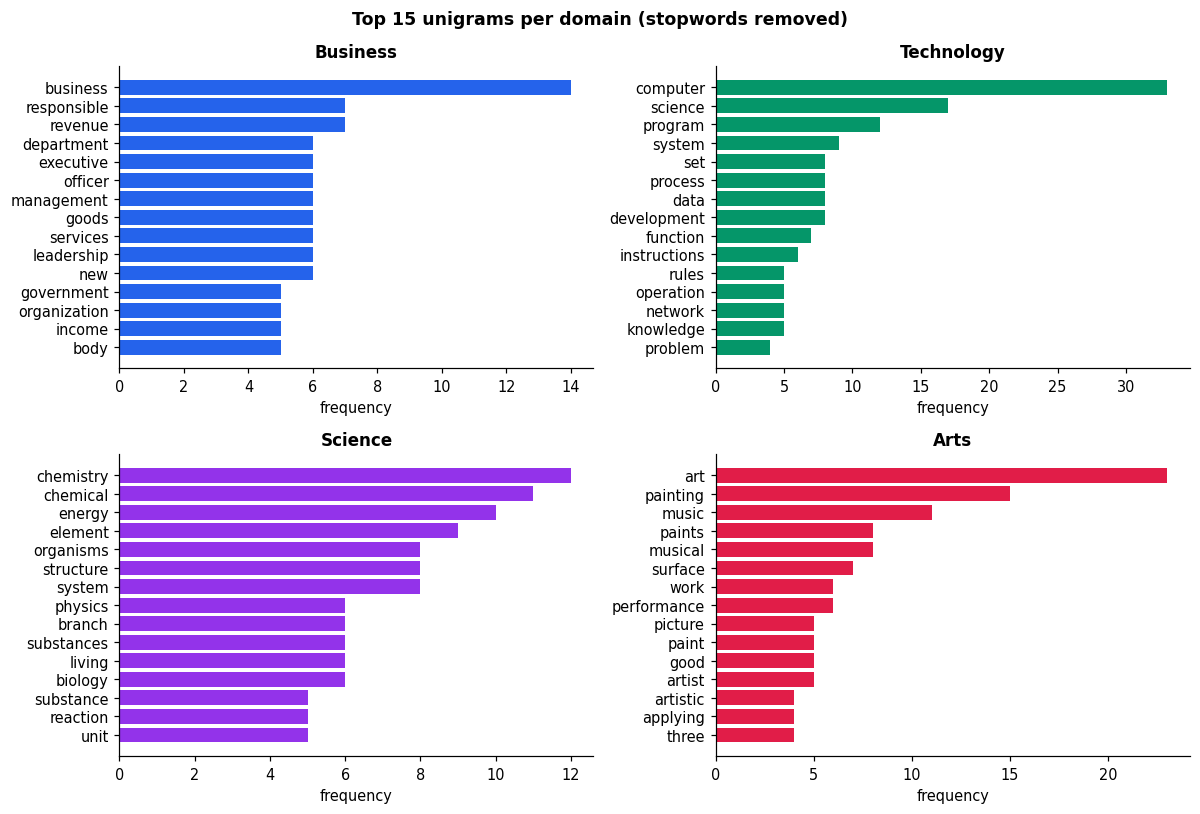

Figure 1. Top 15 unigrams per domain in the domain corpus
Interpretation: Most frequent words: Business → 'business', Technology → 'computer', Science → 'chemistry', Arts → 'art'. Words in the top 15 of two or more domains (system) are general rather than domain-specific, which is why class-based TF-IDF is used for keywords in Section 4.


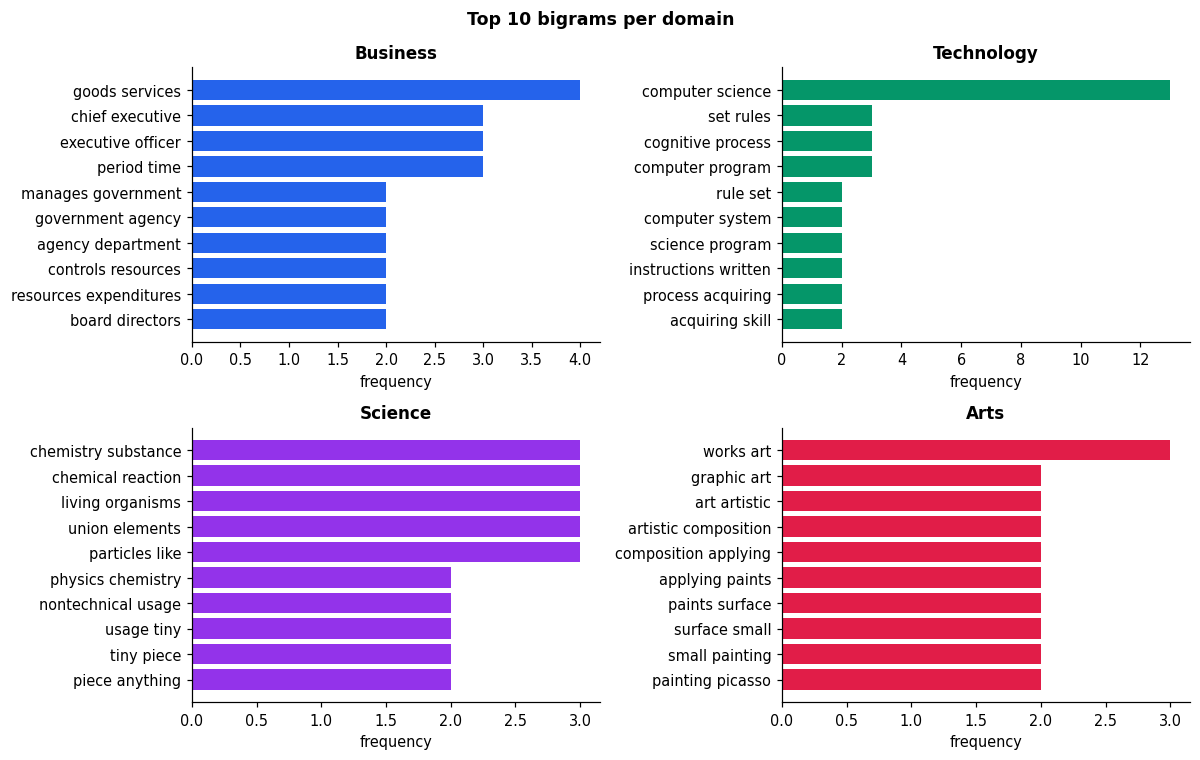

Figure 2. Top 10 bigrams per domain
Interpretation: Bigrams show multi-word concepts (Business: 'goods services', Technology: 'computer science', Science: 'chemistry substance', Arts: 'works art'), which supports treating frequent phrases as single units in Pipeline A.


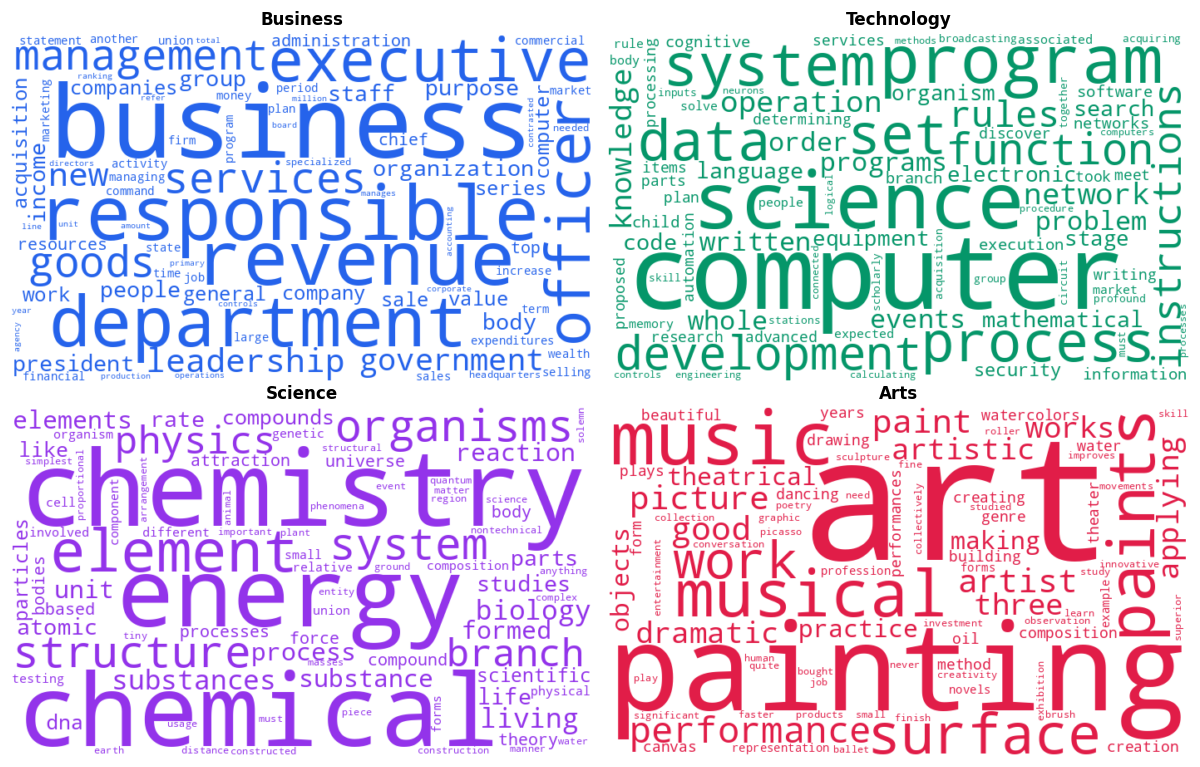

Figure 3. Word cloud of each domain (stopwords removed)
Interpretation: Each domain is dominated by its own subject words, but shared general words also appear in several clouds.


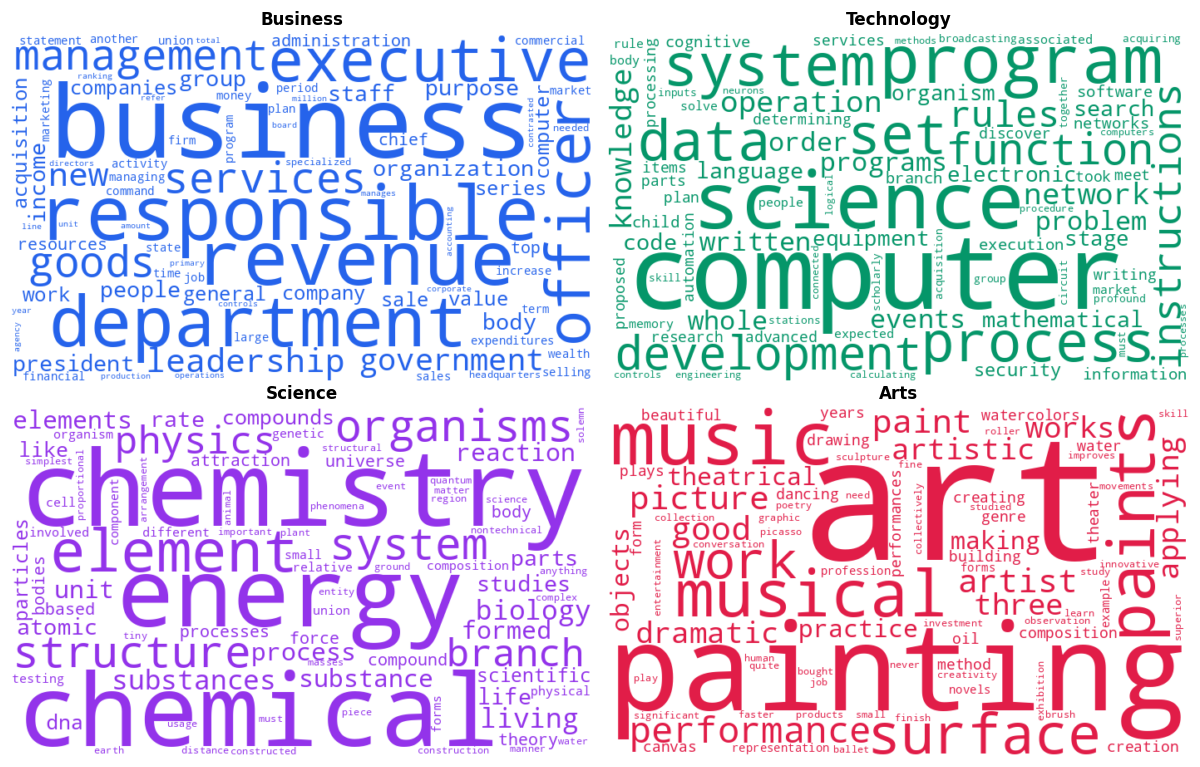

Figure 4. Word cloud of each domain without words shared by 3+ domains
Interpretation: Removing 0 words that are frequent in at least three domains (e.g. ) leaves the domain-specific vocabulary.


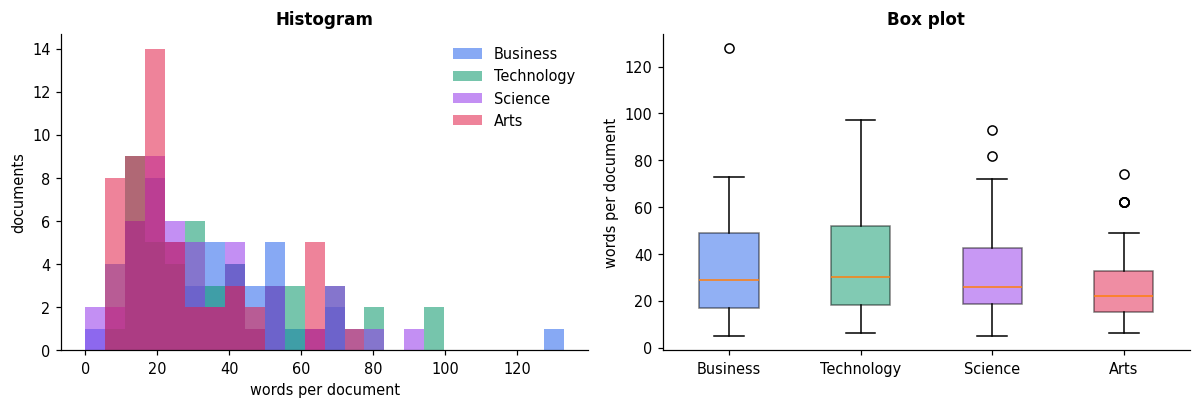

Figure 5. Document length distribution per domain
Interpretation: Lengths are right-skewed (IQR 17–43 words) with 4 outlier documents; short WordNet glosses form the lower tail. LDA uses all documents because long ones are informative, not errors.


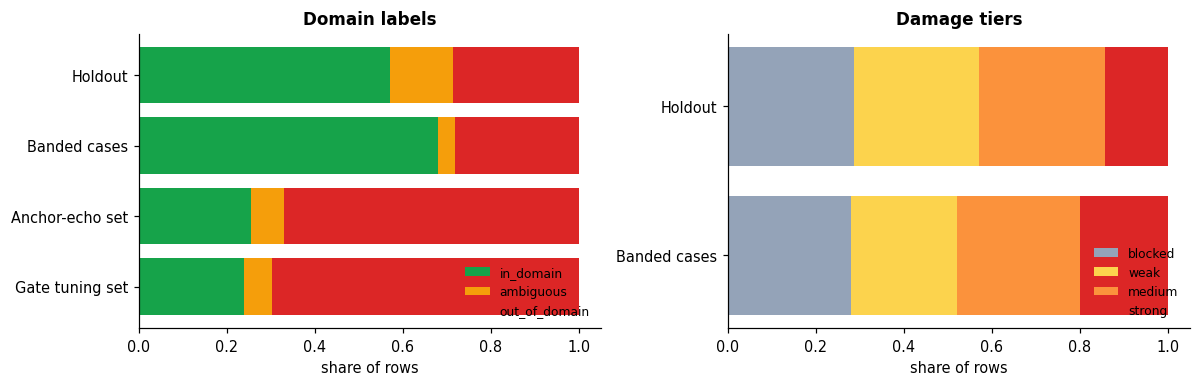

Figure 6. Label distribution of the labelled sets
Interpretation: Out-of-domain rows dominate the gate tuning set (69.8%), while the holdout is balanced by design (7 cases per target, mixing synonyms, related words, distractors and controls).


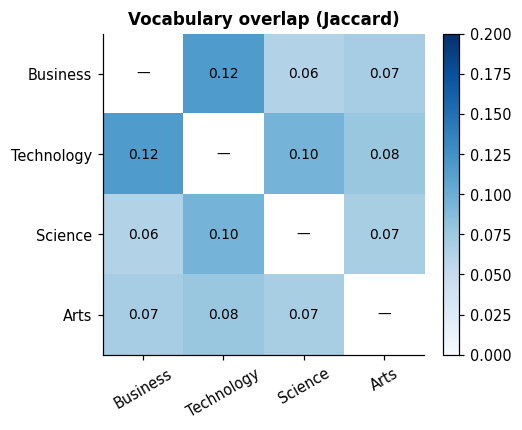

Figure 7. Vocabulary overlap between domains (Jaccard index)
Interpretation: The most similar vocabularies are Business–Technology (Jaccard 0.12); the least similar are Business–Science (0.06). Domains that share vocabulary are expected to be confused more often by the domain gate.


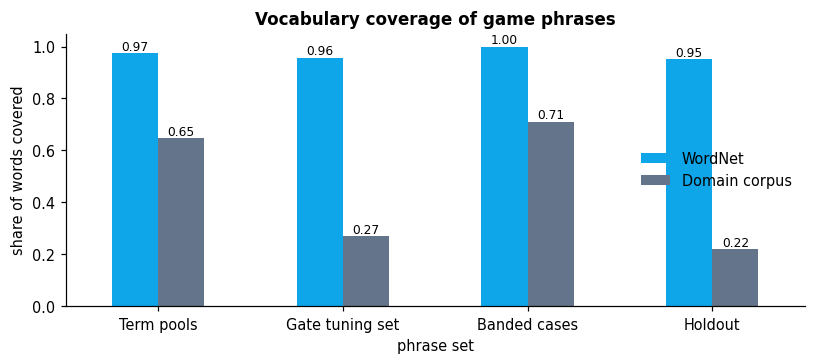

Figure 8. Share of game-phrase words found in WordNet and in the domain corpus
Interpretation: WordNet covers 95.1%–100.0% of the words, but the small domain corpus covers only 22.0%–71.1%; a model trained only on this corpus would miss many player words, which motivates pretrained embeddings.


In [11]:
# 2. Data understanding: descriptive statistics and exploratory data analysis (EDA)
# What this cell does:
#   - Descriptive tables: document length per domain, phrase length per labelled set, label distributions.
#   - Charts: top unigrams / bigrams per domain, word clouds, length histogram + box plot,
#     label distribution, vocabulary overlap between domains, vocabulary coverage of game phrases.
_t_eda = time.perf_counter()
from wordcloud import WordCloud

corpus_df["tokens_basic"] = corpus_df["text"].map(basic_tokens)
DOMAIN_TOKENS = {d: [t for toks in corpus_df.loc[corpus_df["domain"] == d, "tokens_basic"] for t in toks]
                 for d in DOMAINS}
DOMAIN_FREQ = {d: Counter(toks) for d, toks in DOMAIN_TOKENS.items()}

# ---- descriptive statistics -------------------------------------------------------------------------
_len_stats = corpus_df.groupby("domain")["n_words"].agg(["count", "mean", "median", "min", "max", "std"]).reindex(DOMAINS)
save_table(_len_stats, "doc_length_stats", "Document length (words) per domain", "Result 2 Data understanding",
           f"Documents have a median of {corpus_df['n_words'].median():.0f} words "
           f"(range {corpus_df['n_words'].min()}–{corpus_df['n_words'].max()}); "
           f"{_len_stats['mean'].idxmax()} has the longest documents on average "
           f"({_len_stats['mean'].max():.0f} words) and {_len_stats['mean'].idxmin()} the shortest "
           f"({_len_stats['mean'].min():.0f}).", index=True)

_holdout_frame = pd.DataFrame(HOLDOUT_CASES_DRAFT, columns=["target", "guess", "domain", "label", "tier"])
_phrase_sets = {
    "Term pools": [t for d in DOMAINS for t in domain_term_pool(d, DOMAIN_EXAMPLES, POOL_VOCAB, GENERIC_TERMS_V2)],
    "Gate tuning set": gate_set_df["phrase"].tolist(),
    "Banded cases": damage_cases_df["guess"].map(clean_text).tolist(),
    "Holdout": _holdout_frame["guess"].map(clean_text).tolist(),
}
_phrase_len = pd.DataFrame({name: pd.Series([len(p.split()) for p in ps]).value_counts().reindex([1, 2, 3], fill_value=0)
                            for name, ps in _phrase_sets.items()}).T
_phrase_len.columns = ["1 word", "2 words", "3 words"]
_phrase_len["mean words"] = [np.mean([len(p.split()) for p in ps]) for ps in _phrase_sets.values()]
save_table(_phrase_len, "phrase_length", "Phrase length (words) in each phrase set", "Result 2 Data understanding",
           f"Game inputs are very short: {pct(_phrase_len['1 word'].sum() / _phrase_len[['1 word', '2 words', '3 words']].values.sum())} "
           "of all phrases are a single word, so methods that rely on word overlap or long context have little to work with.",
           index=True)

_label_dist = pd.concat({
    "Gate tuning set": gate_set_df["label"].value_counts(),
    "Anchor-echo set": anchor_echo_df["label"].value_counts(),
    "Banded cases": damage_cases_df["human_label"].value_counts(),
    "Holdout": _holdout_frame["label"].value_counts(),
}, axis=1).reindex(["in_domain", "ambiguous", "out_of_domain"]).fillna(0).astype(int).T
_tier_dist = pd.concat({
    "Banded cases": damage_cases_df["human_expected_tier"].value_counts(),
    "Holdout": _holdout_frame["tier"].value_counts(),
}, axis=1).reindex(TIER_ORDER).fillna(0).astype(int).T
save_table(_label_dist, "label_distribution", "Domain-label distribution per labelled set", "Result 2 Data understanding",
           f"The gate tuning set is imbalanced: {pct(_label_dist.loc['Gate tuning set', 'out_of_domain'] / _label_dist.loc['Gate tuning set'].sum())} "
           f"out-of-domain and only {_label_dist.loc['Gate tuning set', 'ambiguous']} ambiguous rows, so accuracy alone "
           "would be misleading; macro F1 and per-class rates are reported instead.", index=True)

# ---- word frequency ---------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, d in zip(axes.ravel(), DOMAINS):
    words, counts = zip(*DOMAIN_FREQ[d].most_common(15))
    ax.barh(words[::-1], counts[::-1], color=DOMAIN_COLORS[d])
    ax.set_title(d)
    ax.set_xlabel("frequency")
fig.suptitle("Top 15 unigrams per domain (stopwords removed)", fontweight="bold")
fig.tight_layout()
_top1 = {d: DOMAIN_FREQ[d].most_common(1)[0][0] for d in DOMAINS}
_top15 = [{w for w, _ in DOMAIN_FREQ[d].most_common(15)} for d in DOMAINS]
_shared15 = sorted({w for s in _top15 for w in s if sum(w in t for t in _top15) >= 2})
save_figure(fig, "top_unigrams", "Top 15 unigrams per domain in the domain corpus", "Result 2 Data understanding",
            "Most frequent words: " + ", ".join(f"{d} → '{w}'" for d, w in _top1.items())
            + (". Words in the top 15 of two or more domains (" + ", ".join(_shared15[:6]) + ") are general rather than "
               "domain-specific, which is why class-based TF-IDF is used for keywords in Section 4." if _shared15 else
               ". No word is in the top 15 of two domains, so the corpus vocabulary is already domain-specific."))

def _bigrams(tokens):
    return list(zip(tokens, tokens[1:]))
DOMAIN_BIGRAMS = {d: Counter(b for toks in corpus_df.loc[corpus_df["domain"] == d, "tokens_basic"] for b in _bigrams(toks))
                  for d in DOMAINS}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, d in zip(axes.ravel(), DOMAINS):
    top = DOMAIN_BIGRAMS[d].most_common(10)
    labels = [" ".join(b) for b, _ in top][::-1]
    ax.barh(labels, [c for _, c in top][::-1], color=DOMAIN_COLORS[d])
    ax.set_title(d)
    ax.set_xlabel("frequency")
fig.suptitle("Top 10 bigrams per domain", fontweight="bold")
fig.tight_layout()
save_figure(fig, "top_bigrams", "Top 10 bigrams per domain", "Result 2 Data understanding",
            "Bigrams show multi-word concepts (" + ", ".join(f"{d}: '{' '.join(DOMAIN_BIGRAMS[d].most_common(1)[0][0])}'"
                                                             for d in DOMAINS if DOMAIN_BIGRAMS[d])
            + "), which supports treating frequent phrases as single units in Pipeline A.")

# ---- word clouds -------------------------------------------------------------------------------------
def _cloud(freq: Counter, color: str):
    return WordCloud(width=700, height=420, background_color="white", random_state=SEED,
                     color_func=lambda *a, **k: color, max_words=80).generate_from_frequencies(freq)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, d in zip(axes.ravel(), DOMAINS):
    ax.imshow(_cloud(DOMAIN_FREQ[d], DOMAIN_COLORS[d]), interpolation="bilinear")
    ax.set_title(d)
    ax.axis("off")
fig.tight_layout()
save_figure(fig, "wordcloud", "Word cloud of each domain (stopwords removed)", "Result 2 Data understanding",
            "Each domain is dominated by its own subject words, but shared general words also appear in several clouds.")

_top50 = {d: {w for w, _ in DOMAIN_FREQ[d].most_common(50)} for d in DOMAINS}
SHARED_GENERIC = set.intersection(*_top50.values()) | {w for w in set.union(*_top50.values())
                                                       if sum(w in s for s in _top50.values()) >= 3}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, d in zip(axes.ravel(), DOMAINS):
    freq = Counter({w: c for w, c in DOMAIN_FREQ[d].items() if w not in SHARED_GENERIC})
    ax.imshow(_cloud(freq, DOMAIN_COLORS[d]), interpolation="bilinear")
    ax.set_title(d)
    ax.axis("off")
fig.tight_layout()
save_figure(fig, "wordcloud_specific", "Word cloud of each domain without words shared by 3+ domains",
            "Result 2 Data understanding",
            f"Removing {len(SHARED_GENERIC)} word{'s' if len(SHARED_GENERIC) != 1 else ''} that are frequent in at least three domains "
            f"(e.g. {', '.join(sorted(SHARED_GENERIC)[:6])}) leaves the domain-specific vocabulary.")

# ---- length distribution -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0, corpus_df["n_words"].max() + 5, 25)
for d in DOMAINS:
    ax1.hist(corpus_df.loc[corpus_df["domain"] == d, "n_words"], bins=bins, alpha=0.55, label=d, color=DOMAIN_COLORS[d])
ax1.set_xlabel("words per document")
ax1.set_ylabel("documents")
ax1.set_title("Histogram")
ax1.legend(frameon=False)
_data = [corpus_df.loc[corpus_df["domain"] == d, "n_words"] for d in DOMAINS]
bp = ax2.boxplot(_data, patch_artist=True)
ax2.set_xticks(range(1, len(DOMAINS) + 1), DOMAINS)
for patch, d in zip(bp["boxes"], DOMAINS):
    patch.set_facecolor(DOMAIN_COLORS[d])
    patch.set_alpha(0.5)
ax2.set_ylabel("words per document")
ax2.set_title("Box plot")
fig.tight_layout()
_q1, _q3 = corpus_df["n_words"].quantile([0.25, 0.75])
_outliers = int(((corpus_df["n_words"] < _q1 - 1.5 * (_q3 - _q1)) | (corpus_df["n_words"] > _q3 + 1.5 * (_q3 - _q1))).sum())
save_figure(fig, "doc_length", "Document length distribution per domain", "Result 2 Data understanding",
            f"Lengths are right-skewed (IQR {_q1:.0f}–{_q3:.0f} words) with {_outliers} outlier documents; short "
            "WordNet glosses form the lower tail. LDA uses all documents because long ones are informative, not errors.")

# ---- label distribution chart -----------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
_shares = _label_dist.div(_label_dist.sum(axis=1), axis=0)
left = np.zeros(len(_shares))
for lab in _shares.columns:
    ax1.barh(_shares.index, _shares[lab], left=left, color=LABEL_COLORS[lab], label=lab)
    left += _shares[lab].to_numpy()
ax1.set_xlabel("share of rows")
ax1.set_title("Domain labels")
ax1.legend(frameon=False, fontsize=8, loc="lower right")
_tshares = _tier_dist.div(_tier_dist.sum(axis=1), axis=0)
left = np.zeros(len(_tshares))
for tier, color in zip(TIER_ORDER, ["#94a3b8", "#fcd34d", "#fb923c", "#dc2626"]):
    ax2.barh(_tshares.index, _tshares[tier], left=left, color=color, label=tier)
    left += _tshares[tier].to_numpy()
ax2.set_xlabel("share of rows")
ax2.set_title("Damage tiers")
ax2.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
save_figure(fig, "label_distribution", "Label distribution of the labelled sets", "Result 2 Data understanding",
            f"Out-of-domain rows dominate the gate tuning set ({pct(_shares.loc['Gate tuning set', 'out_of_domain'])}), while "
            "the holdout is balanced by design (7 cases per target, mixing synonyms, related words, distractors and controls).")

# ---- vocabulary overlap ------------------------------------------------------------------------------
_vocab = {d: set(DOMAIN_FREQ[d]) for d in DOMAINS}
jaccard = pd.DataFrame([[len(_vocab[a] & _vocab[b]) / len(_vocab[a] | _vocab[b]) for b in DOMAINS] for a in DOMAINS],
                       index=DOMAINS, columns=DOMAINS)
fig, ax = plt.subplots(figsize=(4.8, 4))
_jv = jaccard.values.copy()
np.fill_diagonal(_jv, np.nan)
im = ax.imshow(_jv, cmap="Blues", vmin=0, vmax=max(0.2, np.nanmax(_jv)))
ax.set_xticks(range(4), DOMAINS, rotation=30)
ax.set_yticks(range(4), DOMAINS)
for i in range(4):
    for j in range(4):
        ax.text(j, i, "—" if i == j else f"{jaccard.iat[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Vocabulary overlap (Jaccard)")
fig.tight_layout()
_off = jaccard.where(~np.eye(4, dtype=bool)).stack()
_pair = _off.idxmax()
save_figure(fig, "vocab_overlap", "Vocabulary overlap between domains (Jaccard index)", "Result 2 Data understanding",
            f"The most similar vocabularies are {_pair[0]}–{_pair[1]} (Jaccard {_off.max():.2f}); the least similar are "
            f"{_off.idxmin()[0]}–{_off.idxmin()[1]} ({_off.min():.2f}). Domains that share vocabulary are expected to be "
            "confused more often by the domain gate.")

# ---- vocabulary coverage of game phrases ---------------------------------------------------------------
_corpus_vocab = set().union(*_vocab.values())
_cov_rows = []
for name, phrases in _phrase_sets.items():
    words = [w for p in phrases for w in p.split()]
    _cov_rows.append({"phrase set": name,
                      "WordNet": np.mean([bool(wn.synsets(w)) for w in words]),
                      "Domain corpus": np.mean([w in _corpus_vocab for w in words])})
coverage_df = pd.DataFrame(_cov_rows).set_index("phrase set")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
coverage_df.plot.bar(ax=ax, color=["#0ea5e9", "#64748b"], rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of words covered")
ax.set_title("Vocabulary coverage of game phrases")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "vocab_coverage", "Share of game-phrase words found in WordNet and in the domain corpus",
            "Result 2 Data understanding",
            f"WordNet covers {pct(coverage_df['WordNet'].min())}–{pct(coverage_df['WordNet'].max())} of the words, but the small "
            f"domain corpus covers only {pct(coverage_df['Domain corpus'].min())}–{pct(coverage_df['Domain corpus'].max())}; "
            "a model trained only on this corpus would miss many player words, which motivates pretrained embeddings.")
log_section("2. Data understanding (EDA)", _t_eda)

## 3. Text preprocessing
Two pipelines: a classical one for text mining (Sections 4–5) and the light one used by the game.

Table 7. One document per domain before and after each pipeline


,domain,original (first 70 chars),Pipeline A tokens (first 12),Pipeline B clean_text (first 70 chars)
0,Business,a person responsible for the administration of a business. persons who…,responsible administration business administer law manage government agency department,a person responsible for the administration of a business persons who …
50,Technology,a precise rule (or set of rules) specifying how to solve some problem…,precise rule set rule specify solve problem,a precise rule or set of rules specifying how to solve some problem…
96,Science,(chemistry) a substance that initiates or accelerates a chemical react…,chemistry_substance initiate accelerate chemical_reaction without affected cause important event happen invasion act,chemistry a substance that initiates or accelerates a chemical reactio…
143,Arts,graphic art consisting of an artistic composition made by applying pai…,graphic art artistic composition apply_paint surface small painting picasso buy paint investment,graphic art consisting of an artistic composition made by applying pai…


Interpretation: Pipeline A keeps only lemmatized content words (and joins frequent pairs into bigrams); Pipeline B keeps the full sentence, which is what a sentence-embedding model expects.
Table 8. Game inputs under Pipeline B (used) and Pipeline A (not used)


,player input,clean_text (Pipeline B),Pipeline A (for comparison)
0,Machine-Learning!!,machine learning,machine learning
1,C.E.O,c e o,(empty)
2,Oil Painting,oil painting,oil painting
3,the ALGORITHMS,the algorithms,algorithm


Interpretation: Pipeline A would destroy short game inputs (e.g. 'C.E.O' becomes empty after the length filter), so the game uses the light Pipeline B normalisation only.


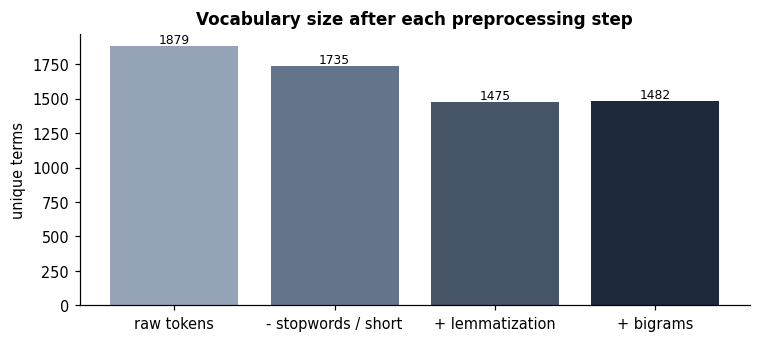

Figure 9. Vocabulary size after each Pipeline A step
Interpretation: Stopword removal and lemmatization shrink the vocabulary from 1879 to 1475 terms (21.5% smaller); the bigram step adds 8 phrase terms such as apply_paint, chemical_reaction, chemistry_substance, cognitive_process.


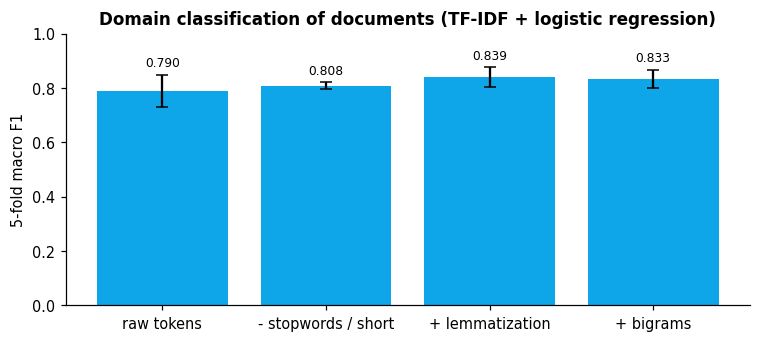

Figure 10. Preprocessing ablation: 5-fold macro F1 of a TF-IDF domain classifier
Interpretation: The best setting is '+ lemmatization' (macro F1 0.839); the full pipeline changes macro F1 by +0.044 versus raw tokens. With only 194 documents the differences are within one standard deviation, so preprocessing mainly helps interpretability (cleaner keywords and topics) rather than accuracy.
Table 9. Preprocessing ablation (5-fold stratified CV)


,preprocessing,macro F1 (mean),macro F1 (std)
0,raw tokens,0.790,0.059
1,- stopwords / short,0.808,0.012
2,+ lemmatization,0.839,0.037
3,+ bigrams,0.833,0.034


In [12]:
# 3. Text preprocessing: Pipeline A (classical, for text mining) vs Pipeline B (game input, for SBERT)
# What this cell does:
#   - Pipeline A: lowercase → tokenize → remove stopwords / short tokens → POS-aware lemmatization → bigrams.
#     Used by keywords, LDA and the TF-IDF baseline.
#   - Pipeline B: clean_text() only (lowercase, strip punctuation). SBERT has its own WordPiece tokenizer and
#     was trained on natural text, so stopword removal or lemmatization would change the input it expects.
#   - Vocabulary-size funnel and an ablation: 5-fold domain classification of documents (TF-IDF + logistic
#     regression) with each preprocessing step switched on in turn.
_t_pre = time.perf_counter()
from gensim.models.phrases import Phrases, Phraser
from nltk.stem import WordNetLemmatizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

_lemmatizer = WordNetLemmatizer()
_RAW_TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

def _wn_pos(tag: str) -> str:
    return {"J": wn.ADJ, "V": wn.VERB, "R": wn.ADV}.get(tag[:1], wn.NOUN)

def tokenize_raw(text: str) -> list:
    return _RAW_TOKEN_RE.findall(str(text).lower())

def remove_stopwords(tokens: list) -> list:
    return [t for t in tokens if t not in STOP_WORDS and len(t) > 2 and "'" not in t]

def lemmatize(tokens: list) -> list:
    try:
        tags = nltk.pos_tag(tokens)
    except LookupError:
        tags = [(t, "N") for t in tokens]
    return [_lemmatizer.lemmatize(t, _wn_pos(tag)) for t, tag in tags]

def lemma_of(phrase: str) -> list:
    """Lemmatized content tokens of a short phrase (used for coverage checks)."""
    return lemmatize(remove_stopwords(tokenize_raw(phrase)))

corpus_df["tok_raw"] = corpus_df["text"].map(tokenize_raw)
corpus_df["tok_stop"] = corpus_df["tok_raw"].map(remove_stopwords)
corpus_df["tok_lemma"] = corpus_df["tok_stop"].map(lemmatize)
BIGRAM = Phraser(Phrases(corpus_df["tok_lemma"].tolist(), min_count=3, threshold=5, delimiter="_"))
corpus_df["tokens"] = corpus_df["tok_lemma"].map(lambda toks: BIGRAM[toks])   # final Pipeline A output

# ---- before / after examples --------------------------------------------------------------------------
_ex = corpus_df.groupby("domain").head(1)
_ex_table = pd.DataFrame({
    "domain": _ex["domain"],
    "original (first 70 chars)": _ex["text"].str.slice(0, 70) + "…",
    "Pipeline A tokens (first 12)": _ex["tokens"].map(lambda t: " ".join(t[:12])),
    "Pipeline B clean_text (first 70 chars)": _ex["text"].map(lambda s: clean_text(s)[:70] + "…"),
})
save_table(_ex_table, "preprocessing_examples", "One document per domain before and after each pipeline",
           "Method 3 Preprocessing",
           "Pipeline A keeps only lemmatized content words (and joins frequent pairs into bigrams); Pipeline B keeps "
           "the full sentence, which is what a sentence-embedding model expects.")
_game_ex = pd.DataFrame({"player input": ["  Machine-Learning!! ", "C.E.O", "Oil Painting", "the  ALGORITHMS"]})
_game_ex["clean_text (Pipeline B)"] = _game_ex["player input"].map(clean_text)
_game_ex["Pipeline A (for comparison)"] = _game_ex["player input"].map(lambda s: " ".join(lemma_of(s)) or "(empty)")
save_table(_game_ex, "game_input_cleaning", "Game inputs under Pipeline B (used) and Pipeline A (not used)",
           "Method 3 Preprocessing",
           "Pipeline A would destroy short game inputs (e.g. 'C.E.O' becomes empty after the length filter), "
           "so the game uses the light Pipeline B normalisation only.")

# ---- vocabulary funnel ----------------------------------------------------------------------------------
_steps = [("raw tokens", "tok_raw"), ("- stopwords / short", "tok_stop"), ("+ lemmatization", "tok_lemma"),
          ("+ bigrams", "tokens")]
funnel_df = pd.DataFrame([{"step": name, "vocabulary": len({t for toks in corpus_df[col] for t in toks}),
                           "tokens": int(corpus_df[col].map(len).sum())} for name, col in _steps])
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(funnel_df["step"], funnel_df["vocabulary"], color=["#94a3b8", "#64748b", "#475569", "#1e293b"])
ax.bar_label(bars, fontsize=8)
ax.set_ylabel("unique terms")
ax.set_title("Vocabulary size after each preprocessing step")
fig.tight_layout()
_bigram_terms = sorted({t for toks in corpus_df["tokens"] for t in toks if "_" in t})
save_figure(fig, "vocab_funnel", "Vocabulary size after each Pipeline A step", "Method 3 Preprocessing",
            f"Stopword removal and lemmatization shrink the vocabulary from {funnel_df['vocabulary'].iloc[0]} to "
            f"{funnel_df['vocabulary'].iloc[2]} terms ({pct(1 - funnel_df['vocabulary'].iloc[2] / funnel_df['vocabulary'].iloc[0])} "
            f"smaller); the bigram step adds {len(_bigram_terms)} phrase terms such as "
            f"{', '.join(_bigram_terms[:4]) or 'none'}.")

# ---- ablation: does each step help a simple domain classifier? -------------------------------------------
_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ablation_rows = []
for name, col in _steps:
    docs = corpus_df[col].map(" ".join)
    clf = make_pipeline(TfidfVectorizer(token_pattern=r"\S+", min_df=1), LogisticRegression(max_iter=2000, C=5))
    scores = cross_val_score(clf, docs, corpus_df["domain"], cv=_cv, scoring="f1_macro")
    ablation_rows.append({"preprocessing": name, "macro F1 (mean)": scores.mean(), "macro F1 (std)": scores.std()})
ablation_df = pd.DataFrame(ablation_rows)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(ablation_df["preprocessing"], ablation_df["macro F1 (mean)"], yerr=ablation_df["macro F1 (std)"],
       capsize=4, color="#0ea5e9")
ax.set_ylim(0, 1)
ax.set_ylabel("5-fold macro F1")
ax.set_title("Domain classification of documents (TF-IDF + logistic regression)")
for i, (v, sd) in enumerate(zip(ablation_df["macro F1 (mean)"], ablation_df["macro F1 (std)"])):
    ax.text(i, v + sd + 0.03, f"{v:.3f}", ha="center", fontsize=8)
fig.tight_layout()
_best = ablation_df.loc[ablation_df["macro F1 (mean)"].idxmax()]
_gain = ablation_df["macro F1 (mean)"].iloc[-1] - ablation_df["macro F1 (mean)"].iloc[0]
save_figure(fig, "preprocessing_ablation", "Preprocessing ablation: 5-fold macro F1 of a TF-IDF domain classifier",
            "Method 3 Preprocessing",
            f"The best setting is '{_best['preprocessing']}' (macro F1 {_best['macro F1 (mean)']:.3f}); the full pipeline "
            f"changes macro F1 by {_gain:+.3f} versus raw tokens. With only {len(corpus_df)} documents the differences "
            "are within one standard deviation, so preprocessing mainly helps interpretability (cleaner keywords and "
            "topics) rather than accuracy.")
save_table(ablation_df, "preprocessing_ablation", "Preprocessing ablation (5-fold stratified CV)", "Method 3 Preprocessing")
log_section("3. Preprocessing", _t_pre)

## 4. Keyword extraction
Which words characterise each domain, and are they covered by the anchors?

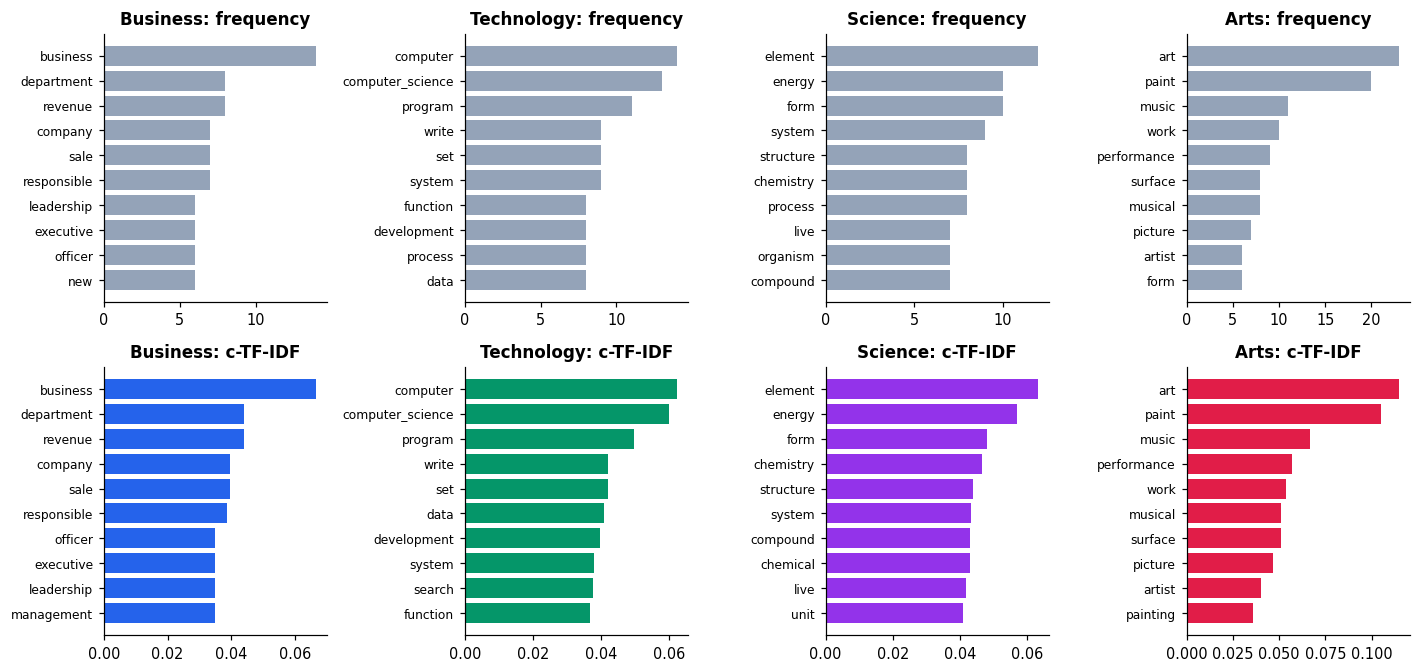

Figure 11. Top-10 keywords per domain: raw frequency (top) vs class-based TF-IDF (bottom)
Interpretation: Raw frequency lists share 0 word(s) across all four domains (none), c-TF-IDF lists share 0; c-TF-IDF removes general words and surfaces the vocabulary that separates the domains, which is what the gate needs.
Table 10. Coverage of the top-20 c-TF-IDF keywords by the anchor sentences and term pools


,domain,top-20 keywords in anchors,in anchors + term pool,high-weight keywords with no anchor / pool word
0,Business,0.55,0.65,"responsible, new, pay, purpose, government, people, lead"
1,Technology,0.65,0.70,"write, set, rule, operation, knowledge, plan"
2,Science,0.45,0.60,"form, system, live, unit, substance, branch, body, plant"
3,Arts,0.40,0.45,"work, surface, picture, play, good, show, produce, sound, theatrical, dramatic"


Interpretation: Only 51.3% of the distinctive corpus keywords appear in the anchor sentences (60.0% with the term pools). Arts has the lowest coverage. The listed words are candidates for new anchors; SBERT can still match them through meaning, but a gap here predicts where the gate will be least confident.


In [13]:
# 4. Keyword extraction: raw frequency vs class-based TF-IDF, and anchor coverage
# What this cell does:
#   - Class-based TF-IDF (c-TF-IDF): each domain = one class document; weight = tf(term, domain) ·
#     log(1 + mean words per domain / total frequency of the term). Rewards terms frequent in ONE domain.
#   - Compares top-10 keywords from frequency and c-TF-IDF.
#   - Anchor coverage: share of each domain's top-20 keywords that already appear in its anchor
#     sentences / term pool (low coverage = vocabulary the gate has no anchor for).
_t_kw = time.perf_counter()
from sklearn.feature_extraction.text import CountVectorizer

class_docs = corpus_df.groupby("domain")["tokens"].apply(lambda s: " ".join(" ".join(t) for t in s)).reindex(DOMAINS)
_cv_class = CountVectorizer(token_pattern=r"\S+")
_tf = _cv_class.fit_transform(class_docs).toarray().astype(float)
_terms = np.array(_cv_class.get_feature_names_out())
_tf_norm = _tf / _tf.sum(axis=1, keepdims=True)
_avg_words = _tf.sum() / len(DOMAINS)
ctfidf = _tf_norm * np.log(1 + _avg_words / _tf.sum(axis=0))
CTFIDF_TOP = {d: [_terms[j] for j in np.argsort(-ctfidf[i])[:20]] for i, d in enumerate(DOMAINS)}
FREQ_TOP = {d: [_terms[j] for j in np.argsort(-_tf[i])[:20]] for i, d in enumerate(DOMAINS)}

fig, axes = plt.subplots(2, 4, figsize=(13, 6.2))
for i, d in enumerate(DOMAINS):
    top_f = np.argsort(-_tf[i])[:10]
    top_c = np.argsort(-ctfidf[i])[:10]
    axes[0, i].barh(_terms[top_f][::-1], _tf[i][top_f][::-1], color="#94a3b8")
    axes[0, i].set_title(f"{d}: frequency")
    axes[1, i].barh(_terms[top_c][::-1], ctfidf[i][top_c][::-1], color=DOMAIN_COLORS[d])
    axes[1, i].set_title(f"{d}: c-TF-IDF")
    for ax in (axes[0, i], axes[1, i]):
        ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
_shared_freq = set.intersection(*[set(v[:10]) for v in FREQ_TOP.values()])
_shared_ctf = set.intersection(*[set(v[:10]) for v in CTFIDF_TOP.values()])
save_figure(fig, "keywords_freq_vs_ctfidf", "Top-10 keywords per domain: raw frequency (top) vs class-based TF-IDF (bottom)",
            "Result 4 Keyword extraction",
            f"Raw frequency lists share {len(_shared_freq)} word(s) across all four domains "
            f"({', '.join(sorted(_shared_freq)) or 'none'}), c-TF-IDF lists share {len(_shared_ctf)}; c-TF-IDF removes "
            "general words and surfaces the vocabulary that separates the domains, which is what the gate needs.")

# ---- anchor coverage -----------------------------------------------------------------------------------
def domain_reference_lemmas(domain: str) -> set:
    """Lemmas used in the domain's anchor sentences, examples and term pool."""
    texts = list(DOMAIN_ANCHORS[domain]) + domain_term_pool(domain, DOMAIN_EXAMPLES, POOL_VOCAB, GENERIC_TERMS_V2)
    return {lem for t in texts for lem in lemma_of(t)}

REF_LEMMAS = {d: domain_reference_lemmas(d) for d in DOMAINS}
ANCHOR_LEMMAS = {d: {lem for t in DOMAIN_ANCHORS[d] for lem in lemma_of(t)} for d in DOMAINS}

def covered(term: str, lemmas: set) -> bool:
    return all(part in lemmas for part in term.split("_"))

coverage_rows, missing_rows = [], []
for d in DOMAINS:
    top = CTFIDF_TOP[d]
    in_anchor = [covered(t, ANCHOR_LEMMAS[d]) for t in top]
    in_ref = [covered(t, REF_LEMMAS[d]) for t in top]
    coverage_rows.append({"domain": d, "top-20 keywords in anchors": np.mean(in_anchor),
                          "in anchors + term pool": np.mean(in_ref)})
    missing_rows.append({"domain": d, "high-weight keywords with no anchor / pool word":
                         ", ".join([t for t, ok in zip(top, in_ref) if not ok][:10])})
keyword_coverage_df = pd.DataFrame(coverage_rows)
save_table(keyword_coverage_df.merge(pd.DataFrame(missing_rows), on="domain"), "keyword_anchor_coverage",
           "Coverage of the top-20 c-TF-IDF keywords by the anchor sentences and term pools",
           "Result 4 Keyword extraction",
           f"Only {pct(keyword_coverage_df['top-20 keywords in anchors'].mean())} of the distinctive corpus keywords "
           f"appear in the anchor sentences ({pct(keyword_coverage_df['in anchors + term pool'].mean())} with the term "
           f"pools). {keyword_coverage_df.loc[keyword_coverage_df['top-20 keywords in anchors'].idxmin(), 'domain']} has the "
           "lowest coverage. The listed words are candidates for new anchors; SBERT can still match them through "
           "meaning, but a gap here predicts where the gate will be least confident.")
log_section("4. Keyword extraction", _t_kw)

## 5. Topic modelling (LDA)
Does the corpus split into the four game domains without labels?

LDA input: 194 documents | dictionary 582 terms (no_below=2, no_above=0.4)


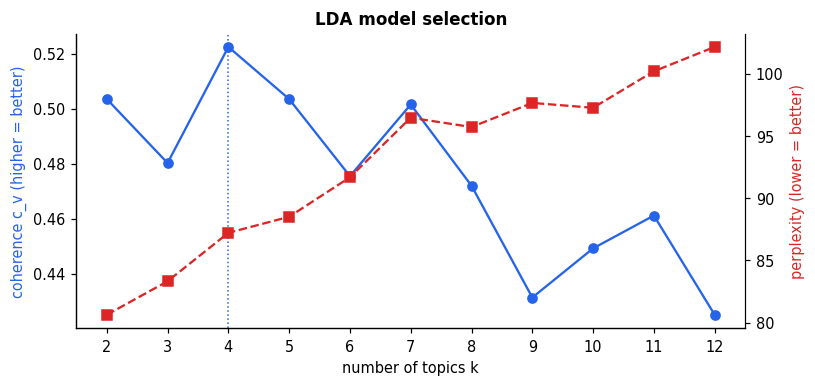

Figure 12. LDA coherence (c_v) and perplexity for each number of topics
Interpretation: Coherence peaks at k = 4 (c_v 0.523); k = 4, the number of game domains, scores 0.523. Perplexity rises from 81 to 102 over the range; on a corpus this small it mostly reflects how thinly the documents are spread over topics, so coherence (agreement with human-interpretable word groups) is used to choose k.
Table 11. LDA coherence and perplexity per k


,k,coherence c_v,perplexity
0,2,0.504,80.627
1,3,0.480,83.324
2,4,0.523,87.216
3,5,0.504,88.510
4,6,0.475,91.684
5,7,0.502,96.472
6,8,0.472,95.723
7,9,0.431,97.661
8,10,0.449,97.272
9,11,0.461,100.206


Table 12. LDA topics (k = 4, best coherence): top words, main domain, anchor coverage


,topic,top words,main domain,share in main domain,anchor coverage
0,0,"art, function, energy, work, set, study, form, good, department, organism",Science,0.451,0.5
1,1,"development, system, program, performance, body, computer, stage, set, write, involve",Technology,0.346,0.7
2,2,"revenue, computer_science, structure, data, computer, study, part, process, series, company",Technology,0.312,0.8
3,3,"paint, business, form, leadership, group, surface, art, lead, union, painting",Arts,0.363,0.5


Interpretation: 0/4 topics put at least half of their weight in one domain. Mean anchor coverage of topic words is 62.5%; the topic with the lowest coverage (T0: art, function, energy, work, set, study, form, good, departm…) describes vocabulary the anchors do not mention.


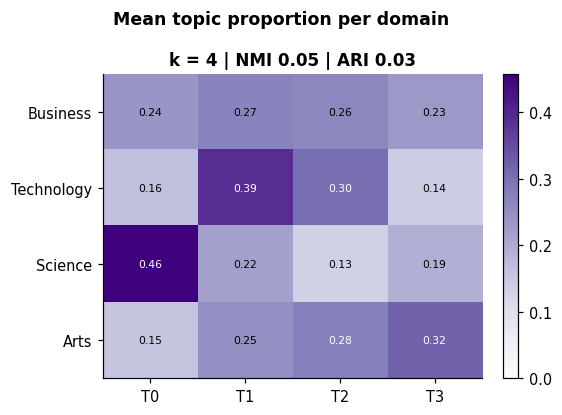

Figure 13. Topic × domain heatmap (mean document-topic proportion)
Interpretation: With k = 4 the dominant topic agrees with the domain label at NMI 0.05 / ARI 0.03. Unsupervised topics only partly follow the four game domains: documents mix subjects, and short summaries give LDA few words per document. This is evidence that domain membership is better decided by meaning-based embeddings plus explicit anchors than by word co-occurrence alone.


In [14]:
# 5. Topic modelling with LDA (gensim)
# What this cell does:
#   - Bag-of-words dictionary from the Pipeline A tokens (rare and very common terms filtered).
#   - Fits LDA for every k in LDA_K_RANGE; records c_v coherence and per-word perplexity.
#   - Chooses k by the best coherence; shows top words per topic, topic × domain heatmap,
#     NMI / ARI between the dominant topic and the domain label, and anchor coverage of each topic.
#   - Also fits k = 4 (one topic per domain) to test whether the corpus "naturally" splits into the 4 domains.
_t_lda = time.perf_counter()
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel

LDA_TEXTS = corpus_df["tokens"].tolist()
lda_dict = Dictionary(LDA_TEXTS)
lda_dict.filter_extremes(no_below=2, no_above=0.4)
LDA_BOW = [lda_dict.doc2bow(t) for t in LDA_TEXTS]
LDA_PASSES, LDA_ITER = (10, 100) if FAST_MODE else (30, 400)
print(f"LDA input: {len(LDA_BOW)} documents | dictionary {len(lda_dict)} terms (no_below=2, no_above=0.4)")

def fit_lda(k: int) -> LdaModel:
    return LdaModel(corpus=LDA_BOW, id2word=lda_dict, num_topics=k, passes=LDA_PASSES, iterations=LDA_ITER,
                    alpha="auto", eta="auto", random_state=SEED, eval_every=None)

lda_rows, LDA_MODELS = [], {}
for k in LDA_K_RANGE:
    m = fit_lda(k)
    LDA_MODELS[k] = m
    coherence = CoherenceModel(model=m, texts=LDA_TEXTS, dictionary=lda_dict, coherence="c_v",
                               processes=1).get_coherence()
    lda_rows.append({"k": k, "coherence c_v": coherence, "perplexity": float(np.exp2(-m.log_perplexity(LDA_BOW)))})
lda_scan = pd.DataFrame(lda_rows)
LDA_K = int(lda_scan.loc[lda_scan["coherence c_v"].idxmax(), "k"])
if 4 not in LDA_MODELS:
    LDA_MODELS[4] = fit_lda(4)

fig, ax1 = plt.subplots(figsize=(7.5, 3.6))
ax1.plot(lda_scan["k"], lda_scan["coherence c_v"], "o-", color="#2563eb", label="coherence c_v")
ax1.axvline(LDA_K, color="#2563eb", ls=":", lw=1)
ax1.set_xlabel("number of topics k")
ax1.set_xticks(list(lda_scan["k"]))
ax1.set_xticks(list(lda_scan["k"]))
ax1.set_ylabel("coherence c_v (higher = better)", color="#2563eb")
ax2 = ax1.twinx()
ax2.plot(lda_scan["k"], lda_scan["perplexity"], "s--", color="#dc2626", label="perplexity")
ax2.set_ylabel("perplexity (lower = better)", color="#dc2626")
ax2.spines["right"].set_visible(True)
ax1.set_title("LDA model selection")
fig.tight_layout()
save_figure(fig, "lda_k_selection", "LDA coherence (c_v) and perplexity for each number of topics",
            "Result 5 Topic modelling",
            f"Coherence peaks at k = {LDA_K} (c_v {lda_scan['coherence c_v'].max():.3f}); k = 4, the number of game "
            f"domains, scores {lda_scan.set_index('k')['coherence c_v'].get(4, float('nan')):.3f}. Perplexity "
            f"{'rises' if lda_scan['perplexity'].iloc[-1] > lda_scan['perplexity'].iloc[0] else 'falls'} from "
            f"{lda_scan['perplexity'].iloc[0]:.0f} to {lda_scan['perplexity'].iloc[-1]:.0f} over the range; on a corpus this "
            "small it mostly reflects how thinly the documents are spread over topics, so coherence (agreement with "
            "human-interpretable word groups) is used to choose k.")
save_table(lda_scan, "lda_k_scan", "LDA coherence and perplexity per k", "Result 5 Topic modelling")

def topic_frame(m: LdaModel, topn: int = 10) -> pd.DataFrame:
    return pd.DataFrame([{"topic": t, "top words": ", ".join(w for w, _ in m.show_topic(t, topn))}
                         for t in range(m.num_topics)])

def doc_topics(m: LdaModel) -> np.ndarray:
    out = np.zeros((len(LDA_BOW), m.num_topics))
    for i, bow in enumerate(LDA_BOW):
        for t, p in m.get_document_topics(bow, minimum_probability=0):
            out[i, t] = p
    return out

LDA_RESULTS = {}
for k in sorted({LDA_K, 4}):
    m = LDA_MODELS[k]
    theta = doc_topics(m)
    dominant = theta.argmax(axis=1)
    heat = pd.DataFrame(theta, columns=[f"T{t}" for t in range(k)]).assign(domain=corpus_df["domain"].values) \
             .groupby("domain").mean().reindex(DOMAINS)
    topics = topic_frame(m)
    topics["main domain"] = [heat[f"T{t}"].idxmax() for t in range(k)]
    topics["share in main domain"] = [heat[f"T{t}"].max() / heat[f"T{t}"].sum() for t in range(k)]
    words = [[w for w, _ in m.show_topic(t, 10)] for t in range(k)]
    all_anchor = set().union(*ANCHOR_LEMMAS.values())
    topics["anchor coverage"] = [np.mean([covered(w, all_anchor) for w in ws]) for ws in words]
    LDA_RESULTS[k] = {"model": m, "theta": theta, "heat": heat, "topics": topics,
                      "nmi": normalized_mutual_info_score(corpus_df["domain"], dominant),
                      "ari": adjusted_rand_score(corpus_df["domain"], dominant)}

for k in sorted(LDA_RESULTS):
    r = LDA_RESULTS[k]
    tag = "best coherence" if k == LDA_K else "one topic per domain"
    save_table(r["topics"], f"lda_topics_k{k}", f"LDA topics (k = {k}, {tag}): top words, main domain, anchor coverage",
               "Result 5 Topic modelling",
               f"{(r['topics']['share in main domain'] >= 0.5).sum()}/{k} topics put at least half of their weight in one "
               f"domain. Mean anchor coverage of topic words is {pct(r['topics']['anchor coverage'].mean())}; the topic "
               f"with the lowest coverage (T{int(r['topics']['anchor coverage'].idxmin())}: "
               f"{r['topics'].loc[r['topics']['anchor coverage'].idxmin(), 'top words'][:60]}…) describes vocabulary "
               "the anchors do not mention.")

fig, axes = plt.subplots(1, len(LDA_RESULTS), figsize=(5.2 * len(LDA_RESULTS), 3.8), squeeze=False)
for ax, k in zip(axes[0], sorted(LDA_RESULTS)):
    heat = LDA_RESULTS[k]["heat"]
    im = ax.imshow(heat.values, cmap="Purples", aspect="auto", vmin=0, vmax=heat.values.max())
    ax.set_xticks(range(k), heat.columns)
    ax.set_yticks(range(len(DOMAINS)), DOMAINS)
    for i in range(len(DOMAINS)):
        for j in range(k):
            ax.text(j, i, f"{heat.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if heat.iat[i, j] > 0.6 * heat.values.max() else "black")
    ax.set_title(f"k = {k} | NMI {LDA_RESULTS[k]['nmi']:.2f} | ARI {LDA_RESULTS[k]['ari']:.2f}")
    fig.colorbar(im, ax=ax, fraction=0.04)
fig.suptitle("Mean topic proportion per domain", fontweight="bold")
fig.tight_layout()
r4 = LDA_RESULTS[4]
save_figure(fig, "lda_topic_domain_heatmap", "Topic × domain heatmap (mean document-topic proportion)",
            "Result 5 Topic modelling",
            f"With k = 4 the dominant topic agrees with the domain label at NMI {r4['nmi']:.2f} / ARI {r4['ari']:.2f}. "
            "Unsupervised topics only partly follow the four game domains: documents mix subjects, and short "
            "summaries give LDA few words per document. This is evidence that domain membership is better decided "
            "by meaning-based embeddings plus explicit anchors than by word co-occurrence alone.")
if RUN_PYLDAVIS:
    try:
        pip_install(["pyLDAvis"])
        import pyLDAvis
        import pyLDAvis.gensim_models
        _vis = pyLDAvis.gensim_models.prepare(LDA_MODELS[LDA_K], LDA_BOW, lda_dict)
        pyLDAvis.save_html(_vis, str(REPORT_DIR / f"lda_k{LDA_K}.html"))
        display(pyLDAvis.display(_vis))
    except Exception as error:
        print(f"WARNING: pyLDAvis failed ({error}); skipped.")
log_section("5. Topic modelling (LDA)", _t_lda)

## 6. Modelling
- **6.1** Game engine (domain gate + damage) — unchanged from the main notebook.
- **6.2–6.5** Calibration and evaluation functions (gate grid with 5-fold grouped CV, damage grid with leave-one-target-out CV).
- **6.6–6.7** Model loading and fine-tuning (train if missing / always / never) with a saved training report.
- **6.8** Calibrate SBERT Base and Fine-tuned with identical procedures.
- **6.9** TF-IDF + LSA and GloVe representations; K-means clustering of the corpus.

In [15]:
# 6.1 Engine: EngineConfig (every tunable parameter) + LexicalCombatEngine (all scoring)
# What this cell does:
#   - EngineConfig: every tunable parameter (gate thresholds, damage curve, tiers).
#   - LexicalCombatEngine: domain gate, target relevance, damage and battle simulation.
#   - evaluate_test_set(): runs a table of cases through the engine.
_t_s3 = time.perf_counter()

@dataclass(frozen=True)
class EngineConfig:
    """Tunable parameters. Defaults are the pre-calibration values; Section 5 replaces some."""
    # Domain gate (debiased score = top-k anchor cosine minus the domain's noise background)
    anchor_topk: int = 2                     # mean of the k best anchors per domain
    gate_primary_min: float = 0.20           # primary: required domain is #1 and >= this
    gate_secondary_min: float = 0.08         # secondary / weak: required domain >= this
    gate_secondary_max_gap: float = 0.04     # secondary: may trail the #1 domain by <= this
    gate_weak_max_gap: float = 0.10          # weak secondary: may trail by <= this
    domain_primary_bonus: float = 1.00       # damage multiplier per gate result
    domain_secondary_multiplier: float = 0.75
    domain_weak_secondary_multiplier: float = 0.50
    display_softmax_temperature: float = 0.05  # display only, not used for decisions
    # Target relevance r = (cos - noise) / (ceiling - noise)
    noise_percentile: int = 90               # noise floor = percentile of cos(target, everyday nouns)
    ceiling_topk: int = 3                    # ceiling = mean of the top-k pool cosines
    min_calibration_span: float = 0.15       # fixed span floor (min_span_mode == "fixed")
    min_span_mode: str = "median"            # "median": floor = median span of calibration targets
    primary_graze_floor: bool = True         # primary guess above median noise gets chip damage
    primary_graze_noise_pct: int = 50
    # Damage curve on r in [0, 1]
    relevance_min: float = 0.10              # r below this -> no effect
    damage_gamma: float = 1.0                # >1 stricter mid-range, <1 more generous
    graze_min_percent: float = 5             # damage at r == relevance_min
    max_hit_percent: float = 45              # damage at r == 1 (per-hit cap)
    chip_percent: float = 4                  # minimum damage of an allowed, relevant hit
    # Penalties and input rules
    generic_penalty: float = 0.60            # broad field labels ("science")
    echo_relative: float = 0.60              # echo if cos to an earlier hit is this far from noise to 1.0
    echo_penalty: float = 0.50
    block_target_word_in_guess: bool = True  # a guess may not contain any word of the target
    tier_cuts: tuple = ((38, "CRITICAL STRIKE"), (26, "STRONG HIT"), (14, "SOLID HIT"))

@dataclass(frozen=True)
class EngineData:
    """Vocabularies the engine encodes. Built once from Sections 1–2."""
    domains: tuple
    anchors: dict
    noise_vocab: tuple
    examples: dict
    pool_vocab: dict
    generic_terms: frozenset
    calibration_targets: dict

GATE_LABEL_OF_KIND = {"primary": "in_domain", "secondary": "ambiguous",
                      "weak_secondary": "ambiguous", "out_of_domain": "out_of_domain"}

def kinds_to_labels(kinds) -> np.ndarray:
    """Map gate kinds to the human label vocabulary."""
    kinds = np.asarray(kinds)
    return np.where(kinds == "primary", "in_domain",
                    np.where(kinds == "out_of_domain", "out_of_domain", "ambiguous"))

def topk_mean(similarities, k: int):
    """Mean of the k largest values along the last axis."""
    sims = np.asarray(similarities, dtype=float)
    k = max(1, min(int(k), sims.shape[-1]))
    return np.sort(sims, axis=-1)[..., -k:].mean(axis=-1)

def normalized_relevance(similarity, noise, ceiling):
    """r = (cos - noise) / (ceiling - noise), clipped to [0, 1]."""
    return np.clip((np.asarray(similarity, dtype=float) - noise) / (ceiling - noise), 0.0, 1.0)

def gate_kind_arrays(required, lead, primary_min, secondary_min, secondary_gap, weak_gap) -> np.ndarray:
    """Vectorised gate. lead = required score - best other domain score."""
    required = np.asarray(required, dtype=float)
    lead = np.asarray(lead, dtype=float)
    is_primary = (required >= primary_min) & (lead >= 0)
    passes = required >= secondary_min
    is_secondary = ~is_primary & passes & (lead >= -secondary_gap)
    is_weak = ~is_primary & ~is_secondary & passes & (lead >= -weak_gap)
    return np.select([is_primary, is_secondary, is_weak],
                     ["primary", "secondary", "weak_secondary"], "out_of_domain")

def timed_call(function, *args, **kwargs):
    """Run a function; return (result, elapsed milliseconds)."""
    start = time.perf_counter()
    result = function(*args, **kwargs)
    return result, (time.perf_counter() - start) * 1000

class LexicalCombatEngine:
    """Owns the model, anchor embeddings, backgrounds, pools, target cache and span floor."""

    def __init__(self, model, data: EngineData, config: EngineConfig = EngineConfig()):
        self.data = data
        self._config = config
        self.refresh(model)

    # ---- configuration -------------------------------------------------
    @property
    def config(self) -> EngineConfig:
        return self._config

    @config.setter
    def config(self, new_config: EngineConfig) -> None:
        """Apply new parameters; the span floor depends on them, so recompute it."""
        self._config = new_config
        self.span_floor = self.resolve_span_floor()

    # ---- encoding and engine state --------------------------------------
    def encode(self, texts) -> np.ndarray:
        """L2-normalised sentence vectors."""
        return self.model.encode(texts, convert_to_numpy=True, normalize_embeddings=True,
                                 show_progress_bar=False)

    def refresh(self, model=None) -> None:
        """(Re)encode anchors, noise words and term pools with the given model."""
        if model is not None:
            self.model = model
        d = self.data
        texts, owners = [], []
        for domain, descriptions in d.anchors.items():
            for description in descriptions:
                texts.append(description)
                owners.append(domain)
        vectors = self.encode(texts)
        self.anchor_vectors = {dom: vectors[[i for i, o in enumerate(owners) if o == dom]] for dom in d.domains}
        self.noise_vectors = self.encode(list(d.noise_vocab))
        self.background_by_k = {
            k: {dom: float(topk_mean(self.noise_vectors @ self.anchor_vectors[dom].T, k).mean())
                for dom in d.domains}
            for k in (1, 2, 3, 4, 5)
        }
        self.pools = {}
        for dom in d.domains:
            pool = domain_term_pool(dom, d.examples, d.pool_vocab, d.generic_terms)
            self.pools[dom] = (pool, self.encode(pool))
        self.targets = {}
        pair_sims = self.noise_vectors @ self.noise_vectors.T
        upper = pair_sims[np.triu_indices(len(d.noise_vocab), k=1)]
        self.noise_pair_mean = float(upper.mean())     # anisotropy check
        self.noise_pair_p90 = float(np.percentile(upper, 90))
        self.span_floor = self.resolve_span_floor()

    @property
    def background(self) -> dict:
        return self.background_by_k[self.config.anchor_topk]

    # ---- domain gate ------------------------------------------------------
    def domain_scores(self, vectors, k: int = None):
        """Debiased (n, 4) and raw (n, 4) domain scores at top-k."""
        k = self.config.anchor_topk if k is None else int(k)
        vectors = np.atleast_2d(vectors)
        raw = np.column_stack([topk_mean(vectors @ self.anchor_vectors[dom].T, k) for dom in self.data.domains])
        background = np.array([self.background_by_k[k][dom] for dom in self.data.domains])
        return raw - background, raw

    def domain_scores_from_vector(self, vector, k: int = None):
        """(debiased scores, raw scores, display probabilities, nearest anchors) for one vector."""
        k = self.config.anchor_topk if k is None else int(k)
        raw, adjusted, nearest = {}, {}, {}
        for dom in self.data.domains:
            sims = self.anchor_vectors[dom] @ vector
            raw[dom] = float(topk_mean(sims, k))
            adjusted[dom] = raw[dom] - self.background_by_k[k][dom]
            nearest[dom] = self.data.anchors[dom][int(np.argmax(sims))]
        values = np.array([adjusted[dom] for dom in self.data.domains])
        weights = np.exp((values - values.max()) / self.config.display_softmax_temperature)
        probabilities = dict(zip(self.data.domains, (weights / weights.sum()).astype(float)))
        return adjusted, raw, probabilities, nearest

    def gate_multipliers(self) -> dict:
        c = self.config
        return {"primary": c.domain_primary_bonus, "secondary": c.domain_secondary_multiplier,
                "weak_secondary": c.domain_weak_secondary_multiplier, "out_of_domain": 0.0}

    def gate_kinds(self, required, lead) -> np.ndarray:
        """Gate kinds with the current thresholds."""
        c = self.config
        return gate_kind_arrays(required, lead, c.gate_primary_min, c.gate_secondary_min,
                                c.gate_secondary_max_gap, c.gate_weak_max_gap)

    def gate(self, domain_scores: dict, required_domain: str) -> tuple:
        """Soft gate on debiased scores. Returns (allowed, multiplier, kind)."""
        if required_domain not in domain_scores:
            raise ValueError(f"Unknown domain: {required_domain}")
        required = float(domain_scores[required_domain])
        lead = required - max(v for dom, v in domain_scores.items() if dom != required_domain)
        kind = str(self.gate_kinds([required], [lead])[0])
        return kind != "out_of_domain", self.gate_multipliers()[kind], kind

    # ---- target relevance ---------------------------------------------------
    def target_calibration(self, target: str, domain: str) -> dict:
        """Cached target vector plus its cosines to noise words and the domain pool."""
        key = (clean_text(target), domain)
        if key not in self.targets:
            target_clean = clean_text(target)
            vector = self.encode([target_clean])[0]
            pool, pool_vectors = self.pools[domain]
            target_keys = word_keys(target_clean)
            keep = [i for i, term in enumerate(pool) if not (word_keys(term) & target_keys)]
            self.targets[key] = {
                "vector": vector,
                "noise_sims": self.noise_vectors @ vector,
                "pool_sims": pool_vectors[keep] @ vector,
                "pool_terms": [pool[i] for i in keep],
            }
        return self.targets[key]

    def raw_bounds(self, cal: dict, noise_percentile=None, ceiling_topk=None) -> tuple:
        """(noise_floor, ceiling) before the span floor."""
        noise_percentile = self.config.noise_percentile if noise_percentile is None else noise_percentile
        ceiling_topk = self.config.ceiling_topk if ceiling_topk is None else ceiling_topk
        return (float(np.percentile(cal["noise_sims"], noise_percentile)),
                float(topk_mean(cal["pool_sims"], ceiling_topk)))

    def median_calibration_span(self, noise_percentile=None, ceiling_topk=None) -> float:
        """Median raw span (ceiling - noise) over the calibration targets."""
        spans = []
        for target, domain in self.data.calibration_targets.items():
            noise, ceiling = self.raw_bounds(self.target_calibration(target, domain), noise_percentile, ceiling_topk)
            spans.append(ceiling - noise)
        return float(np.median(spans))

    def resolve_span_floor(self) -> float:
        if self.config.min_span_mode == "median":
            return max(self.median_calibration_span(), 0.05)
        return self.config.min_calibration_span

    def bounds(self, cal: dict, noise_percentile=None, ceiling_topk=None, span_floor=None) -> tuple:
        """(noise_floor, ceiling) with ceiling >= noise + span floor."""
        noise, ceiling = self.raw_bounds(cal, noise_percentile, ceiling_topk)
        span_floor = self.span_floor if span_floor is None else span_floor
        return noise, max(ceiling, noise + span_floor)

    relevance = staticmethod(normalized_relevance)

    def graze_floor_mask(self, similarity, cal: dict, kind):
        """True where a primary-gate guess beats the median noise word (gets chip damage)."""
        if not self.config.primary_graze_floor:
            return np.zeros(np.shape(similarity), dtype=bool)
        floor = float(np.percentile(cal["noise_sims"], self.config.primary_graze_noise_pct))
        return (np.asarray(kind) == "primary") & (np.asarray(similarity, dtype=float) >= floor)

    # ---- damage ---------------------------------------------------------------
    def hit_percent(self, relevance, multiplier, allowed, generic_multiplier=1.0, echo_multiplier=1.0,
                    relevance_min=None, gamma=None, floor_mask=None):
        """Damage in percent of the boss's starting HP (single source of truth).

        r < r_min or r <= 0 -> 0; base = GRAZE + (MAX - GRAZE) * ((r - r_min) / (1 - r_min)) ** gamma;
        hit = base * domain * generic * echo; chip floor for allowed hits (and floor_mask rows); cap at MAX.
        """
        c = self.config
        relevance_min = c.relevance_min if relevance_min is None else relevance_min
        gamma = c.damage_gamma if gamma is None else gamma
        r = np.asarray(relevance, dtype=float)
        scaled = np.clip((r - relevance_min) / (1.0 - relevance_min), 0.0, 1.0)
        base = np.where((r < relevance_min) | (r <= 0.0), 0.0,
                        c.graze_min_percent + (c.max_hit_percent - c.graze_min_percent) * scaled ** gamma)
        allowed = np.asarray(allowed, dtype=bool)
        hit = base * np.asarray(multiplier, float) * np.asarray(generic_multiplier, float) \
            * np.asarray(echo_multiplier, float)
        chip_ok = allowed & (base > 0)
        if floor_mask is not None:
            chip_ok = chip_ok | (allowed & np.asarray(floor_mask, dtype=bool))
        hit = np.where(chip_ok, np.maximum(hit, c.chip_percent), 0.0)
        return np.minimum(hit, c.max_hit_percent)

    def base_damage(self, relevance) -> float:
        """Base damage percent for a relevance with domain multiplier 1."""
        return float(self.hit_percent(relevance, 1.0, True))

    def tier(self, damage_percent: float, allowed: bool) -> str:
        if not allowed:
            return "BLOCKED — OUT OF DOMAIN"
        if damage_percent <= 0:
            return "NO EFFECT"
        for cut, name in self.config.tier_cuts:
            if damage_percent >= cut:
                return name
        return "WEAK GRAZE"

    def is_generic(self, cleaned: str) -> bool:
        return is_generic_term(cleaned, self.data.generic_terms)

    def validate(self, guess: str, target: str, used) -> tuple:
        return validate_player_input(guess, target, used, self.config.block_target_word_in_guess)

    def echo_threshold(self) -> float:
        """Raw cosine above which a guess counts as a semantic repeat (model-relative)."""
        floor = self.noise_pair_p90
        return floor + self.config.echo_relative * (1.0 - floor)

    def echo_similarity(self, guess_vector, previous_vectors, cal: dict, required_domain: str) -> float:
        """Max cosine to earlier guesses that would have dealt damage."""
        best = 0.0
        noise, ceiling = self.bounds(cal)
        for vector in previous_vectors:
            adjusted, _, _, _ = self.domain_scores_from_vector(vector)
            allowed, _, _ = self.gate(adjusted, required_domain)
            relevance = float(normalized_relevance(vector @ cal["vector"], noise, ceiling))
            if allowed and relevance >= self.config.relevance_min:
                best = max(best, float(vector @ guess_vector))
        return best

    # ---- attacks, battles, hints ----------------------------------------------
    def evaluate_attack(self, guess: str, target: str, required_domain: str, used_guesses, enemy_max_hp: int) -> dict:
        """Validate, score and compute damage for one guess."""
        c = self.config
        is_valid, cleaned, reason = self.validate(guess, target, used_guesses)
        if not is_valid:
            return {"valid": False, "reason": reason}
        cal = self.target_calibration(target, required_domain)
        vectors, latency_ms = timed_call(self.encode, [cleaned] + sorted(used_guesses))
        guess_vector = vectors[0]

        similarity = float(guess_vector @ cal["vector"])
        noise, ceiling = self.bounds(cal)
        relevance = float(normalized_relevance(similarity, noise, ceiling))

        adjusted, raw, probabilities, nearest = self.domain_scores_from_vector(guess_vector)
        allowed, multiplier, match_type = self.gate(adjusted, required_domain)
        lead = adjusted[required_domain] - max(v for dom, v in adjusted.items() if dom != required_domain)

        generic = self.is_generic(cleaned)
        generic_multiplier = c.generic_penalty if generic else 1.0
        echo_similarity = self.echo_similarity(guess_vector, vectors[1:], cal, required_domain)
        echo = echo_similarity >= self.echo_threshold()
        echo_multiplier = c.echo_penalty if echo else 1.0

        base_percent = self.base_damage(relevance) if allowed else 0.0
        floor_mask = bool(self.graze_floor_mask(similarity, cal, match_type))
        hit_percent = float(self.hit_percent(relevance, multiplier, allowed, generic_multiplier,
                                             echo_multiplier, floor_mask=floor_mask))
        damage = int(round(enemy_max_hp * hit_percent / 100))
        if hit_percent > 0:
            damage = max(damage, 1)
        return {
            "valid": True, "word": cleaned, "similarity": similarity,
            "noise_floor": noise, "ceiling": ceiling, "relevance": relevance,
            "domain_scores": adjusted, "domain_raw_scores": raw,
            "domain_background": dict(self.background), "domain_lead": lead,
            "graze_floor": floor_mask,
            "domain_probs": probabilities, "nearest_anchors": nearest,
            "domain_allowed": allowed, "domain_match_type": match_type, "multiplier": multiplier,
            "is_generic": generic, "generic_multiplier": generic_multiplier,
            "echo_similarity": echo_similarity, "is_echo": echo, "echo_multiplier": echo_multiplier,
            "base_percent": base_percent, "damage_percent": round(hit_percent, 1),
            "hit_percent": hit_percent, "damage": damage,
            "tier": self.tier(hit_percent, allowed), "latency_ms": latency_ms,
        }

    @staticmethod
    def resolve_damage(result: dict, enemy_max_hp: int, current_hp: int) -> dict:
        """Add overkill bookkeeping (the per-hit cap is already applied)."""
        if not result["valid"]:
            return result
        calculated = result["damage"] if result["domain_allowed"] else 0
        actual = max(0, min(calculated, current_hp))
        result.update({"calculated_damage": calculated, "actual_damage": actual,
                       "overkill": calculated - actual, "battle_tier": result["tier"]})
        return result

    def simulate_battle(self, target: str, domain: str, initial_hp: int, guesses, on_turn=None) -> pd.DataFrame:
        """Non-interactive battle; one row per guess. on_turn(result, hp, domain) renders a turn."""
        hp, used, rows = initial_hp, set(), []
        for phrase in guesses:
            if hp <= 0:
                break
            result = self.evaluate_attack(phrase, target, domain, used, initial_hp)
            if not result["valid"]:
                rows.append({"Guess": clean_text(phrase), "Tier": "INVALID", "Note": result["reason"]})
                continue
            result = self.resolve_damage(result, initial_hp, hp)
            used.add(result["word"])
            hp_before, hp = hp, hp - result["actual_damage"]
            if on_turn is not None:
                on_turn(result, hp, domain)
            rows.append({
                "Guess": result["word"], "Cosine": round(result["similarity"], 3),
                "Relevance r": round(result["relevance"], 2), "Gate": result["domain_match_type"],
                "Generic": result["is_generic"], "Echo": result["is_echo"],
                "Hit %": round(result["hit_percent"], 1), "Tier": result["tier"],
                "Damage": result["actual_damage"], "HP before": hp_before, "HP left": max(hp, 0),
            })
        return pd.DataFrame(rows)

    @staticmethod
    def summarize_battle(battle_df: pd.DataFrame, initial_hp: int) -> dict:
        """Turns, outcome and tier counts for one battle table."""
        valid = battle_df[battle_df["Tier"] != "INVALID"]
        tiers = valid["Tier"]
        defeated = bool(len(valid) and valid["HP left"].iloc[-1] <= 0)
        return {
            "Valid turns": len(valid), "Defeated": defeated,
            "Turns to defeat": len(valid) if defeated else None,
            "HP left": int(valid["HP left"].iloc[-1]) if len(valid) else initial_hp,
            "Critical": int((tiers == "CRITICAL STRIKE").sum()),
            "Strong": int((tiers == "STRONG HIT").sum()),
            "Solid": int((tiers == "SOLID HIT").sum()),
            "Graze": int((tiers == "WEAK GRAZE").sum()),
            "No effect / blocked": int(tiers.isin(["NO EFFECT", "BLOCKED — OUT OF DOMAIN"]).sum()),
        }

    def hint(self, target: str, domain: str, used_guesses) -> str:
        """A useful but not optimal pool term (relevance 0.35–0.75)."""
        cal = self.target_calibration(target, domain)
        noise, ceiling = self.bounds(cal)
        relevance = normalized_relevance(cal["pool_sims"], noise, ceiling)
        used = {duplicate_key(u) for u in used_guesses}
        options = [(abs(r - 0.55), t) for t, r in zip(cal["pool_terms"], relevance)
                   if duplicate_key(t) not in used and 0.35 <= r <= 0.75]
        if not options:
            options = [(abs(r - 0.55), t) for t, r in zip(cal["pool_terms"], relevance)
                       if duplicate_key(t) not in used]
        return min(options)[1] if options else "No unused hint is available."

ENGINE_DATA = EngineData(
    domains=tuple(DOMAINS), anchors=DOMAIN_ANCHORS, noise_vocab=tuple(NOISE_VOCAB),
    examples=DOMAIN_EXAMPLES, pool_vocab=POOL_VOCAB, generic_terms=frozenset(GENERIC_TERMS_V2),
    calibration_targets=dict(CALIBRATION_TARGETS),
)

def evaluate_test_set(engine: LexicalCombatEngine, test_cases: pd.DataFrame) -> pd.DataFrame:
    """Run labelled (target, guess, domain) rows through evaluate_attack; same columns as before."""
    rows = []
    for row in test_cases.itertuples(index=False):
        result = engine.evaluate_attack(row.guess, row.target, row.required_domain, set(), 200)
        if not result["valid"]:
            rows.append({"Target": row.target, "Guess": row.guess,
                         "Required Domain": row.required_domain, "Predicted Tier": "INVALID",
                         "Human Label": row.human_label, "Predicted Label": "invalid",
                         "Label Aligned": False})
            continue
        predicted = GATE_LABEL_OF_KIND[result["domain_match_type"]]
        rows.append({
            "Target": row.target, "Guess": row.guess, "Required Domain": row.required_domain,
            "Cosine Similarity": round(result["similarity"], 3),
            "Relevance r": round(result["relevance"], 2),
            "Domain Scores": " | ".join(f"{d}: {result['domain_scores'][d]:+.2f}" for d in engine.data.domains),
            "Domain Match": result["domain_match_type"], "Predicted Tier": result["tier"],
            "Hit %": round(result["hit_percent"], 1), "Damage Dealt": result["damage"],
            "Inference Latency (ms)": round(result["latency_ms"], 2),
            "Human Label": row.human_label, "Predicted Label": predicted,
            "Label Aligned": predicted == row.human_label,
        })
    return pd.DataFrame(rows)
log_section("3. Engine", _t_s3)

In [16]:
# 6.2 Gate calibration functions
# What this cell does:
#   - Gate grid search: ANCHOR_TOPK in {1,2,3} x thresholds, plateau selection.
#   - 5-fold grouped CV and metrics (macro F1, pass / block rates, leak split).
#   - Functions only; Section 6.8 runs them.
# Tunes on gate_set_df (anchor-echo rows excluded), ANCHOR_TOPK in {1,2,3}, plateau selection,
# 5-fold grouped CV. Leaks are split into gate leak (0 damage) and damaging leak.

LABELS = ["in_domain", "ambiguous", "out_of_domain"]
LABEL_CODE = {label: i for i, label in enumerate(LABELS)}
KIND_CODE = {"primary": 0, "secondary": 1, "weak_secondary": 1, "out_of_domain": 2}
MAX_OUT_OF_DOMAIN_LEAK = 0.03     # at most 3% of out-of-domain phrases may pass
MIN_IN_DOMAIN_PRIMARY = 0.80      # at least 80% of in-domain phrases must be PRIMARY
GATE_CV_FOLDS = 5
SELECTION_TOL = 0.005             # plateau scores within this of the best count as ties
GATE_GRID = {
    "k": [1, 2, 3],
    "primary": [float(x) for x in np.round(np.arange(0.02, 0.401, 0.02), 2)],
    "secondary": [float(x) for x in np.round(np.arange(0.00, 0.201, 0.02), 2)],
    "gap": [0.0, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12],
    "weak_extra": [0.02, 0.05, 0.08, 0.12, 0.16, 0.20],
}
GATE_NUMERIC_DIMS = ["primary", "secondary", "gap", "weak_extra"]

def classification_metrics(y_true, y_pred):
    """Accuracy, balanced accuracy and macro F1 over the three gate labels."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    recalls, f1s = [], []
    for label in LABELS:
        tp = np.sum((y_true == label) & (y_pred == label))
        fp = np.sum((y_true != label) & (y_pred == label))
        fn = np.sum((y_true == label) & (y_pred != label))
        recalls.append(tp / (tp + fn) if tp + fn else 0.0)
        f1s.append(2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0)
    return {"accuracy": float(np.mean(y_true == y_pred)),
            "balanced_accuracy": float(np.mean(recalls)), "macro_f1": float(np.mean(f1s))}

def pass_block_metrics(y_true, kinds):
    """Game-feel metrics on gate kinds (primary / secondary / weak_secondary / out_of_domain)."""
    y_true, kinds = np.asarray(y_true), np.asarray(kinds)
    passed = kinds != "out_of_domain"
    def rate(mask, values):
        return float(np.mean(values[mask])) if mask.any() else 1.0
    in_mask, amb_mask, out_mask = (y_true == "in_domain"), (y_true == "ambiguous"), (y_true == "out_of_domain")
    out_block = rate(out_mask, ~passed)
    return {"in_domain_primary": rate(in_mask, kinds == "primary"), "in_domain_pass": rate(in_mask, passed),
            "ambiguous_pass": rate(amb_mask, passed), "out_block": out_block, "out_leak": 1 - out_block}

def gate_inputs(engine: LexicalCombatEngine, frame: pd.DataFrame, ks=(1, 2, 3)) -> dict:
    """Required-domain score and lead for every row at each top-k."""
    unique = sorted(set(frame["phrase"]))
    vectors = engine.encode(unique)
    index = {p: i for i, p in enumerate(unique)}
    rows = np.array([index[p] for p in frame["phrase"]])
    cols = np.array([DOMAINS.index(d) for d in frame["domain"]])
    out = {}
    for k in ks:
        adjusted, _ = engine.domain_scores(vectors, k)
        adj = adjusted[rows]
        required = adj[np.arange(len(rows)), cols]
        masked = adj.copy()
        masked[np.arange(len(rows)), cols] = -np.inf
        out[k] = {"required": required, "lead": required - masked.max(axis=1),
                  "top_domain": np.array(DOMAINS)[adj.argmax(axis=1)]}
    return out

def _grid_axes() -> list:
    """Threshold axes in grid order."""
    return [GATE_GRID[name] for name in ["primary", "secondary", "gap", "weak_extra"]]

def grid_predictions(required, lead):
    """(combos, n) gate codes for every primary/secondary/gap/weak_extra combo."""
    p, s, g, e = [a.reshape(-1, 1) for a in np.meshgrid(*_grid_axes(), indexing="ij")]
    is_primary = (required >= p) & (lead >= 0)
    passes = required >= s
    is_sec = ~is_primary & passes & (lead >= -g)
    is_weak = ~is_primary & ~is_sec & passes & (lead >= -(g + e))
    return np.where(is_primary, 0, np.where(is_sec | is_weak, 1, 2)).astype(np.int8)

def grid_metrics(pred, y, mask):
    """Vectorised metrics over combos for the rows in mask."""
    pred, y = pred[:, mask], y[mask]
    def class_rate(cls_mask, cond):
        return cond[:, cls_mask].mean(axis=1) if cls_mask.any() else np.ones(len(pred))
    in_primary = class_rate(y == 0, pred == 0)
    amb_pass = class_rate(y == 1, pred != 2)
    out_block = class_rate(y == 2, pred == 2)
    f1 = []
    for c in range(3):
        tp = ((pred == c) & (y == c)).sum(axis=1)
        fp = ((pred == c) & (y != c)).sum(axis=1)
        fn = ((pred != c) & (y == c)).sum(axis=1)
        denom = 2 * tp + fp + fn
        f1.append(np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0))
    macro_f1 = np.mean(f1, axis=0)
    leak = 1 - out_block
    score = ((in_primary + amb_pass + out_block) / 3
             - 3 * np.clip(leak - MAX_OUT_OF_DOMAIN_LEAK, 0, None)
             - np.clip(MIN_IN_DOMAIN_PRIMARY - in_primary, 0, None)
             + 0.1 * macro_f1)
    feasible = (leak <= MAX_OUT_OF_DOMAIN_LEAK) & (in_primary >= MIN_IN_DOMAIN_PRIMARY)
    return {"score": score, "feasible": feasible, "in_domain_primary": in_primary,
            "ambiguous_pass": amb_pass, "out_leak": leak, "macro_f1": macro_f1}

def select_plateau(score_nd, numeric_axes, tol=SELECTION_TOL):
    """Index of the best neighbourhood-mean score; ties broken toward the grid centre."""
    size = [3 if axis in numeric_axes else 1 for axis in range(score_nd.ndim)]
    smooth = uniform_filter(score_nd, size=size, mode="nearest")
    candidates = np.argwhere(smooth >= smooth.max() - tol)
    shape = np.array(score_nd.shape)
    def centre_distance(idx):
        return sum(((idx[a] / max(shape[a] - 1, 1)) - 0.5) ** 2 for a in numeric_axes)
    best = min(candidates, key=lambda idx: (centre_distance(idx), -score_nd[tuple(idx)]))
    return tuple(int(i) for i in best), smooth

def edge_report(chosen, grid, numeric_names):
    """Which chosen values sit on the first/last grid value."""
    return {name: (chosen[name] in (grid[name][0], grid[name][-1])) for name in numeric_names}

def _phrase_folds(phrases, n_folds, seed=42) -> np.ndarray:
    """Grouped folds: every row of a phrase lands in the same fold."""
    unique = sorted(set(phrases))
    rng = np.random.default_rng(seed)
    rng.shuffle(unique)
    fold_of = {p: i % n_folds for i, p in enumerate(unique)}
    return np.array([fold_of[p] for p in phrases])

def damage_against_reference(engine: LexicalCombatEngine, phrases, domains) -> np.ndarray:
    """Hit % if each phrase were played against its domain's calibration target."""
    out = []
    for phrase, domain in zip(phrases, domains):
        result = engine.evaluate_attack(phrase, DOMAIN_REFERENCE_TARGET[domain], domain, set(), 200)
        out.append(result["hit_percent"] if result["valid"] else 0.0)
    return np.array(out)

def leak_breakdown(labels, kinds, hit_percents):
    """Gate leak = out-of-domain passes gate with 0 damage; damaging leak = passes AND damages."""
    labels, kinds, hits = np.asarray(labels), np.asarray(kinds), np.asarray(hit_percents, float)
    out = labels == "out_of_domain"
    passed = kinds != "out_of_domain"
    n = max(int(out.sum()), 1)
    gate_leak = int((out & passed & (hits <= 0)).sum())
    damaging = int((out & passed & (hits > 0)).sum())
    return {"out_of_domain rows": int(out.sum()), "gate leak (0 dmg)": gate_leak,
            "damaging leak": damaging, "gate leak %": gate_leak / n, "damaging leak %": damaging / n}

def gate_config_params(grid_params: dict) -> dict:
    """Grid choice -> EngineConfig fields (weak gap = gap + weak_extra, as before)."""
    return {"anchor_topk": int(grid_params["k"]),
            "gate_primary_min": float(grid_params["primary"]),
            "gate_secondary_min": float(grid_params["secondary"]),
            "gate_secondary_max_gap": float(grid_params["gap"]),
            "gate_weak_max_gap": float(grid_params["gap"] + grid_params["weak_extra"])}

def calibrate_gate(engine: LexicalCombatEngine, frame: pd.DataFrame, verbose: bool = True) -> dict:
    """Grid + plateau selection + grouped CV. Returns a summary dict; result["params"] uses EngineConfig names."""
    y = frame["label"].map(LABEL_CODE).to_numpy()
    inputs = gate_inputs(engine, frame, GATE_GRID["k"])
    preds = {k: grid_predictions(inputs[k]["required"], inputs[k]["lead"]) for k in GATE_GRID["k"]}
    grid_shape = [len(a) for a in _grid_axes()]
    numeric_axes = [1, 2, 3, 4]                       # axis 0 = k (categorical)

    def choose(mask):
        metrics = {k: grid_metrics(preds[k], y, mask) for k in GATE_GRID["k"]}
        score_nd = np.stack([metrics[k]["score"].reshape(grid_shape) for k in GATE_GRID["k"]])
        idx, smooth = select_plateau(score_nd, numeric_axes)
        k = GATE_GRID["k"][idx[0]]
        flat = int(np.ravel_multi_index(idx[1:], grid_shape))
        params = {"k": k, **{n: GATE_GRID[n][i] for n, i in zip(["primary", "secondary", "gap", "weak_extra"], idx[1:])}}
        return params, flat, metrics, smooth, score_nd

    full_mask = np.ones(len(frame), dtype=bool)
    params, flat, metrics, smooth, score_nd = choose(full_mask)
    tuned_codes = preds[params["k"]][flat]

    folds = _phrase_folds(frame["phrase"].tolist(), GATE_CV_FOLDS)
    oof_codes, fold_rows = np.zeros(len(frame), dtype=np.int8), []
    for f in range(GATE_CV_FOLDS):
        train, test = folds != f, folds == f
        p_f, flat_f, _, _, _ = choose(train)
        oof_codes[test] = preds[p_f["k"]][flat_f][test]
        fold_rows.append({"fold": f, **p_f, "test rows": int(test.sum())})

    def code_to_kind(codes):
        return np.array(["primary", "secondary", "out_of_domain"])[codes]

    def summarise(codes):
        kinds = code_to_kind(codes)
        return {**classification_metrics(frame["label"], kinds_to_labels(kinds)),
                **pass_block_metrics(frame["label"], kinds)}

    tuned, cv = summarise(tuned_codes), summarise(oof_codes)
    edges = edge_report(params, GATE_GRID, GATE_NUMERIC_DIMS)
    feasible = bool(metrics[params["k"]]["feasible"][flat])

    scored = frame.copy()
    k = params["k"]
    scored["required"], scored["lead"] = inputs[k]["required"], inputs[k]["lead"]
    scored["top_domain"] = inputs[k]["top_domain"]
    scored["gate"] = code_to_kind(tuned_codes)
    scored["predicted"] = kinds_to_labels(scored["gate"])

    # Top settings table (raw and plateau score) for the chosen k.
    axes = [a.ravel() for a in np.meshgrid(*_grid_axes(), indexing="ij")]
    top = pd.DataFrame(dict(zip(["primary", "secondary", "gap", "weak_extra"], axes)))
    for name in ["score", "feasible", "in_domain_primary", "ambiguous_pass", "out_leak", "macro_f1"]:
        top[name] = metrics[k][name]
    top["plateau"] = smooth[GATE_GRID["k"].index(k)].ravel()
    top = top.sort_values(["plateau", "score"], ascending=False).head(10)

    result = {"params": gate_config_params(params), "grid_params": params, "feasible": feasible, "tuned": tuned, "cv": cv, "edges": edges,
              "folds": pd.DataFrame(fold_rows), "scored": scored, "top": top}
    if verbose:
        if not feasible:
            print(f"WARNING: chosen setting misses leak <= {MAX_OUT_OF_DOMAIN_LEAK:.0%} or "
                  f"in-domain primary >= {MIN_IN_DOMAIN_PRIMARY:.0%}; best trade-off used.")
        print(f"Top plateau settings at k={k}:")
        display(top.round(3))
        print(f"Applied gate: k={k} | primary>={params['primary']:.2f} (and #1) | secondary>={params['secondary']:.2f} "
              f"gap<={params['gap']:.2f} | weak gap<={params['gap'] + params['weak_extra']:.2f}")
        print("Edge check (True = on the grid edge):", edges)
        print("Tuned set vs 5-fold grouped CV:")
        display(pd.DataFrame({"tuned": tuned, "cv": cv}).round(3))
        print("Per-fold choices (stability):")
        display(result["folds"])
    return result

In [17]:
# 6.3 Damage-curve calibration functions
# What this cell does:
#   - Damage-curve grid search (noise percentile, ceiling top-k, relevance min, gamma).
#   - Loss = per-target band distance + pacing penalty; plateau selection.
#   - Leave-one-target-out CV. Functions only; Section 6.8 runs them.
# Wide grid, per-target loss (mean + 0.5·std across targets), plateau selection,
# leave-one-target-out CV. Echo flags in battles use the parameters active when
# build_damage_data() runs (pre-calibration defaults), as before.

PACING_WEIGHT = 1.0
STD_WEIGHT = 0.5
DAMAGE_GRID = {
    "noise_percentile": [60, 65, 70, 75, 80, 85, 90, 95],
    "ceiling_topk": [1, 2, 3, 4, 5],
    "relevance_min": [float(x) for x in np.round(np.arange(0.0, 0.2001, 0.025), 3)],
    "gamma": [float(x) for x in np.round(np.arange(0.5, 1.501, 0.1), 2)],
    "span_mode": ["fixed", "median"],
}
DAMAGE_NUMERIC_DIMS = ["noise_percentile", "ceiling_topk", "relevance_min", "gamma"]
DAMAGE_DIM_ORDER = ["noise_percentile", "ceiling_topk", "relevance_min", "gamma", "span_mode"]

def band_distance(percent, band) -> float:
    """Distance from a damage percent to a (low, high) band; 0 inside."""
    low, high = band
    return float(max(low - percent, 0.0, percent - high))

def score_guess(engine: LexicalCombatEngine, target: str, domain: str, guess: str, used=()):
    """Everything the grid needs for one guess; None if the input is invalid."""
    ok, cleaned, _ = engine.validate(guess, target, set(used))
    if not ok:
        return None
    cal = engine.target_calibration(target, domain)
    vectors = engine.encode([cleaned] + list(used))
    adjusted, _, _, _ = engine.domain_scores_from_vector(vectors[0])
    allowed, multiplier, kind = engine.gate(adjusted, domain)
    echo_sim = engine.echo_similarity(vectors[0], vectors[1:], cal, domain)
    similarity = float(vectors[0] @ cal["vector"])
    return {"target": clean_text(target), "domain": domain, "guess": cleaned,
            "similarity": similarity, "allowed": allowed, "multiplier": multiplier, "kind": kind,
            "floor_mask": bool(engine.graze_floor_mask(similarity, cal, kind)),
            "generic_multiplier": engine.config.generic_penalty if engine.is_generic(cleaned) else 1.0,
            "echo_multiplier": engine.config.echo_penalty if echo_sim >= engine.echo_threshold() else 1.0}

def build_damage_data(engine: LexicalCombatEngine) -> tuple:
    """Score banded hits and reference battles with the engine's current gate and parameters."""
    hits = []
    for row in damage_cases_df.itertuples(index=False):
        scored = score_guess(engine, row.target, row.required_domain, row.guess)
        if scored:
            hits.append({**scored, "band": TIER_BANDS_V2[row.human_expected_tier],
                         "expected": row.human_expected_tier})
    stages = {s["target"]: s for s in GAME_STAGES}
    battles = []
    for target, plays in REFERENCE_PLAYS.items():
        for style, (guesses, turn_range) in plays.items():
            used, rows = [], []
            for guess in guesses:
                scored = score_guess(engine, target, stages[target]["domain"], guess, used)
                if scored:
                    rows.append(scored)
                    used.append(scored["guess"])
            battles.append({"target": target, "style": style, "range": turn_range,
                            "hp": stages[target]["hp"], "rows": pd.DataFrame(rows)})
    return pd.DataFrame(hits), battles

def _bounds_table(engine: LexicalCombatEngine, targets_domains) -> tuple:
    """noise[t][pi] and raw ceiling[t][ki] for every grid value."""
    noise, ceil = {}, {}
    for target, domain in targets_domains:
        cal = engine.target_calibration(target, domain)
        noise[target] = np.array([np.percentile(cal["noise_sims"], p) for p in DAMAGE_GRID["noise_percentile"]])
        ceil[target] = np.array([topk_mean(cal["pool_sims"], k) for k in DAMAGE_GRID["ceiling_topk"]])
    return noise, ceil

def _percents(engine: LexicalCombatEngine, frame, noise_tab, ceil_tab, pi, ki, span_floor):
    """(R, G, rows) hit % for one noise percentile / top-k / span floor."""
    targets = frame["target"].to_numpy()
    noise = np.array([noise_tab[t][pi] for t in targets])
    ceiling = np.maximum(np.array([ceil_tab[t][ki] for t in targets]), noise + span_floor)
    relevance = normalized_relevance(frame["similarity"].to_numpy(), noise, ceiling)
    r_min = np.array(DAMAGE_GRID["relevance_min"]).reshape(-1, 1, 1)
    gamma = np.array(DAMAGE_GRID["gamma"]).reshape(1, -1, 1)
    return engine.hit_percent(relevance, frame["multiplier"].to_numpy(), frame["allowed"].to_numpy(bool),
                             frame["generic_multiplier"].to_numpy(), frame["echo_multiplier"].to_numpy(),
                             r_min, gamma, frame["floor_mask"].to_numpy(bool))

def _turns_vectorised(percents, hp):
    """percents (..., n) -> turns (..., ) as float (nan = never) and remaining HP."""
    damage = np.where(percents > 0, np.maximum(np.round(hp * percents / 100), 1), 0)
    cumulative = np.cumsum(damage, axis=-1)
    won = cumulative >= hp
    turns = np.where(won.any(axis=-1), won.argmax(axis=-1) + 1, np.nan)
    remaining = np.maximum(hp - cumulative[..., -1], 0)
    return turns, remaining

def calibrate_damage(engine: LexicalCombatEngine, verbose: bool = True) -> dict:
    """Full grid, plateau selection on all targets, LOTO-CV. result["params"] uses EngineConfig names."""
    hits, battles = build_damage_data(engine)
    targets = sorted(hits["target"].unique())
    pairs = set(zip(hits["target"], hits["domain"])) | {(t, d) for t, d in CALIBRATION_TARGETS.items()}
    noise_tab, ceil_tab = _bounds_table(engine, pairs)
    P, K, R, G, S = (len(DAMAGE_GRID[n]) for n in DAMAGE_DIM_ORDER)
    T = len(targets)
    band_loss = np.zeros((P, K, R, G, S, T))
    pace_loss = np.zeros((P, K, R, G, S, T))
    hit_pct = np.zeros((P, K, R, G, S, len(hits)))
    battle_turns = np.full((P, K, R, G, S, len(battles)), np.nan)
    lows = np.array([b[0] for b in hits["band"]])
    highs = np.array([b[1] for b in hits["band"]])
    target_idx = np.array([targets.index(t) for t in hits["target"]])
    for pi, ki, si in itertools.product(range(P), range(K), range(S)):
        if DAMAGE_GRID["span_mode"][si] == "median":
            spans = [ceil_tab[t][ki] - noise_tab[t][pi] for t in CALIBRATION_TARGETS]
            span_floor = max(float(np.median(spans)), 0.05)
        else:
            span_floor = engine.config.min_calibration_span
        pct = _percents(engine, hits, noise_tab, ceil_tab, pi, ki, span_floor)      # (R, G, n)
        hit_pct[pi, ki, :, :, si] = pct
        dist = np.maximum(np.maximum(lows - pct, 0), pct - highs)
        for t in range(T):
            band_loss[pi, ki, :, :, si, t] = dist[..., target_idx == t].mean(axis=-1)
        penalties = {t: [] for t in range(T)}
        for bi, battle in enumerate(battles):
            if battle["rows"].empty:
                continue
            bp = _percents(engine, battle["rows"], noise_tab, ceil_tab, pi, ki, span_floor)
            turns, remaining = _turns_vectorised(bp, battle["hp"])
            battle_turns[pi, ki, :, :, si, bi] = turns
            low, high = battle["range"]
            pen = np.where(np.isnan(turns), 6.0 + 10.0 * remaining / battle["hp"],
                           3.0 * np.maximum(np.maximum(low - np.nan_to_num(turns), 0), np.nan_to_num(turns) - high))
            penalties[targets.index(battle["target"])].append(pen)
        for t in range(T):
            if penalties[t]:
                pace_loss[pi, ki, :, :, si, t] = np.mean(penalties[t], axis=0)
    per_target = band_loss + PACING_WEIGHT * pace_loss
    numeric_axes = [0, 1, 2, 3]

    def choose_index(target_mask):
        sub = per_target[..., target_mask]
        score = -(sub.mean(axis=-1) + STD_WEIGHT * sub.std(axis=-1))   # higher = better
        idx, _ = select_plateau(score, numeric_axes, tol=SELECTION_TOL)
        return idx

    def params_of(idx):
        return {n: DAMAGE_GRID[n][i] for n, i in zip(DAMAGE_DIM_ORDER, idx)}

    def eval_rows(idx, row_mask, battle_ids):
        pct = hit_pct[idx][row_mask]
        in_band = ((pct >= lows[row_mask]) & (pct <= highs[row_mask]))
        pace = []
        for bi in battle_ids:
            turns = battle_turns[idx][bi]
            low, high = battles[bi]["range"]
            pace.append({"battle": f"{battles[bi]['target']}/{battles[bi]['style']}",
                         "turns": None if np.isnan(turns) else int(turns), "goal": f"{low}–{high}",
                         "met": bool(not np.isnan(turns) and low <= turns <= high)})
        return in_band, pace

    all_mask = np.ones(T, dtype=bool)
    final_idx = choose_index(all_mask)
    final_params = params_of(final_idx)
    tuned_in_band, tuned_pace = eval_rows(final_idx, np.ones(len(hits), bool), range(len(battles)))

    fold_rows, cv_in_band, cv_pace = [], [], []
    for t, name in enumerate(targets):
        mask = all_mask.copy()
        mask[t] = False
        idx = choose_index(mask)
        in_band, pace = eval_rows(idx, target_idx == t,
                                  [bi for bi, b in enumerate(battles) if b["target"] == name])
        cv_in_band.extend(in_band.tolist())
        cv_pace.extend(pace)
        fold_rows.append({"held-out target": name, **params_of(idx), "cases": int(in_band.size),
                          "held-out in-band": float(in_band.mean()) if in_band.size else np.nan,
                          "held-out pacing met": f"{sum(p['met'] for p in pace)}/{len(pace)}" if pace else "—"})

    edges = edge_report(final_params, DAMAGE_GRID, DAMAGE_NUMERIC_DIMS)
    summary = pd.DataFrame({
        "tuned (all targets)": {"in-band": float(np.mean(tuned_in_band)),
                                "pacing met": f"{sum(p['met'] for p in tuned_pace)}/{len(tuned_pace)}"},
        "LOTO-CV (held-out)": {"in-band": float(np.mean(cv_in_band)),
                               "pacing met": f"{sum(p['met'] for p in cv_pace)}/{len(cv_pace)}"},
    })
    result = {"params": damage_config_params(final_params), "grid_params": final_params, "edges": edges, "summary": summary,
              "folds": pd.DataFrame(fold_rows), "tuned_pace": pd.DataFrame(tuned_pace),
              "cv_pace": pd.DataFrame(cv_pace), "tuned_in_band": float(np.mean(tuned_in_band)),
              "cv_in_band": float(np.mean(cv_in_band)),
              "all_pacing_met": all(p["met"] for p in tuned_pace),
              "cv_all_pacing_met": all(p["met"] for p in cv_pace)}
    if verbose:
        print("Applied:", final_params)
        print("Edge check (True = on the grid edge):", edges)
        print("Tuned vs leave-one-target-out CV:")
        display(summary)
        print("Per-fold choices:")
        display(result["folds"].round(3))
        print("Pacing with the final parameters:")
        display(result["tuned_pace"])
    return result

def damage_config_params(grid_params: dict) -> dict:
    """Grid choice -> EngineConfig fields."""
    return {"noise_percentile": int(grid_params["noise_percentile"]),
            "ceiling_topk": int(grid_params["ceiling_topk"]),
            "relevance_min": float(grid_params["relevance_min"]),
            "damage_gamma": float(grid_params["gamma"]),
            "min_span_mode": grid_params["span_mode"]}

In [18]:
# 6.4 Calibration file I/O and scoring helpers
# What this cell does:
#   - JSON helpers and load / save of tuned_params_<variant>.json (used by Section 6.8).
#   - score_gate_set(): gate result per row with an engine's thresholds.
def to_jsonable(value):
    """Convert numpy / pandas values for json.dump."""
    if isinstance(value, dict):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(v) for v in value]
    if isinstance(value, pd.DataFrame):
        return {"__frame__": to_jsonable(value.to_dict(orient="split"))}
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, float) and value != value:
        return None
    return value

def from_jsonable(value):
    """Inverse of to_jsonable for the frames we store."""
    if isinstance(value, dict):
        if "__frame__" in value:
            f = value["__frame__"]
            return pd.DataFrame(f["data"], index=f["index"], columns=f["columns"])
        return {k: from_jsonable(v) for k, v in value.items()}
    if isinstance(value, list):
        return [from_jsonable(v) for v in value]
    return value

def calibration_fingerprint() -> str:
    """Hash of everything the grid searches depend on; a stale file is never reused."""
    payload = {
        "model": MODEL_SOURCE, "defaults": asdict(EngineConfig()),
        "gate_set": gate_set_df.to_dict(orient="list"), "cases": damage_cases_df.to_dict(orient="list"),
        "plays": REFERENCE_PLAYS, "gate_grid": GATE_GRID, "damage_grid": DAMAGE_GRID,
        "limits": [MAX_OUT_OF_DOMAIN_LEAK, MIN_IN_DOMAIN_PRIMARY, GATE_CV_FOLDS, SELECTION_TOL,
                   PACING_WEIGHT, STD_WEIGHT],
    }
    return hashlib.sha1(json.dumps(to_jsonable(payload), sort_keys=True).encode()).hexdigest()[:16]

def load_calibration(path: Path, fingerprint: str):
    """(gate_cal, damage_cal, comparison) from a saved file, or None with a WARNING."""
    if not path.is_file():
        print(f"WARNING: LOAD_TUNED_PARAMS = True but {path.name} does not exist — running the grid searches.")
        return None
    stored = json.loads(path.read_text())
    if stored.get("fingerprint") != fingerprint:
        print(f"WARNING: {path.name} was made with other data/settings — running the grid searches.")
        return None
    return from_jsonable(stored["gate"]), from_jsonable(stored["damage"]), from_jsonable(stored.get("comparison"))

def save_calibration(path: Path, fingerprint: str, gate_cal: dict, damage_cal: dict, comparison=None) -> None:
    """Write the calibration file (only when PERSISTENT)."""
    if not PERSISTENT:
        print("Calibration not saved: PERSISTENT = False (Drive not mounted).")
        return
    gate = {k: v for k, v in gate_cal.items() if k != "scored"}
    path.write_text(json.dumps(to_jsonable({"fingerprint": fingerprint, "gate": gate, "damage": damage_cal,
                                            "comparison": comparison}), indent=1))
    print(f"Calibration saved: {path}")

def score_gate_set(engine: LexicalCombatEngine, frame: pd.DataFrame) -> pd.DataFrame:
    """Gate result per row with the engine's thresholds (weak secondary shown as secondary, as in tuning)."""
    k = engine.config.anchor_topk
    inputs = gate_inputs(engine, frame, [k])[k]
    kinds = engine.gate_kinds(inputs["required"], inputs["lead"])
    scored = frame.copy()
    scored["required"], scored["lead"], scored["top_domain"] = inputs["required"], inputs["lead"], inputs["top_domain"]
    scored["gate"] = np.where(kinds == "weak_secondary", "secondary", kinds)
    scored["predicted"] = kinds_to_labels(scored["gate"])
    return scored

In [19]:
# 6.5 Report helpers: tuned parameters, intrinsic model metrics
# What this cell does:
#   - Runs the calibration cases through evaluate_attack().
#   - Banded cases, gate leak vs damaging leak, pacing per stage, tuned vs CV.
#   - Base vs Fine-tuned comparison (each model recalibrated).
COMPARE_WITH_RECALIBRATION = True   # each model gets its own V3 + V4 calibration in the comparison

def snapshot_params(engine: LexicalCombatEngine) -> dict:
    """Tuned parameters under their report names."""
    c = engine.config
    return {"GATE_PRIMARY_MIN": c.gate_primary_min, "GATE_SECONDARY_MIN": c.gate_secondary_min,
            "GATE_SECONDARY_MAX_GAP": c.gate_secondary_max_gap, "GATE_WEAK_MAX_GAP": c.gate_weak_max_gap,
            "ANCHOR_TOPK": c.anchor_topk, "NOISE_PERCENTILE": c.noise_percentile,
            "CEILING_TOPK": c.ceiling_topk, "RELEVANCE_MIN": c.relevance_min,
            "DAMAGE_GAMMA": c.damage_gamma, "MIN_SPAN_MODE": c.min_span_mode}

def gate_kinds_for(engine: LexicalCombatEngine, frame: pd.DataFrame) -> np.ndarray:
    """Gate kinds for a (phrase, domain) frame with the engine's thresholds."""
    k = engine.config.anchor_topk
    inputs = gate_inputs(engine, frame, [k])[k]
    return engine.gate_kinds(inputs["required"], inputs["lead"])

def intrinsic_metrics(engine: LexicalCombatEngine) -> dict:
    """Model-level numbers that do not depend on tuned thresholds."""
    pos, neg, blocked, rel_blocked = [], [], [], []
    for row in damage_cases_df.itertuples(index=False):
        cal = engine.target_calibration(row.target, row.required_domain)
        sim = float(engine.encode([clean_text(row.guess)])[0] @ cal["vector"])
        if row.human_expected_tier in ("strong", "medium"):
            pos.append(sim)
        if row.human_expected_tier == "blocked":
            noise, ceiling = engine.bounds(cal)
            blocked.append(sim)
            rel_blocked.append(float(normalized_relevance(sim, noise, ceiling)))
    for target, domain in set(zip(damage_cases_df["target"], damage_cases_df["required_domain"])):
        neg.extend(engine.target_calibration(target, domain)["noise_sims"].tolist())
    gate_in = gate_set_df[gate_set_df["label"] != "ambiguous"]
    k = engine.config.anchor_topk
    g = gate_inputs(engine, gate_in, [k])[k]
    return {"AUC related vs noise": roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos, neg]),
            "Anisotropy (noise-pair mean cos)": engine.noise_pair_mean,
            "Mean cos strong/medium": float(np.mean(pos)),
            "Out-of-domain mean cos (blocked pairs)": float(np.mean(blocked)),
            "Mean r blocked": float(np.mean(rel_blocked)),
            "Gate AUC in vs out (debiased score)": roc_auc_score((gate_in["label"] == "in_domain").astype(int),
                                                                 g["required"])}

def compare_models(tuned_config: EngineConfig, recalibrate: bool = COMPARE_WITH_RECALIBRATION) -> pd.DataFrame:
    """One row per available model; each starts from the tuned config, then (optionally) recalibrates."""
    rows = []
    for choice in available_model_choices():
        candidate_model, _, _ = load_model(choice)
        candidate = LexicalCombatEngine(candidate_model, ENGINE_DATA, tuned_config)
        row = {"Model": "Base" if choice == "base" else "Fine-tuned", **intrinsic_metrics(candidate)}
        if recalibrate:
            gate = calibrate_gate(candidate, gate_set_df, verbose=False)
            candidate.config = replace(candidate.config, **gate["params"])
            damage = calibrate_damage(candidate, verbose=False)
            row.update({"Gate macro F1 (tuned / CV)": f"{gate['tuned']['macro_f1']:.3f} / {gate['cv']['macro_f1']:.3f}",
                        "In-domain primary (CV)": gate["cv"]["in_domain_primary"],
                        "Damage in-band (tuned / CV)": f"{damage['tuned_in_band']:.3f} / {damage['cv_in_band']:.3f}",
                        "Pacing met (tuned)": damage["summary"].loc["pacing met", "tuned (all targets)"]})
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

In [20]:
# 6.5b Holdout helpers: annotator files, majority vote / kappa, success criteria
# What this cell does:
#   - Collects holdout labels (inline + optional annotator files), majority vote, kappa.
#   - Evaluates the active model on the holdout once.
#   - Checks the success criteria and logs a run fingerprint.
HOLDOUT_ITEMS = [(t, g, d) for t, g, d, _, _ in HOLDOUT_CASES_DRAFT]   # labels hidden from annotators
HOLDOUT_RUN_LOG = PATHS.artifacts / "holdout_final_run.json"

def export_label_sheets(names=("annotator_1", "annotator_2", "annotator_3")) -> None:
    """Write blank CSV sheets (no draft labels) to PATHS.labels for independent labelling."""
    sheet = pd.DataFrame(HOLDOUT_ITEMS, columns=["target", "guess", "domain"])
    sheet.insert(0, "item", range(len(sheet)))
    sheet["gate_label"], sheet["tier"] = "", ""
    for name in names:
        sheet.to_csv(PATHS.labels / f"{name}.csv", index=False)
    print(f"Wrote {len(names)} sheets to {PATHS.labels}. Gate labels {GATE_CHOICES}, tiers {TIER_CHOICES}.")

def read_label_sheet(path: Path) -> pd.DataFrame:
    """One annotator file (.xlsx sheet 'Labels' or .csv)."""
    return pd.read_excel(path, sheet_name="Labels") if path.suffix == ".xlsx" else pd.read_csv(path)

def collect_annotations() -> dict:
    """Inline HOLDOUT_ANNOTATIONS plus annotator_* files (files override the same name). Returns a new dict."""
    annotations = {name: list(values) for name, values in HOLDOUT_ANNOTATIONS.items()}
    paths = sorted(p for folder in LABEL_SEARCH_DIRS for ext in ("xlsx", "csv")
                   for p in folder.glob(f"annotator_*.{ext}"))
    for path in paths:
        sheet = read_label_sheet(path)
        sheet = sheet[pd.to_numeric(sheet["item"], errors="coerce").notna()].sort_values("item")
        if len(sheet) != len(HOLDOUT_ITEMS):
            print(f"WARNING: {path.name} has {len(sheet)} rows, expected {len(HOLDOUT_ITEMS)} — file ignored.")
            continue
        values = [(str(g).strip(), str(t).strip())
                  if isinstance(g, str) and g.strip() and isinstance(t, str) and t.strip() else None
                  for g, t in zip(sheet["gate_label"], sheet["tier"])]
        if any(v is not None for v in values):
            annotations[path.stem] = values
            print(f"Loaded {path.stem} from {path}: {sum(v is not None for v in values)}/{len(values)} filled")
    return annotations

def fleiss_kappa(labels_by_rater, categories):
    """Fleiss' kappa for items labelled by the same number of raters."""
    counts = np.array([[sum(1 for r in item if r == c) for c in categories] for item in labels_by_rater])
    n = counts.sum(axis=1)[0]
    if n < 2:
        return np.nan
    p_j = counts.sum(axis=0) / counts.sum()
    p_i = ((counts ** 2).sum(axis=1) - n) / (n * (n - 1))
    p_bar, p_e = p_i.mean(), (p_j ** 2).sum()
    return float((p_bar - p_e) / (1 - p_e)) if p_e < 1 else 1.0

def majority(values):
    """Value with >= 2 votes, else None (needs discussion)."""
    counts = pd.Series(values).value_counts()
    return counts.index[0] if counts.iloc[0] >= 2 else None

def consolidate_labels(annotations: dict) -> tuple:
    """(cases, status, agreement): majority vote, single annotator, or the draft."""
    raters = {}
    for n, v in annotations.items():
        if not all(x is not None for x in v):
            continue
        bad = [(g, t) for g, t in v if g not in GATE_CHOICES or t not in TIER_CHOICES]
        if bad:
            print(f"WARNING: {n} has invalid labels (e.g. {bad[0]}) — annotator ignored.")
            continue
        raters[n] = v
    if not raters:
        print("WARNING: no complete annotation set — using the DRAFT labels (status 'draft').")
        return list(HOLDOUT_CASES_DRAFT), "draft", None
    if len(raters) == 1:
        name, labels = next(iter(raters.items()))
        draft = [(l, t) for _, _, _, l, t in HOLDOUT_CASES_DRAFT]
        tier_rank = {t: i for i, t in enumerate(TIER_CHOICES)}
        agreement = {"annotators": 1,
                     "note": "single human annotator; kappa below is human vs AI draft, not inter-rater",
                     "Cohen kappa gate (human vs AI draft)": cohen_kappa_score([x[0] for x in labels], [x[0] for x in draft]),
                     "Weighted kappa tier (human vs AI draft)": cohen_kappa_score(
                         [tier_rank[x[1]] for x in labels], [tier_rank[x[1]] for x in draft], weights="quadratic")}
        print(f"Single annotator ({name}): these labels are used as final.")
        cases = [(t, g, d, gate, tier) for (t, g, d), (gate, tier) in zip(HOLDOUT_ITEMS, labels)]
        return cases, "single_annotator", agreement
    names = list(raters)
    gates = [[raters[n][i][0] for n in names] for i in range(len(HOLDOUT_ITEMS))]
    tiers = [[raters[n][i][1] for n in names] for i in range(len(HOLDOUT_ITEMS))]
    agreement = {"annotators": len(names),
                 "Fleiss kappa (gate)": fleiss_kappa(gates, GATE_CHOICES),
                 "Fleiss kappa (tier)": fleiss_kappa(tiers, TIER_CHOICES)}
    tier_rank = {t: i for i, t in enumerate(TIER_CHOICES)}
    for a, b in itertools.combinations(names, 2):
        agreement[f"Cohen kappa gate {a}–{b}"] = cohen_kappa_score([x[0] for x in raters[a]], [x[0] for x in raters[b]])
        agreement[f"Weighted kappa tier {a}–{b}"] = cohen_kappa_score(
            [tier_rank[x[1]] for x in raters[a]], [tier_rank[x[1]] for x in raters[b]], weights="quadratic")
    cases, disputed = [], []
    for (t, g, d), gate_votes, tier_votes in zip(HOLDOUT_ITEMS, gates, tiers):
        gate, tier = majority(gate_votes), majority(tier_votes)
        if gate is None or tier is None:
            disputed.append({"target": t, "guess": g, "gate votes": gate_votes, "tier votes": tier_votes})
            continue
        cases.append((t, g, d, gate, tier))
    if disputed:
        print("No majority (discuss, then add to HOLDOUT_ANNOTATIONS):")
        display(pd.DataFrame(disputed))
    return cases, "majority_vote", agreement

def evaluate_holdout(engine: LexicalCombatEngine, cases: list, status: str) -> tuple:
    """Run holdout cases through the engine; returns (result table, summary dict)."""
    holdout_df = pd.DataFrame(cases, columns=[
        "target", "guess", "required_domain", "human_label", "human_expected_tier"])
    seen = set(zip(damage_cases_df["target"].map(clean_text), damage_cases_df["guess"].map(clean_text)))
    overlap = [p for p in zip(holdout_df["target"].map(clean_text), holdout_df["guess"].map(clean_text)) if p in seen]
    if overlap:
        print("WARNING: holdout pairs also used for calibration:", overlap)

    result = evaluate_test_set(engine, holdout_df)
    result["Expected tier"] = holdout_df["human_expected_tier"].values
    hits = result["Hit %"].fillna(0) if "Hit %" in result else pd.Series(0.0, index=result.index)
    result["In band"] = [band_distance(p, TIER_BANDS_V2[t]) == 0 for p, t in zip(hits, result["Expected tier"])]
    kinds = result["Domain Match"].fillna("out_of_domain").to_numpy()
    metrics = classification_metrics(result["Human Label"], result["Predicted Label"])
    gate_feel = pass_block_metrics(result["Human Label"].to_numpy(), kinds)
    leaks = leak_breakdown(result["Human Label"], kinds, hits)
    summary = {"cases": len(result), "label status": status,
               "gate accuracy": metrics["accuracy"], "gate macro F1": metrics["macro_f1"],
               "in-domain -> primary": gate_feel["in_domain_primary"],
               "ambiguous pass": gate_feel["ambiguous_pass"],
               "gate leak (0 dmg)": leaks["gate leak (0 dmg)"], "damaging leak": leaks["damaging leak"],
               "damage in band": float(result["In band"].mean())}
    print("Holdout summary:")
    display(pd.Series(summary).to_frame("value"))
    display(pd.crosstab(result["Human Label"], result["Predicted Label"]))
    columns = ["Target", "Guess", "Human Label", "Domain Match", "Predicted Label", "Cosine Similarity",
               "Relevance r", "Hit %", "Predicted Tier", "Expected tier", "In band"]
    display(result[[c for c in columns if c in result]])
    print("Ceiling terms per holdout target:")
    for target, domain in sorted(set(zip(holdout_df["target"], holdout_df["required_domain"]))):
        cal = engine.target_calibration(target, domain)
        noise, ceiling = engine.bounds(cal)
        top = sorted(zip(cal["pool_sims"], cal["pool_terms"]), reverse=True)[:engine.config.ceiling_topk]
        print(f"  {target:<11} noise {noise:.3f} | ceiling {ceiling:.3f} | span {ceiling - noise:.3f} | "
              f"{', '.join(t for _, t in top)}")
    return result, summary

def success_criteria(summary: dict, pacing_df: pd.DataFrame, damage_cal: dict, params_on_edge: dict) -> pd.DataFrame:
    """Project success criteria (holdout + calibration/CV)."""
    pacing_ok = bool((pacing_df.loc[pacing_df["Goal met"] != "—", "Goal met"] == True).all())
    rows = [
        ("Holdout gate macro F1 >= 0.75", summary["gate macro F1"], summary["gate macro F1"] >= 0.75),
        ("Holdout damaging leak = 0", summary["damaging leak"], summary["damaging leak"] == 0),
        ("Holdout in-domain -> primary >= 80%", summary["in-domain -> primary"], summary["in-domain -> primary"] >= 0.80),
        ("Holdout damage in-band >= 70%", summary["damage in band"], summary["damage in band"] >= 0.70),
        ("Pacing goals met (Section 6 battles)", pacing_ok, pacing_ok),
        ("Pacing goals met (LOTO-CV)", damage_cal["cv_all_pacing_met"], damage_cal["cv_all_pacing_met"]),
        ("No tuned parameter on a grid edge", [k for k, v in params_on_edge.items() if v] or "none",
         not any(params_on_edge.values())),
    ]
    return pd.DataFrame(rows, columns=["criterion", "value", "pass"])

def run_fingerprint(engine: LexicalCombatEngine, cases: list) -> str:
    """Identifies one (model, parameters, labels) holdout run."""
    payload = json.dumps({"model": MODEL_SOURCE, "params": {k: str(v) for k, v in snapshot_params(engine).items()},
                          "cases": cases}, sort_keys=True)
    return hashlib.sha1(payload.encode()).hexdigest()[:12]

In [21]:
# 6.5c Play helpers: target bank, battles, interactive game
# What this cell does:
#   - Screens the target bank with the active model (drops weak targets).
#   - Simulated battle by default; interactive input() game when PLAY_INTERACTIVE = True.
RANDOM_ROUNDS = 4
RANDOM_BOSS_HP = 200
MIN_SPAN_RATIO = 0.6      # raw span must be >= this x span floor
GOOD_R = 0.6
MIN_GOOD_ANSWERS = 4
FALLBACK_TARGETS = 5      # used only if a topic has no eligible target

def extra_targets() -> dict:
    """Calibration and holdout targets per topic (playable after Section 7)."""
    out = {d: [] for d in DOMAINS}
    for t, d in CALIBRATION_TARGETS.items():
        out[d].append(t)
    for t, _, d, _, _ in HOLDOUT_CASES_DRAFT:
        if t not in out[d]:
            out[d].append(t)
    return out

def render_turn_result(engine: LexicalCombatEngine, result: dict, remaining_hp: int, required_domain: str) -> None:
    """Step-by-step feedback: gate, relevance, damage."""
    if not result["valid"]:
        print(f"  [!] {result['reason']}\n")
        return
    d = required_domain
    print(f"  Guess: '{result['word']}'")
    print(f"  Step 1 · Domain gate ({d}): raw {result['domain_raw_scores'][d]:.3f} − background "
          f"{result['domain_background'][d]:.3f} = {result['domain_scores'][d]:+.3f} | "
          f"lead vs best other {result['domain_lead']:+.3f} → {result['domain_match_type'].upper()}"
          + (f" ×{result['multiplier']:.2f}" if result["domain_allowed"] else ""))
    print("          Domain share (display): " + " | ".join(
        f"{x}: {result['domain_probs'][x]:.0%}" for x in engine.data.domains))
    print(f"  Step 2 · Target relevance: cos {result['similarity']:.3f} | noise floor "
          f"{result['noise_floor']:.3f} | ceiling {result['ceiling']:.3f} → r = {result['relevance']:.2f}")
    if result["domain_allowed"]:
        parts = [f"base {result['base_percent']:.1f}%", f"domain ×{result['multiplier']:.2f}"]
        if result["is_generic"]:
            parts.append(f"generic ×{result['generic_multiplier']:.2f}")
        if result.get("graze_floor") and result["base_percent"] <= 0:
            parts.append(f"in-domain graze floor ({engine.config.chip_percent}%)")
        if result["is_echo"]:
            parts.append(f"echo ×{result['echo_multiplier']:.2f} (cos {result['echo_similarity']:.2f} >= "
                         f"{engine.echo_threshold():.2f} to an earlier guess)")
        actual = result.get("actual_damage", result["damage"])
        overkill = f" (overkill {result['overkill']})" if result.get("overkill") else ""
        print(f"  Step 3 · Damage: {' · '.join(parts)} → {result['hit_percent']:.1f}% "
              f"= -{actual} HP{overkill} | {result['tier']}")
    else:
        print(f"  Step 3 · Damage: blocked by the domain gate → 0 HP | {result['tier']}")
    print(f"  Latency: {result['latency_ms']:.1f} ms | Enemy HP left: {max(remaining_hp, 0)}\n")

def play_stage(engine: LexicalCombatEngine, stage: dict):
    """One interactive stage (uses input()). Returns a record, or None on 'quit'."""
    hp, used_guesses, turns = stage["hp"], set(), 0
    print("=" * 72)
    print(f"STAGE {stage['stage']}: {stage['enemy']} | HP: {hp}")
    print(f"Target: '{stage['target'].upper()}' | Domain: {stage['domain'].upper()}")
    print("Enter a word/phrase (1–3 words), 'hint', or 'quit'.")
    print("=" * 72)
    while hp > 0:
        guess = input(f"[Stage {stage['stage']} | HP {hp}] Your guess: ").strip()
        if clean_text(guess) == "quit":
            return None
        if clean_text(guess) == "hint":
            print(f"  [Hint] Try something like: {engine.hint(stage['target'], stage['domain'], used_guesses)}\n")
            continue
        result = engine.evaluate_attack(guess, stage["target"], stage["domain"], used_guesses, stage["hp"])
        if result["valid"]:
            result = engine.resolve_damage(result, stage["hp"], hp)
            turns += 1
            used_guesses.add(result["word"])
            hp -= result["actual_damage"]
        render_turn_result(engine, result, hp, stage["domain"])
    print(f">>> {stage['enemy']} defeated in {turns} valid attack turns!\n")
    return {"Stage": stage["stage"], "Enemy": stage["enemy"], "Domain": stage["domain"],
            "Turns": turns, "Remaining HP": max(hp, 0)}

def pool_gate_kinds(engine: LexicalCombatEngine, domain: str) -> dict:
    """Gate kind of every pool term when played in its own domain."""
    pool, vectors = engine.pools[domain]
    adjusted, _ = engine.domain_scores(vectors, engine.config.anchor_topk)
    col = DOMAINS.index(domain)
    required = adjusted[:, col]
    lead = required - np.delete(adjusted, col, axis=1).max(axis=1)
    return dict(zip(pool, engine.gate_kinds(required, lead)))

def build_target_bank(engine: LexicalCombatEngine) -> pd.DataFrame:
    """Screen candidate targets per topic, with the reason for each decision."""
    rows, extras = [], extra_targets()
    for domain in DOMAINS:
        kinds = pool_gate_kinds(engine, domain)
        candidates = list(dict.fromkeys(extras[domain] + engine.pools[domain][0]))
        vectors = engine.encode(candidates)
        for target, vector in zip(candidates, vectors):
            adjusted, _, _, _ = engine.domain_scores_from_vector(vector)
            _, _, self_kind = engine.gate(adjusted, domain)
            cal = engine.target_calibration(target, domain)
            noise, ceiling_raw = engine.raw_bounds(cal)
            noise, ceiling = engine.bounds(cal)
            r = normalized_relevance(cal["pool_sims"], noise, ceiling)
            good = sum(1 for term, rel in zip(cal["pool_terms"], r)
                       if rel >= GOOD_R and kinds.get(term, "out_of_domain") != "out_of_domain")
            span = ceiling_raw - noise
            if len(target.split()) > 2 or engine.is_generic(target):
                reason = "generic / too long"
            elif self_kind != "primary":
                reason = f"target itself is {self_kind}"
            elif span < MIN_SPAN_RATIO * engine.span_floor:
                reason = "span too narrow"
            elif good < MIN_GOOD_ANSWERS:
                reason = f"only {good} good answers"
            else:
                reason = "ok"
            rows.append({"domain": domain, "target": target, "self gate": self_kind,
                         "span": round(span, 3), "good answers": good, "eligible": reason == "ok",
                         "reason": reason})
    return pd.DataFrame(rows)

def random_stages(bank: pd.DataFrame, rounds: int, seed: int) -> list:
    """Random topic order (all 4 before repeating), random eligible target per topic."""
    rng = random.Random(seed)
    eligible = {}
    for d in DOMAINS:
        rows = bank[bank["domain"] == d]
        ok = rows.loc[rows["eligible"], "target"].tolist()
        if not ok:
            ranked = rows.assign(primary=rows["self gate"] == "primary").sort_values(
                ["primary", "good answers", "span"], ascending=False)
            ok = ranked["target"].head(FALLBACK_TARGETS).tolist()
            print(f"WARNING: no {d} target passed every check; using the top {len(ok)} ranked candidates.")
        eligible[d] = ok
    topics = [d for d in DOMAINS if eligible[d]]
    stages, order, used = [], [], set()
    for number in range(1, rounds + 1):
        if not order:
            order = rng.sample(topics, len(topics))
        domain = order.pop()
        choices = [t for t in eligible[domain] if t not in used] or eligible[domain]
        target = rng.choice(choices)
        used.add(target)
        stages.append({"stage": number, "enemy": rng.choice(BOSS_NAMES[domain]), "target": target,
                       "domain": domain, "hp": RANDOM_BOSS_HP})
    return stages

def run_game(engine: LexicalCombatEngine, stages: list) -> list:
    """Interactive loop over stages; 'quit' ends the game."""
    records = []
    for stage in stages:
        print(f"\nTopic: {stage['domain'].upper()} | Boss: {stage['enemy']}")
        record = play_stage(engine, stage)
        if record is None:
            print("Game ended.")
            break
        records.append(record)
    if records:
        print("Summary:")
        display(pd.DataFrame(records))
    return records

def simulated_battle(engine: LexicalCombatEngine, bank: pd.DataFrame, seed: int) -> pd.DataFrame:
    """One random stage played by an auto-player (no input())."""
    stage = random_stages(bank, 1, seed)[0]
    cal = engine.target_calibration(stage["target"], stage["domain"])
    noise, ceiling = engine.bounds(cal)
    r = normalized_relevance(cal["pool_sims"], noise, ceiling)
    mid = [t for _, t in sorted(zip(np.abs(r - 0.6), cal["pool_terms"]))[:6]]
    guesses = ["banana", "spreadsheet"] + mid
    print(f"Simulated: {stage['enemy']} | target '{stage['target']}' ({stage['domain']}) | guesses {guesses}")
    battle = engine.simulate_battle(stage["target"], stage["domain"], stage["hp"], guesses,
                                    on_turn=lambda res, hp, dom: render_turn_result(engine, res, hp, dom))
    display(battle)
    return battle

In [22]:
# 6.6 Model loading (base or fine-tuned checkpoint, with fallback)
# What this cell does:
#   - Loads the Sentence Transformer: pretrained MiniLM or a fine-tuned checkpoint.
#   - Falls back to the base model if no checkpoint exists.
#   - Builds the engine with default (pre-calibration) settings.
BASE_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
FINE_TUNED_DIRNAME = "fine_tuned_lexical_minilm_v3"
_MODEL_CACHE = {}   # loaded models are reused across re-runs (loading is deterministic)

def fine_tuned_candidates() -> list:
    """Checkpoint folders to try, newest location first."""
    return [PATHS.models / FINE_TUNED_DIRNAME, *PATHS.legacy_models]

def find_fine_tuned_checkpoint():
    """First existing checkpoint folder, else None."""
    return next((p for p in fine_tuned_candidates() if p.is_dir()), None)

def load_model(choice: str):
    """Return (model, resolved_choice, source). Falls back to base when no checkpoint exists."""
    if choice not in ("base", "fine_tuned"):
        raise ValueError("MODEL_CHOICE must be 'base' or 'fine_tuned'.")
    if choice == "fine_tuned":
        checkpoint = find_fine_tuned_checkpoint()
        if checkpoint is None:
            print("WARNING: MODEL_CHOICE = 'fine_tuned' but no checkpoint was found — using 'base'.")
            choice = "base"
        else:
            key = str(checkpoint)
            if key not in _MODEL_CACHE:
                _MODEL_CACHE[key] = SentenceTransformer(key)
            return _MODEL_CACHE[key], "fine_tuned", key
    if BASE_MODEL_NAME not in _MODEL_CACHE:
        _MODEL_CACHE[BASE_MODEL_NAME] = SentenceTransformer(BASE_MODEL_NAME)
    return _MODEL_CACHE[BASE_MODEL_NAME], "base", BASE_MODEL_NAME

def available_model_choices() -> list:
    """Model choices that can be loaded in this runtime."""
    return ["base"] + (["fine_tuned"] if find_fine_tuned_checkpoint() is not None else [])

In [23]:
# 6.6b Fine-tuning functions (data, hard negatives, training)
# What this cell does:
#   - Builds training pairs from WordNet + curated pairs (calibration / holdout excluded).
#   - Mines hard negatives with the base model.
#   - Fine-tunes with MNRL and saves the checkpoint (run by Section 6.7).
# WordNet synonym/definition pairs + curated Science/Technology pairs, MNRL with mined hard negatives.
FT_SEEDS = {
    "Business": ["business", "company", "commerce", "finance", "market", "revenue",
                 "management", "executive", "director", "manager", "accounting",
                 "financial reporting", "quarterly report", "operations", "strategy"],
    "Technology": ["computer", "software", "algorithm", "database", "network",
                   "programming", "hardware", "motherboard", "cybersecurity",
                   "encryption", "firewall", "data structure", "machine learning",
                   "neural network", "source code", "logic", "compiler", "processor",
                   "server", "internet", "program", "circuit", "memory", "code"],
    "Science": ["science", "physics", "chemistry", "biology", "molecule", "catalyst",
                "experiment", "genetics", "atom", "ecosystem", "energy", "force", "gravity",
                "cell", "gene", "element", "compound", "planet", "laboratory", "hypothesis"],
    "Arts": ["art", "painting", "music", "literature", "sculpture", "theater",
             "dance", "film", "poetry", "design"],
}
FT_CURATED_PAIRS = {
    "Science": [
        ("atom", "basic unit of matter"), ("dna", "genetic material"), ("gene", "unit of heredity"),
        ("photosynthesis", "plants converting sunlight"), ("evolution", "natural selection"),
        ("velocity", "speed and direction"), ("acceleration", "change in velocity"),
        ("hypothesis", "testable prediction"), ("microscope", "magnifying instrument"),
        ("oxidation", "loss of electrons"), ("reduction reaction", "gain of electrons"),
        ("acid", "low ph solution"), ("chemical bond", "attraction between atoms"),
        ("periodic table", "table of elements"), ("ecology", "study of ecosystems"),
        ("geology", "study of rocks"), ("astronomy", "study of stars"),
        ("planet", "orbiting celestial body"), ("cell membrane", "cell boundary"),
        ("organism", "living thing"), ("kinetic energy", "energy of motion"),
        ("potential energy", "stored energy"), ("density", "mass per volume"),
        ("experiment", "scientific test"), ("laboratory", "science lab"),
        ("specimen", "lab sample"), ("ion", "charged particle"), ("compound", "combined elements"),
        ("climate", "long term weather"), ("electricity", "flow of charge"),
    ],
    "Technology": [
        ("software", "computer program"), ("programming", "writing code"),
        ("compiler", "code translator"), ("cpu", "central processing unit"),
        ("ram", "random access memory"), ("operating system", "system software"),
        ("router", "network device"), ("firewall", "network security barrier"),
        ("debugging", "fixing code errors"), ("recursion", "function calling itself"),
        ("array", "ordered list of elements"), ("hash table", "key value store"),
        ("cloud computing", "remote servers"), ("api", "application programming interface"),
        ("server", "host computer"), ("binary", "base two numbers"),
        ("transistor", "electronic switch"), ("microcontroller", "small embedded computer"),
        ("deep learning", "layered neural networks"), ("computer vision", "image recognition"),
        ("natural language processing", "text understanding"), ("bug", "software defect"),
        ("variable", "named storage location"), ("loop", "repeated instructions"),
        ("ip address", "network address"), ("malware", "malicious software"),
        ("backend", "server side code"), ("frontend", "user interface code"),
        ("gpu", "graphics processor"), ("source file", "code file"),
    ],
}

@dataclass(frozen=True)
class FineTuneConfig:
    """Fine-tuning data rules and hyper-parameters."""
    min_zipf: float = 2.5                 # every word must be reasonably common English
    strict_domain_consistency: bool = True  # both sides must map to the pair's domain (base model)
    min_pairs_after_filter: int = 120     # below this, fall back to the one-side rule
    max_pairs_per_synset: int = 2
    max_pairs_per_phrase: int = 3
    max_pairs_per_domain: int = 60
    bad_pairs: tuple = (("medicine", "music"),)   # wrong WordNet sense ("face the music")
    hard_negative_max_cos: float = 0.35
    max_negative_zipf: float = 5.0
    generic_negatives: tuple = ("design", "business", "process", "system", "method", "work", "activity",
                                "art", "science", "technology", "music", "company", "industry", "product",
                                "service", "practice", "study", "field", "theory", "model", "structure",
                                "group", "act", "thing", "matter", "form")
    batch_size: int = 32
    epochs: int = 1
    learning_rate: float = 1e-5

FT_CONFIG = FineTuneConfig()

def ft_excluded_phrases() -> set:
    """Every test, calibration and holdout phrase is kept out of training."""
    phrases = {clean_text(p) for case in TEST_CASES for p in case[:2]}
    return phrases | EVAL_PHRASES

def is_short_phrase(text: str, min_words: int = 1, max_words: int = 5) -> bool:
    """1–5 word phrase."""
    return min_words <= len(text.split()) <= max_words if text else False

def wordnet_pairs(excluded: set) -> list:
    """Synonym and short-definition pairs for each domain's seed nouns (empty if WordNet is missing)."""
    import nltk
    try:
        nltk.download("wordnet", quiet=True)
        nltk.download("omw-1.4", quiet=True)
        from nltk.corpus import wordnet as wn
        wn.synsets("test")
    except LookupError as error:
        reason = " ".join(str(error).split())[:100]
        print(f"WARNING: WordNet unavailable ({reason}); using curated pairs only.")
        return []
    seeds = {d: [s for s in ss if clean_text(s) not in HOLDOUT_PHRASES] for d, ss in FT_SEEDS.items()}
    pairs = []
    for domain, seed_list in seeds.items():
        synsets = sorted({s for seed in seed_list for s in wn.synsets(seed, pos=wn.NOUN)}, key=lambda s: s.name())
        for synset in synsets:
            lemmas = sorted({clean_text(l.name().replace("_", " ")) for l in synset.lemmas()})
            lemmas = [p for p in lemmas if is_short_phrase(p)]
            for left, right in itertools.combinations(lemmas, 2):
                if left != right and left not in excluded and right not in excluded:
                    pairs.append({"anchor": left, "positive": right, "domain": domain,
                                  "source": "wordnet_synonyms", "synset": synset.name()})
            definition = clean_text(synset.definition())
            if is_short_phrase(definition) and definition not in excluded:
                for lemma in lemmas:
                    if lemma != definition and lemma not in excluded:
                        pairs.append({"anchor": lemma, "positive": definition, "domain": domain,
                                      "source": "wordnet_definition", "synset": synset.name()})
    return pairs

def curated_pairs(excluded: set) -> list:
    """Hand-written Science / Technology pairs that pass the same filters."""
    out = []
    for domain, pairs in FT_CURATED_PAIRS.items():
        for left, right in pairs:
            left, right = clean_text(left), clean_text(right)
            if (left != right and is_short_phrase(left) and is_short_phrase(right)
                    and left not in excluded and right not in excluded):
                out.append({"anchor": left, "positive": right, "domain": domain,
                            "source": "curated", "synset": f"curated:{left}"})
    return out

def base_top_domains(base: LexicalCombatEngine, texts: list) -> np.ndarray:
    """Top domain per text under the base model (mean of the 2 best anchors, raw cosine)."""
    _, raw = base.domain_scores(base.encode(texts), 2)
    return np.array(DOMAINS)[raw.argmax(axis=1)]

def build_training_pairs(base: LexicalCombatEngine, cfg: FineTuneConfig, seed: int) -> tuple:
    """Filtered, de-duplicated, balanced pairs split into train / validation."""
    from wordfreq import zipf_frequency
    excluded = ft_excluded_phrases()
    pairs = wordnet_pairs(excluded) + curated_pairs(excluded)
    funnel = {"raw pairs": len(pairs)}
    pairs = [p for p in pairs if all(zipf_frequency(w, "en") >= cfg.min_zipf
                                     for w in (p["anchor"] + " " + p["positive"]).split())]
    funnel[f"both sides zipf >= {cfg.min_zipf}"] = len(pairs)
    if pairs:
        top_a = base_top_domains(base, [p["anchor"] for p in pairs])
        top_p = base_top_domains(base, [p["positive"] for p in pairs])
        strict = [p for p, a, b in zip(pairs, top_a, top_p) if p["domain"] == a == b]
        lenient = [p for p, a, b in zip(pairs, top_a, top_p) if p["domain"] in (a, b)]
        if cfg.strict_domain_consistency and len(strict) >= cfg.min_pairs_after_filter:
            pairs = strict
        elif len(lenient) >= cfg.min_pairs_after_filter:
            print(f"WARNING: strict domain filter left {len(strict)} pairs; using the one-side rule.")
            pairs = lenient
        else:
            print(f"WARNING: domain-consistency filter skipped: only {len(lenient)} pairs would remain.")
    funnel["base model agrees on domain"] = len(pairs)
    dedup = {(p["domain"], *sorted([p["anchor"], p["positive"]])): p for p in pairs}
    frame = pd.DataFrame(dedup.values())
    if frame.empty:
        return None, None, funnel
    bad = {frozenset(b) for b in cfg.bad_pairs}
    frame = frame[[frozenset((a, p)) not in bad for a, p in zip(frame["anchor"], frame["positive"])]]
    frame = frame.sample(frac=1, random_state=seed)
    frame = frame.groupby("synset", group_keys=False).head(cfg.max_pairs_per_synset)
    frame = frame.groupby("anchor", group_keys=False).head(cfg.max_pairs_per_phrase)
    frame = frame.assign(_curated=(frame["source"] == "curated")).sort_values("_curated", ascending=False)
    frame = frame.groupby("domain", group_keys=False).head(cfg.max_pairs_per_domain).drop(columns="_curated")
    funnel["after caps / blocklist"] = len(frame)
    train_parts, val_parts = [], []
    for _, group in frame.groupby("domain"):
        group = group.sample(frac=1, random_state=seed).reset_index(drop=True)
        n_val = min(max(1, int(round(len(group) * 0.15))), len(group) - 1) if len(group) >= 2 else 0
        val_parts.append(group.iloc[:n_val])
        train_parts.append(group.iloc[n_val:])
    train = pd.concat(train_parts, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    val = pd.concat(val_parts, ignore_index=True)
    texts = set(train["anchor"]) | set(train["positive"]) | set(val["anchor"]) | set(val["positive"])
    assert texts.isdisjoint(excluded), "evaluation phrases leaked into the training data"
    return train, val, funnel

def mine_hard_negatives(base: LexicalCombatEngine, train: pd.DataFrame, cfg: FineTuneConfig) -> pd.DataFrame:
    """Per pair: the most similar specific phrase of another domain with base cosine below the cap."""
    from wordfreq import zipf_frequency
    excluded = ft_excluded_phrases()
    pools = {d: set() for d in DOMAINS}
    for row in train.itertuples(index=False):
        pools[row.domain].update([row.anchor, row.positive])
    for domain, phrases in DOMAIN_EXAMPLES.items():
        pools[domain].update(clean_text(p) for p in phrases)
    counts = {}
    for phrases in pools.values():
        for p in phrases:
            counts[p] = counts.get(p, 0) + 1
    def usable(p):
        return (p and p not in excluded and counts[p] == 1 and p not in cfg.generic_negatives
                and all(zipf_frequency(w, "en") <= cfg.max_negative_zipf for w in p.split()))
    pools = {d: sorted(p for p in ps if usable(p)) for d, ps in pools.items()}
    phrases = sorted({p for ps in pools.values() for p in ps} | set(train["anchor"]))
    vectors = dict(zip(phrases, base.encode(phrases)))
    rows = []
    for row in train.itertuples(index=False):
        candidates = [p for d, ps in pools.items() if d != row.domain for p in ps]
        sims = np.array([vectors[c] @ vectors[row.anchor] for c in candidates])
        allowed = np.where(sims < cfg.hard_negative_max_cos)[0]
        pick = int(allowed[np.argmax(sims[allowed])]) if len(allowed) else int(np.argmin(sims))
        rows.append({"anchor": row.anchor, "positive": row.positive, "negative": candidates[pick],
                     "base_cos": round(float(sims[pick]), 3)})
    return pd.DataFrame(rows)

def run_fine_tuning(cfg: FineTuneConfig = FT_CONFIG, seed: int = SEED) -> Path:
    """Build data, train with MNRL + hard negatives, save to PATHS.models. Returns the checkpoint path."""
    import torch
    from torch.utils.data import DataLoader
    from sentence_transformers import InputExample, losses
    from sentence_transformers.evaluation import InformationRetrievalEvaluator
    torch.manual_seed(seed)
    base_model_obj, _, _ = load_model("base")
    base = LexicalCombatEngine(base_model_obj, ENGINE_DATA, EngineConfig())
    train, val, funnel = build_training_pairs(base, cfg, seed)
    display(pd.Series(funnel, name="pairs").to_frame())
    if train is None or val is None or val.empty:
        print("WARNING: not enough training pairs; fine-tuning skipped.")
        return None
    display(train.groupby(["domain", "source"]).size().unstack(fill_value=0))
    negatives = mine_hard_negatives(base, train, cfg)
    print(f"Hard negatives: max base_cos {negatives['base_cos'].max():.3f} | mean {negatives['base_cos'].mean():.3f}")
    examples = [InputExample(texts=[r.anchor, r.positive, r.negative]) for r in negatives.itertuples(index=False)]
    loader = DataLoader(examples, shuffle=True, batch_size=cfg.batch_size,
                        drop_last=len(examples) >= cfg.batch_size)
    student = SentenceTransformer(BASE_MODEL_NAME)
    evaluator = InformationRetrievalEvaluator(
        queries={f"q{i}": a for i, a in enumerate(val["anchor"])},
        corpus={f"d{i}": p for i, p in enumerate(val["positive"])},
        relevant_docs={f"q{i}": {f"d{i}"} for i in range(len(val))},
        name="lexical-domain-validation")
    output = PATHS.models / FINE_TUNED_DIRNAME
    if not PERSISTENT:
        print(f"WARNING: PERSISTENT = False — the checkpoint at {output} will not survive this session.")
    steps = len(loader) * cfg.epochs
    student.fit(train_objectives=[(loader, losses.MultipleNegativesRankingLoss(model=student))],
                evaluator=evaluator, epochs=cfg.epochs, warmup_steps=max(1, int(steps * 0.10)),
                output_path=str(output), evaluation_steps=0, save_best_model=True,
                show_progress_bar=True, optimizer_params={"lr": cfg.learning_rate})
    print(f"Checkpoint saved: {output}. Set MODEL_CHOICE = 'fine_tuned' and Run all to use it.")
    return output

In [24]:
# 6.7 Fine-tuning: train (or reuse) the fine-tuned SBERT checkpoint and record its training report
# What this cell does:
#   - TRAIN_FINE_TUNED = "if_missing": train only when no checkpoint exists; "always": delete and retrain
#     from scratch; "never": use whatever exists (Base only if none).
#   - Training = WordNet synonym / definition pairs + curated pairs → filters → MNRL with mined hard negatives
#     (functions above, unchanged from the main notebook).
#   - Saves ft_report.json next to the checkpoint: data funnel, pair sources, hard-negative stats,
#     validation retrieval metrics (Accuracy@k, MRR@10, NDCG@10) for Base and Fine-tuned.
#     If the checkpoint exists without a report, the report is rebuilt (pairs are deterministic).
_t_ft = time.perf_counter()
FT_REPORT_NAME = "ft_report.json"

def retrieval_metrics(model_obj, queries: list, docs: list) -> dict:
    """Same metrics as sentence-transformers' InformationRetrievalEvaluator (query i ↔ doc i, cosine)."""
    q = model_obj.encode(queries, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    d = model_obj.encode(docs, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    sims = q @ d.T
    order = np.argsort(-sims, axis=1)
    rank = np.array([int(np.where(order[i] == i)[0][0]) + 1 for i in range(len(queries))])
    out = {f"Accuracy@{k}": float(np.mean(rank <= k)) for k in (1, 3, 5, 10)}
    out["MRR@10"] = float(np.mean(np.where(rank <= 10, 1.0 / rank, 0.0)))
    out["NDCG@10"] = float(np.mean(np.where(rank <= 10, 1.0 / np.log2(rank + 1), 0.0)))
    return out

def fine_tune_report(base: "LexicalCombatEngine", train, val, funnel, negatives, trained_now: bool) -> dict:
    checkpoint = find_fine_tuned_checkpoint()
    ir = {"Base": retrieval_metrics(base.model, val["anchor"].tolist(), val["positive"].tolist())}
    if checkpoint is not None:
        ft_model = SentenceTransformer(str(checkpoint))
        ir["Fine-tuned"] = retrieval_metrics(ft_model, val["anchor"].tolist(), val["positive"].tolist())
    return {"trained_in_this_run": trained_now, "created": time.strftime("%Y-%m-%d %H:%M"),
            "config": asdict(FT_CONFIG), "funnel": funnel,
            "train_size": len(train), "val_size": len(val),
            "sources": train.groupby(["domain", "source"]).size().unstack(fill_value=0).to_dict(),
            "negatives_base_cos": negatives["base_cos"].tolist(),
            "negative_examples": negatives.head(12).to_dict(orient="records"),
            "val_pairs": val[["anchor", "positive", "domain"]].to_dict(orient="records"),
            "retrieval": ir}

with section("6.7 Fine-tuning") as _s:
    FT_REPORT = None
    _ckpt = find_fine_tuned_checkpoint()
    _train_now = TRAIN_FINE_TUNED == "always" or (TRAIN_FINE_TUNED == "if_missing" and _ckpt is None)
    if TRAIN_FINE_TUNED not in ("if_missing", "always", "never"):
        raise ValueError("TRAIN_FINE_TUNED must be 'if_missing', 'always' or 'never'.")
    if _train_now:
        _out = PATHS.models / FINE_TUNED_DIRNAME
        if _out.is_dir():
            print(f"TRAIN_FINE_TUNED = 'always': removing the old checkpoint {_out}")
            shutil.rmtree(_out)
        _MODEL_CACHE.pop(str(_out), None)
        _ckpt = run_fine_tuning()
        if _ckpt is None:
            _s["reason"] = "no usable training data"
    elif _ckpt is None:
        _s.skip("no checkpoint and TRAIN_FINE_TUNED = 'never' — only the Base model is evaluated")
    else:
        print(f"Using the existing checkpoint: {_ckpt} (set TRAIN_FINE_TUNED = 'always' to retrain).")

    _ckpt = find_fine_tuned_checkpoint()
    if _ckpt is not None:
        _report_path = Path(_ckpt) / FT_REPORT_NAME
        if _report_path.is_file() and not _train_now:
            FT_REPORT = json.loads(_report_path.read_text())
            print(f"Loaded the training report: {_report_path}")
        else:
            print("Building the fine-tuning report (training pairs are deterministic for a given seed) ...")
            _base_model, _, _ = load_model("base")
            _base = LexicalCombatEngine(_base_model, ENGINE_DATA, EngineConfig())
            _train, _val, _funnel = build_training_pairs(_base, FT_CONFIG, SEED)
            if _train is not None and not _val.empty:
                _neg = mine_hard_negatives(_base, _train, FT_CONFIG)
                FT_REPORT = fine_tune_report(_base, _train, _val, _funnel, _neg, _train_now)
                try:
                    _report_path.write_text(json.dumps(to_jsonable(FT_REPORT), indent=1))
                    print(f"Saved {_report_path}")
                except OSError as error:
                    print(f"WARNING: could not save the report ({error}).")
    if FT_REPORT:
        display(pd.DataFrame(FT_REPORT["retrieval"]).T.round(3))
print("Models available for evaluation:", available_model_choices())

TRAIN_FINE_TUNED = 'always': removing the old checkpoint /content/drive/MyDrive/lexical_combat/models/fine_tuned_lexical_minilm_v3


/tmp/ipykernel_732/2457996288.py:216: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import InputExample, losses
/tmp/ipykernel_732/2457996288.py:217: DeprecationWarning: Importing from 'sentence_transformers.evaluation' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.evaluation' instead.
  from sentence_transformers.evaluation import InformationRetrievalEvaluator


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (18 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/lexical_combat/models/fine_tuned_lexical_minilm_v3/ft_report.json


,Accuracy@1,Accuracy@3,Accuracy@5,Accuracy@10,MRR@10,NDCG@10
Base,0.52,0.80,0.92,0.96,0.681,0.749
Fine-tuned,0.52,0.88,0.92,0.96,0.688,0.756


Models available for evaluation: ['base', 'fine_tuned']


In [25]:
# 6.8 Build and calibrate one engine per model (same data, same grids, same CV for every model)
# What this cell does:
#   - calibrated_engine(): builds a LexicalCombatEngine for any encoder, runs the gate grid (5-fold grouped CV)
#     and the damage grid (leave-one-target-out CV) from the same defaults, and caches the result as
#     tuned_params_<variant>.json (reused when model + data + grids are unchanged and LOAD_TUNED_PARAMS = True).
#   - Calibrates SBERT Base and SBERT Fine-tuned here; Section 7 reuses the function for the baselines.
#   - Prints the tuned parameters and tuned-vs-CV metrics of both SBERT models.
_t_eng = time.perf_counter()
CALIBRATED = {}   # variant name -> {"engine", "gate", "damage", "source", "calibration"}

def variant_fingerprint(variant: str, source: str) -> str:
    """Hash of everything a calibration depends on (a stale file is never reused)."""
    payload = {
        "variant": variant, "model": source, "defaults": asdict(EngineConfig()),
        "gate_set": gate_set_df.to_dict(orient="list"), "cases": damage_cases_df.to_dict(orient="list"),
        "plays": REFERENCE_PLAYS, "gate_grid": GATE_GRID, "damage_grid": DAMAGE_GRID,
        "limits": [MAX_OUT_OF_DOMAIN_LEAK, MIN_IN_DOMAIN_PRIMARY, GATE_CV_FOLDS, SELECTION_TOL,
                   PACING_WEIGHT, STD_WEIGHT],
    }
    return hashlib.sha1(json.dumps(to_jsonable(payload), sort_keys=True).encode()).hexdigest()[:16]

def calibrated_engine(variant: str, model_obj, source: str, engine_cls=None, verbose: bool = False) -> dict:
    """Engine + gate / damage calibration for one variant (cached on Drive)."""
    engine_cls = engine_cls or LexicalCombatEngine
    eng = engine_cls(model_obj, ENGINE_DATA, EngineConfig())
    slug = re.sub(r"[^a-z0-9]+", "_", variant.lower()).strip("_")
    path = PATHS.artifacts / f"tuned_params_{slug}.json"
    fingerprint = variant_fingerprint(variant, source)
    loaded = load_calibration(path, fingerprint) if (LOAD_TUNED_PARAMS and path.is_file()) else None
    if loaded is None:
        t0 = time.perf_counter()
        gate = calibrate_gate(eng, gate_set_df, verbose=verbose)
        eng.config = replace(eng.config, **gate["params"])
        damage = calibrate_damage(eng, verbose=verbose)
        eng.config = replace(eng.config, **damage["params"])
        save_calibration(path, fingerprint, gate, damage)
        how = f"grid search ({time.perf_counter() - t0:.0f} s)"
    else:
        gate, damage, _ = loaded
        eng.config = replace(eng.config, **gate["params"], **damage["params"])
        how = f"loaded {path.name}"
    gate["scored"] = score_gate_set(eng, gate_set_df)
    CALIBRATED[variant] = {"engine": eng, "gate": gate, "damage": damage, "source": source, "calibration": how}
    print(f"  {variant:<34} calibration: {how}")
    return CALIBRATED[variant]

def calibration_row(variant: str) -> dict:
    """Tuned / CV metrics of one calibrated variant (one table row)."""
    c = CALIBRATED[variant]
    g, d = c["gate"], c["damage"]
    return {"Model": variant,
            "Gate macro F1 (tuned)": g["tuned"]["macro_f1"], "Gate macro F1 (CV)": g["cv"]["macro_f1"],
            "In-domain primary (CV)": g["cv"]["in_domain_primary"], "Ambiguous pass (CV)": g["cv"]["ambiguous_pass"],
            "Out-of-domain leak (CV)": g["cv"]["out_leak"],
            "Damage in-band (tuned)": d["tuned_in_band"], "Damage in-band (CV)": d["cv_in_band"],
            "All pacing goals met (tuned)": d["all_pacing_met"]}

SBERT_VARIANTS = {"base": "SBERT base", "fine_tuned": "SBERT fine-tuned"}
with section("6.8 Calibrate SBERT engines"):
    for _choice in available_model_choices():
        _m, _resolved, _src = load_model(_choice)
        calibrated_engine(SBERT_VARIANTS[_resolved], _m, _src)
    sbert_calibration = pd.DataFrame([calibration_row(v) for v in SBERT_VARIANTS.values() if v in CALIBRATED])
    INTRINSIC = {v: intrinsic_metrics(CALIBRATED[v]["engine"]) for v in SBERT_VARIANTS.values() if v in CALIBRATED}
    _params = pd.DataFrame({v: {**snapshot_params(CALIBRATED[v]["engine"]),
                                "SPAN_FLOOR": round(CALIBRATED[v]["engine"].span_floor, 3)}
                            for v in INTRINSIC})
    save_table(_params, "tuned_parameters", "Tuned engine parameters of each SBERT model", "Method 6 Modelling",
               "Both models are tuned by the same grids; differences in the chosen thresholds come only from how each "
               "model places phrases relative to the anchors.", index=True)
    save_table(sbert_calibration, "sbert_calibration", "Gate and damage calibration: tuned set vs cross-validation",
               "Result 6 Modelling",
               "Cross-validated numbers (CV) are the honest estimate; the tuned-set numbers are optimistic because the "
               "thresholds were chosen on the same rows. "
               + " | ".join(f"{r['Model']}: macro F1 {r['Gate macro F1 (tuned)']:.3f} → {r['Gate macro F1 (CV)']:.3f} (CV)"
                            for r in sbert_calibration.to_dict(orient="records")))
    save_table(pd.DataFrame(INTRINSIC).T, "intrinsic_metrics",
               "Model-level metrics that do not depend on the tuned thresholds", "Result 6 Modelling",
               "AUC measures how well raw cosine separates related guesses (strong / medium) from everyday nouns; "
               "anisotropy is the mean cosine between unrelated nouns (lower = more spread-out space). "
               + " | ".join(f"{v}: AUC {m['AUC related vs noise']:.3f}, anisotropy {m['Anisotropy (noise-pair mean cos)']:.3f}"
                            for v, m in INTRINSIC.items()), index=True)
log_section("6.8 Calibrated engines", _t_eng)

Calibration saved: /content/drive/MyDrive/lexical_combat/artifacts/tuned_params_sbert_base.json
  SBERT base                         calibration: grid search (3 s)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Calibration saved: /content/drive/MyDrive/lexical_combat/artifacts/tuned_params_sbert_fine_tuned.json
  SBERT fine-tuned                   calibration: grid search (3 s)
Table 13. Tuned engine parameters of each SBERT model


,index,SBERT base,SBERT fine-tuned
0,GATE_PRIMARY_MIN,0.04,0.04
1,GATE_SECONDARY_MIN,0.14,0.14
2,GATE_SECONDARY_MAX_GAP,0.08,0.08
3,GATE_WEAK_MAX_GAP,0.2,0.2
4,ANCHOR_TOPK,2,2
5,NOISE_PERCENTILE,65,65
6,CEILING_TOPK,1,1
7,RELEVANCE_MIN,0.0,0.0
8,DAMAGE_GAMMA,1.2,1.2
9,MIN_SPAN_MODE,fixed,fixed


Interpretation: Both models are tuned by the same grids; differences in the chosen thresholds come only from how each model places phrases relative to the anchors.
Table 14. Gate and damage calibration: tuned set vs cross-validation


,Model,Gate macro F1 (tuned),Gate macro F1 (CV),In-domain primary (CV),Ambiguous pass (CV),Out-of-domain leak (CV),Damage in-band (tuned),Damage in-band (CV),All pacing goals met (tuned)
0,SBERT base,0.705,0.663,0.848,0.483,0.046,0.64,0.6,True
1,SBERT fine-tuned,0.707,0.670,0.866,0.483,0.043,0.64,0.6,True


Interpretation: Cross-validated numbers (CV) are the honest estimate; the tuned-set numbers are optimistic because the thresholds were chosen on the same rows. SBERT base: macro F1 0.705 → 0.663 (CV) | SBERT fine-tuned: macro F1 0.707 → 0.670 (CV)
Table 15. Model-level metrics that do not depend on the tuned thresholds


,index,AUC related vs noise,Anisotropy (noise-pair mean cos),Mean cos strong/medium,Out-of-domain mean cos (blocked pairs),Mean r blocked,Gate AUC in vs out (debiased score)
0,SBERT base,0.990,0.291,0.461,0.206,0.040,0.952
1,SBERT fine-tuned,0.992,0.281,0.459,0.199,0.043,0.953


Interpretation: AUC measures how well raw cosine separates related guesses (strong / medium) from everyday nouns; anisotropy is the mean cosine between unrelated nouns (lower = more spread-out space). SBERT base: AUC 0.990, anisotropy 0.291 | SBERT fine-tuned: AUC 0.992, anisotropy 0.281


[==================================================] 100.0% 128.1/128.1MB downloaded
Table 16. Out-of-vocabulary rate of game phrases per representation


,phrase set,GloVe OOV words,TF-IDF vocabulary OOV lemmas,SBERT OOV
0,Term pools,0.000,0.000,0.0
1,Gate tuning set,0.014,0.632,0.0
2,Banded cases,0.000,0.171,0.0
3,Holdout,0.000,0.659,0.0


Interpretation: TF-IDF can only represent words seen in its fitting texts, so many player words get an empty vector; GloVe covers most single words; SBERT splits unknown words into sub-word pieces, so nothing is out of vocabulary.


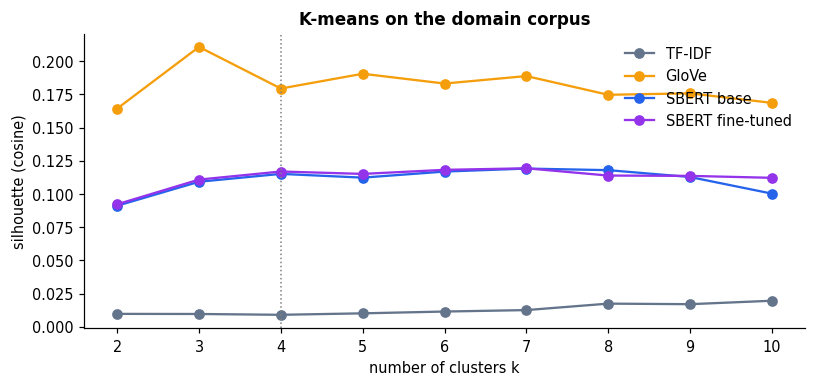

Figure 14. Silhouette score of K-means clusters for each representation
Interpretation: Silhouette values are low for every representation because short encyclopaedia summaries overlap in topic; the comparison between representations is what matters (next table).
Table 17. K-means (k = 4) agreement with the domain labels


,representation,silhouette (k=4),silhouette of true domains,NMI (k=4 vs domain),ARI (k=4 vs domain),best k (silhouette)
0,TF-IDF,0.009,0.014,0.188,0.086,10
1,GloVe,0.179,0.140,0.688,0.711,3
2,SBERT base,0.115,0.103,0.720,0.752,7
3,SBERT fine-tuned,0.117,0.104,0.711,0.728,7


Interpretation: SBERT base recovers the four domains best without any labels (NMI 0.720, ARI 0.752); TF-IDF NMI 0.188; GloVe NMI 0.688; SBERT fine-tuned NMI 0.711. A representation whose unsupervised clusters already follow the domains needs less help from anchors and thresholds.


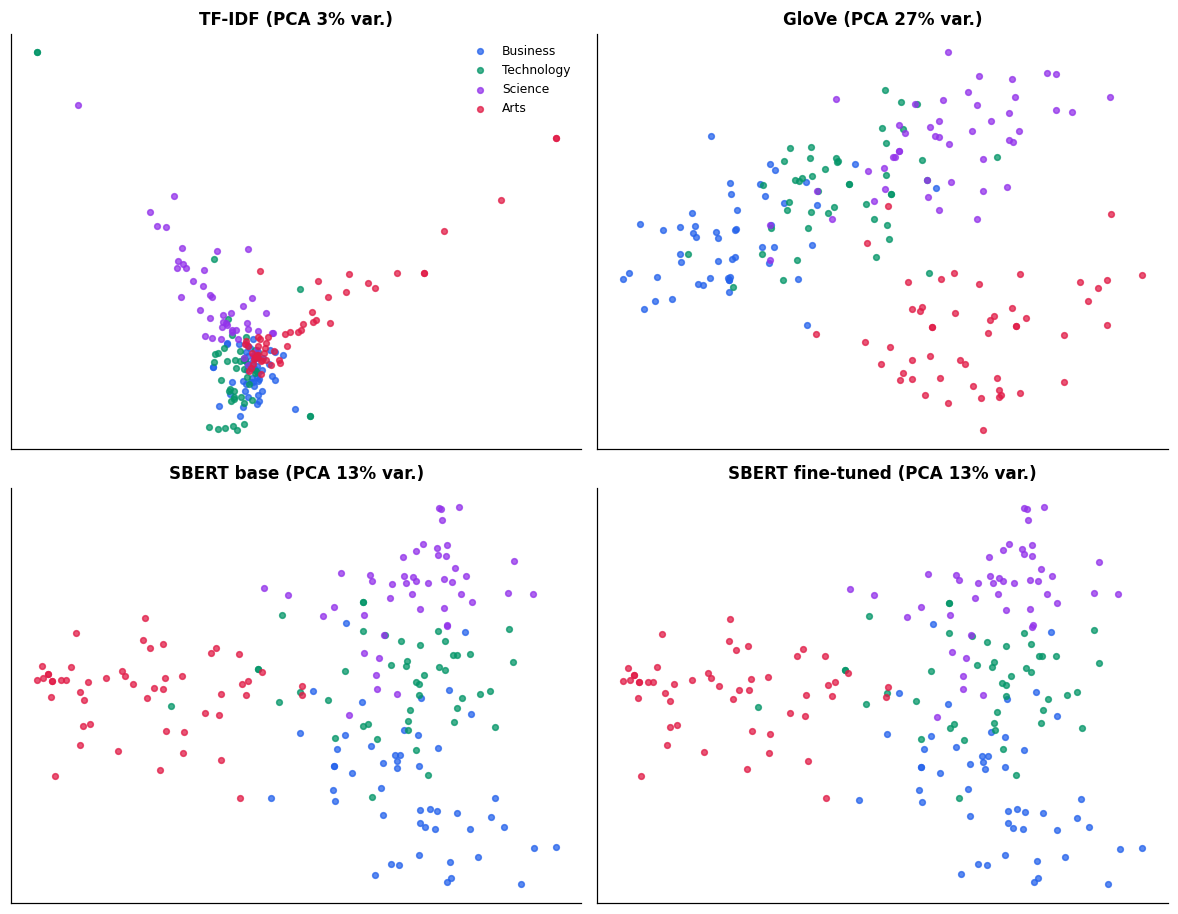

Figure 15. PCA map of the domain corpus under each representation
Interpretation: Colours are the true domains. Separation of the true domains (silhouette with the domain labels): TF-IDF 0.014, GloVe 0.140, SBERT base 0.103, SBERT fine-tuned 0.104. The 2-D view explains only part of the variance, so the clustering table is the quantitative evidence.


In [26]:
# 6.9 Alternative representations (TF-IDF + LSA, GloVe) and K-means clustering of the domain corpus
# What this cell does:
#   - TfidfLsaEncoder: classical sparse representation (TF-IDF on Pipeline A lemmas) reduced with SVD (LSA).
#   - GloveEncoder: pretrained static word vectors (glove-wiki-gigaword-100), phrase = mean of word vectors.
#   - Both expose .encode() like SentenceTransformer, so the same game engine can use them (Section 7).
#   - Clustering: K-means on the corpus documents for each representation; silhouette vs k, NMI / ARI with the
#     domain labels at k = 4, and a PCA map per representation.
_t_rep = time.perf_counter()
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize as l2_normalize

class TfidfLsaEncoder:
    """Phrase → Pipeline A lemmas → TF-IDF → LSA (TruncatedSVD)."""
    def __init__(self, fit_texts: list, dims: int = 100, seed: int = SEED):
        docs = [" ".join(lemma_of(t)) for t in fit_texts]
        self.vectorizer = TfidfVectorizer(token_pattern=r"\S+", sublinear_tf=True).fit(docs)
        matrix = self.vectorizer.transform(docs)
        self.svd = TruncatedSVD(n_components=min(dims, matrix.shape[1] - 1), random_state=seed).fit(matrix)
        self.vocabulary = set(self.vectorizer.vocabulary_)

    def get_sentence_embedding_dimension(self) -> int:
        return self.svd.n_components

    def encode(self, texts, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False, **_):
        single = isinstance(texts, str)
        texts = [texts] if single else list(texts)
        out = self.svd.transform(self.vectorizer.transform([" ".join(lemma_of(t)) for t in texts]))
        out = l2_normalize(out) if normalize_embeddings else out
        return out[0] if single else out

class GloveEncoder:
    """Phrase → mean GloVe vector of its content words (stopwords dropped unless nothing else is left)."""
    def __init__(self, keyed_vectors):
        self.kv = keyed_vectors

    def get_sentence_embedding_dimension(self) -> int:
        return self.kv.vector_size

    def _vector(self, text: str) -> np.ndarray:
        words = clean_text(text).split()
        content = [w for w in words if w not in STOP_WORDS] or words
        vecs = [self.kv[w] for w in content if w in self.kv.key_to_index]
        return np.mean(vecs, axis=0) if vecs else np.zeros(self.kv.vector_size, dtype=np.float32)

    def oov_rate(self, texts) -> float:
        words = [w for t in texts for w in clean_text(t).split()]
        return float(np.mean([w not in self.kv.key_to_index for w in words])) if words else 0.0

    def encode(self, texts, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False, **_):
        single = isinstance(texts, str)
        texts = [texts] if single else list(texts)
        out = np.array([self._vector(t) for t in texts], dtype=np.float32)
        if normalize_embeddings:
            out = l2_normalize(out)
        return out[0] if single else out

def load_glove():
    """KeyedVectors from the Drive cache or gensim-data (None on failure)."""
    cache = PATHS.root / "glove" / "glove-wiki-gigaword-100.kv"
    try:
        from gensim.models import KeyedVectors
        if cache.is_file():
            return KeyedVectors.load(str(cache), mmap="r")
        import gensim.downloader as gensim_api
        kv = gensim_api.load("glove-wiki-gigaword-100")
        if PERSISTENT:
            cache.parent.mkdir(parents=True, exist_ok=True)
            kv.save(str(cache))
        return kv
    except Exception as error:
        print(f"WARNING: GloVe could not be loaded ({type(error).__name__}: {str(error)[:120]}); GloVe rows are skipped.")
        return None

with section("6.9 Representations + clustering"):
    _lsa_fit = (corpus_df["text"].tolist() + [a for d in DOMAINS for a in DOMAIN_ANCHORS[d]]
                + [t for d in DOMAINS for t in domain_term_pool(d, DOMAIN_EXAMPLES, POOL_VOCAB, GENERIC_TERMS_V2)])
    ENCODERS = {"TF-IDF": TfidfLsaEncoder(_lsa_fit)}
    GLOVE_KV = load_glove() if RUN_GLOVE else None
    if GLOVE_KV is not None:
        ENCODERS["GloVe"] = GloveEncoder(GLOVE_KV)
    for _choice in available_model_choices():
        ENCODERS[SBERT_VARIANTS[_choice]] = load_model(_choice)[0]

    # OOV rates of the game phrases (why static vocabularies struggle)
    _oov_rows = []
    for name, phrases in _phrase_sets.items():
        row = {"phrase set": name}
        if "GloVe" in ENCODERS:
            row["GloVe OOV words"] = ENCODERS["GloVe"].oov_rate(phrases)
        words = [w for p in phrases for w in lemma_of(p)]
        row["TF-IDF vocabulary OOV lemmas"] = float(np.mean([w not in ENCODERS["TF-IDF"].vocabulary for w in words])) if words else 0.0
        row["SBERT OOV"] = 0.0   # WordPiece sub-words: no out-of-vocabulary words
        _oov_rows.append(row)
    oov_df = pd.DataFrame(_oov_rows)
    save_table(oov_df, "oov_rates", "Out-of-vocabulary rate of game phrases per representation", "Result 6 Modelling",
               "TF-IDF can only represent words seen in its fitting texts, so many player words get an empty vector; "
               "GloVe covers most single words; SBERT splits unknown words into sub-word pieces, so nothing is out of "
               "vocabulary.")

    # Document matrices for clustering
    _tfidf_doc = TfidfVectorizer(token_pattern=r"\S+", sublinear_tf=True).fit_transform(corpus_df["tokens"].map(" ".join))
    DOC_VECTORS = {"TF-IDF": l2_normalize(_tfidf_doc).toarray()}
    for name, enc in ENCODERS.items():
        if name != "TF-IDF":
            DOC_VECTORS[name] = enc.encode(corpus_df["text"].tolist())
    _y = corpus_df["domain"].to_numpy()
    cluster_rows, sil_curves = [], {}
    for name, X in DOC_VECTORS.items():
        sil_curves[name] = []
        for k in KMEANS_K_RANGE:
            labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
            sil_curves[name].append(silhouette_score(X, labels, metric="cosine"))
        labels4 = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X)
        cluster_rows.append({"representation": name, "silhouette (k=4)": silhouette_score(X, labels4, metric="cosine"),
                             "silhouette of true domains": silhouette_score(X, _y, metric="cosine"),
                             "NMI (k=4 vs domain)": normalized_mutual_info_score(_y, labels4),
                             "ARI (k=4 vs domain)": adjusted_rand_score(_y, labels4),
                             "best k (silhouette)": list(KMEANS_K_RANGE)[int(np.argmax(sil_curves[name]))]})
    cluster_df = pd.DataFrame(cluster_rows)

    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for name, curve in sil_curves.items():
        ax.plot(list(KMEANS_K_RANGE), curve, "o-", label=name, color=REPR_COLORS.get(name))
    ax.axvline(4, color="grey", ls=":", lw=1)
    ax.set_xlabel("number of clusters k")
    ax.set_xticks(list(KMEANS_K_RANGE))
    ax.set_ylabel("silhouette (cosine)")
    ax.set_title("K-means on the domain corpus")
    ax.legend(frameon=False)
    fig.tight_layout()
    save_figure(fig, "kmeans_silhouette", "Silhouette score of K-means clusters for each representation",
                "Result 6 Modelling",
                "Silhouette values are low for every representation because short encyclopaedia summaries overlap "
                "in topic; the comparison between representations is what matters (next table).")
    _best = cluster_df.loc[cluster_df["NMI (k=4 vs domain)"].idxmax()]
    save_table(cluster_df, "clustering_metrics", "K-means (k = 4) agreement with the domain labels", "Result 6 Modelling",
               f"{_best['representation']} recovers the four domains best without any labels "
               f"(NMI {_best['NMI (k=4 vs domain)']:.3f}, ARI {_best['ARI (k=4 vs domain)']:.3f}); "
               + "; ".join(f"{r['representation']} NMI {r['NMI (k=4 vs domain)']:.3f}" for r in cluster_rows
                           if r["representation"] != _best["representation"])
               + ". A representation whose unsupervised clusters already follow the domains needs less help from "
                 "anchors and thresholds.")

    n = len(DOC_VECTORS)
    cols = 2 if n > 1 else 1
    rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(5.4 * cols, 4.2 * rows_), squeeze=False)
    for ax, (name, X) in zip(axes.ravel(), DOC_VECTORS.items()):
        P = PCA(n_components=2, random_state=SEED).fit(X)
        Z = P.transform(X)
        for d in DOMAINS:
            m = _y == d
            ax.scatter(Z[m, 0], Z[m, 1], s=14, alpha=0.75, color=DOMAIN_COLORS[d], label=d)
        ax.set_title(f"{name} (PCA {P.explained_variance_ratio_.sum():.0%} var.)")
        ax.set_xticks([])
        ax.set_yticks([])
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    save_figure(fig, "pca_representations", "PCA map of the domain corpus under each representation",
                "Result 6 Modelling",
                "Colours are the true domains. Separation of the true domains (silhouette with the domain labels): "
                + ", ".join(f"{r['representation']} {r['silhouette of true domains']:.3f}" for r in cluster_rows)
                + ". The 2-D view explains only part of the variance, so the clustering table is the quantitative evidence.")
log_section("6.9 Representations", _t_rep)

## 7. Fair model comparison
Six variants; each differs from a neighbour in exactly one design choice.

Calibration saved: /content/drive/MyDrive/lexical_combat/artifacts/tuned_params_tf_idf_top_k_gate.json
  TF-IDF + top-k gate                calibration: grid search (3 s)
Calibration saved: /content/drive/MyDrive/lexical_combat/artifacts/tuned_params_glove_centroid_gate.json
  GloVe + centroid gate              calibration: grid search (3 s)
Calibration saved: /content/drive/MyDrive/lexical_combat/artifacts/tuned_params_glove_top_k_gate.json
  GloVe + top-k gate                 calibration: grid search (4 s)
Calibration saved: /content/drive/MyDrive/lexical_combat/artifacts/tuned_params_sbert_base_centroid_gate.json
  SBERT base + centroid gate         calibration: grid search (4 s)
Table 18. Fair comparison of all variants (same data, grids and cross-validation)


,ID,Model,Gate macro F1 (tuned),Gate macro F1 (CV),In-domain primary (CV),Ambiguous pass (CV),Out-of-domain leak (CV),Damage in-band (tuned),Damage in-band (CV),AUC related vs noise,Gate AUC in vs out,Anisotropy
0,M1,TF-IDF + top-k gate,0.466,0.417,0.277,0.310,0.021,0.44,0.42,0.710,0.608,0.000
1,M2,GloVe + centroid gate,0.693,0.684,0.857,0.552,0.040,0.70,0.72,0.992,0.888,0.231
2,M3,GloVe + top-k gate,0.730,0.730,0.911,0.552,0.037,0.68,0.66,0.992,0.903,0.231
3,M4,SBERT base + centroid gate,0.674,0.636,0.795,0.483,0.034,0.66,0.68,0.990,0.930,0.291
4,M5,SBERT base,0.705,0.663,0.848,0.483,0.046,0.64,0.60,0.990,0.952,0.291
5,M6,SBERT fine-tuned,0.707,0.670,0.866,0.483,0.043,0.64,0.60,0.992,0.953,0.281


Interpretation: CV = cross-validated (5-fold grouped for the gate, leave-one-target-out for damage). Best CV gate macro F1: GloVe + top-k gate (0.730); best CV damage in-band: GloVe + centroid gate (0.720).


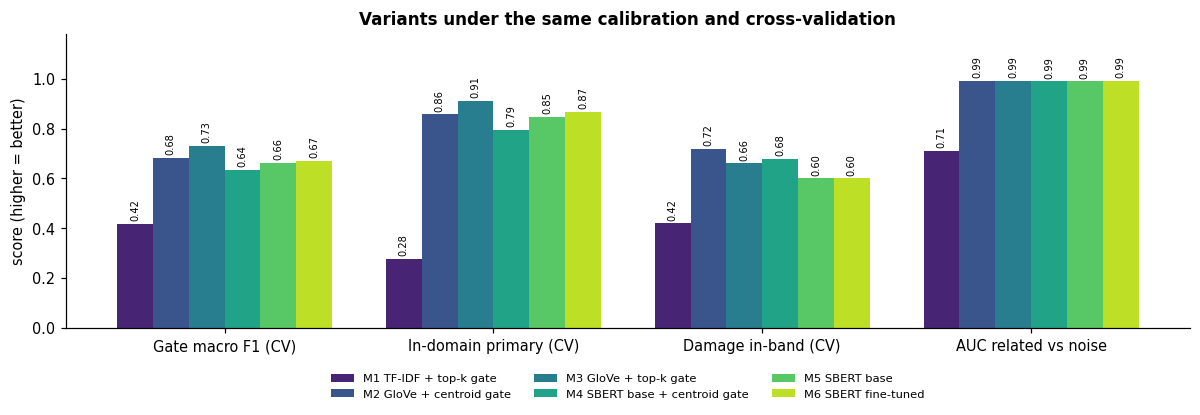

Figure 16. Cross-validated gate and damage quality of each variant
Interpretation: Bars in each group differ by one design choice at a time, so a gap between neighbouring bars can be attributed to that choice (representation or gate method).
Table 19. Effect of changing one design choice (difference in CV metric)


metric,effect,Damage in-band (CV),Gate macro F1 (CV),In-domain primary (CV)
0,GloVe vs TF-IDF (top-k gate),0.24,0.313,0.634
1,SBERT vs GloVe (centroid gate),-0.04,-0.048,-0.062
2,SBERT vs GloVe (top-k gate),-0.06,-0.068,-0.062
3,fine-tuned vs base SBERT,0.00,0.007,0.018
4,top-k vs centroid gate (GloVe),-0.06,0.046,0.054
5,top-k vs centroid gate (SBERT),-0.08,0.027,0.054


Interpretation: The largest gain in CV gate macro F1 comes from 'GloVe vs TF-IDF (top-k gate)' (+0.313); the smallest from 'SBERT vs GloVe (top-k gate)' (-0.068). Positive = the first option is better.


In [27]:
# 7. Fair model comparison: change one thing at a time (representation × domain-gate method)
# What this cell does:
#   - Every variant uses the same data, the same engine, the same grids and the same cross-validation.
#     Only the encoder (TF-IDF / GloVe / SBERT base / SBERT fine-tuned) or the gate method changes:
#       centroid gate = cosine to the mean anchor vector of each domain;
#       top-k gate    = mean of the k most similar anchor sentences (the game's method).
#     Both gates subtract each domain's background score on everyday nouns (debiasing).
#   - Model choice uses cross-validated numbers only; the holdout stays untouched until Section 11.
_t_cmp = time.perf_counter()

class CentroidGateEngine(LexicalCombatEngine):
    """Same engine, but each domain is represented by one centroid vector instead of 8 anchor sentences."""
    def refresh(self, model=None) -> None:
        super().refresh(model)
        for dom in self.data.domains:
            centroid = self.anchor_vectors[dom].mean(axis=0)
            self.anchor_vectors[dom] = (centroid / max(np.linalg.norm(centroid), 1e-12))[None, :]
        self.background_by_k = {k: {dom: float((self.noise_vectors @ self.anchor_vectors[dom].T).mean())
                                    for dom in self.data.domains} for k in (1, 2, 3, 4, 5)}

VARIANT_PLAN = [   # (id, variant name, encoder key, engine class)
    ("M1", "TF-IDF + top-k gate", "TF-IDF", LexicalCombatEngine),
    ("M2", "GloVe + centroid gate", "GloVe", CentroidGateEngine),
    ("M3", "GloVe + top-k gate", "GloVe", LexicalCombatEngine),
    ("M4", "SBERT base + centroid gate", "SBERT base", CentroidGateEngine),
    ("M5", "SBERT base", "SBERT base", LexicalCombatEngine),
    ("M6", "SBERT fine-tuned", "SBERT fine-tuned", LexicalCombatEngine),
]
VARIANT_ID = {}

with section("7. Fair comparison"):
    for vid, name, enc_key, cls in VARIANT_PLAN:
        if enc_key not in ENCODERS:
            print(f"  {vid} {name}: skipped ({enc_key} not available)")
            continue
        VARIANT_ID[name] = vid
        if name not in CALIBRATED:
            calibrated_engine(name, ENCODERS[enc_key], f"{enc_key}|{cls.__name__}", cls)
    compare_rows = []
    for name, vid in VARIANT_ID.items():
        eng = CALIBRATED[name]["engine"]
        im = INTRINSIC.get(name) or intrinsic_metrics(eng)
        INTRINSIC[name] = im
        compare_rows.append({"ID": vid, **calibration_row(name),
                             "AUC related vs noise": im["AUC related vs noise"],
                             "Gate AUC in vs out": im["Gate AUC in vs out (debiased score)"],
                             "Anisotropy": im["Anisotropy (noise-pair mean cos)"]})
    comparison_df = pd.DataFrame(compare_rows)
    save_table(comparison_df.drop(columns=["All pacing goals met (tuned)"]), "fair_comparison",
               "Fair comparison of all variants (same data, grids and cross-validation)", "Result 7 Model comparison",
               "CV = cross-validated (5-fold grouped for the gate, leave-one-target-out for damage). "
               f"Best CV gate macro F1: {comparison_df.loc[comparison_df['Gate macro F1 (CV)'].idxmax(), 'Model']} "
               f"({comparison_df['Gate macro F1 (CV)'].max():.3f}); best CV damage in-band: "
               f"{comparison_df.loc[comparison_df['Damage in-band (CV)'].idxmax(), 'Model']} "
               f"({comparison_df['Damage in-band (CV)'].max():.3f}).")

    _metrics = ["Gate macro F1 (CV)", "In-domain primary (CV)", "Damage in-band (CV)", "AUC related vs noise"]
    fig, ax = plt.subplots(figsize=(11, 3.9))
    width = 0.8 / len(comparison_df)
    palette = plt.cm.viridis(np.linspace(0.1, 0.9, len(comparison_df)))
    for i, row in enumerate(comparison_df.itertuples(index=False)):
        vals = [comparison_df.iloc[i][m] for m in _metrics]
        bars = ax.bar(np.arange(len(_metrics)) + (i - (len(comparison_df) - 1) / 2) * width, vals, width,
                      label=f"{row.ID} {row.Model}", color=palette[i])
        ax.bar_label(bars, fmt="%.2f", fontsize=6.5, rotation=90, padding=2)
    ax.set_xticks(range(len(_metrics)), _metrics)
    ax.set_ylim(0, 1.18)
    ax.set_ylabel("score (higher = better)")
    ax.set_title("Variants under the same calibration and cross-validation")
    ax.legend(frameon=False, fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    save_figure(fig, "fair_comparison", "Cross-validated gate and damage quality of each variant",
                "Result 7 Model comparison",
                "Bars in each group differ by one design choice at a time, so a gap between neighbouring bars can be "
                "attributed to that choice (representation or gate method).")

    # One-factor effects (2 × 2 design: GloVe / SBERT × centroid / top-k)
    def _cv(name, col="Gate macro F1 (CV)"):
        r = comparison_df[comparison_df["Model"] == name]
        return float(r[col].iloc[0]) if len(r) else np.nan
    effect_rows = []
    for col in ["Gate macro F1 (CV)", "In-domain primary (CV)", "Damage in-band (CV)"]:
        effect_rows += [
            {"metric": col, "effect": "top-k vs centroid gate (GloVe)",
             "Δ": _cv("GloVe + top-k gate", col) - _cv("GloVe + centroid gate", col)},
            {"metric": col, "effect": "top-k vs centroid gate (SBERT)",
             "Δ": _cv("SBERT base", col) - _cv("SBERT base + centroid gate", col)},
            {"metric": col, "effect": "SBERT vs GloVe (top-k gate)", "Δ": _cv("SBERT base", col) - _cv("GloVe + top-k gate", col)},
            {"metric": col, "effect": "SBERT vs GloVe (centroid gate)",
             "Δ": _cv("SBERT base + centroid gate", col) - _cv("GloVe + centroid gate", col)},
            {"metric": col, "effect": "fine-tuned vs base SBERT", "Δ": _cv("SBERT fine-tuned", col) - _cv("SBERT base", col)},
            {"metric": col, "effect": "GloVe vs TF-IDF (top-k gate)", "Δ": _cv("GloVe + top-k gate", col) - _cv("TF-IDF + top-k gate", col)},
        ]
    effects_df = pd.DataFrame(effect_rows).dropna().pivot(index="effect", columns="metric", values="Δ")
    _eff = effects_df["Gate macro F1 (CV)"].dropna() if "Gate macro F1 (CV)" in effects_df else pd.Series(dtype=float)
    save_table(effects_df, "one_factor_effects", "Effect of changing one design choice (difference in CV metric)",
               "Result 7 Model comparison",
               (f"The largest gain in CV gate macro F1 comes from '{_eff.idxmax()}' ({_eff.max():+.3f}); "
                f"the smallest from '{_eff.idxmin()}' ({_eff.min():+.3f}). Positive = the first option is better."
                if len(_eff) else "Not enough variants were available for the effect table."), index=True)
log_section("7. Fair comparison", _t_cmp)

## 8. Similarity analysis

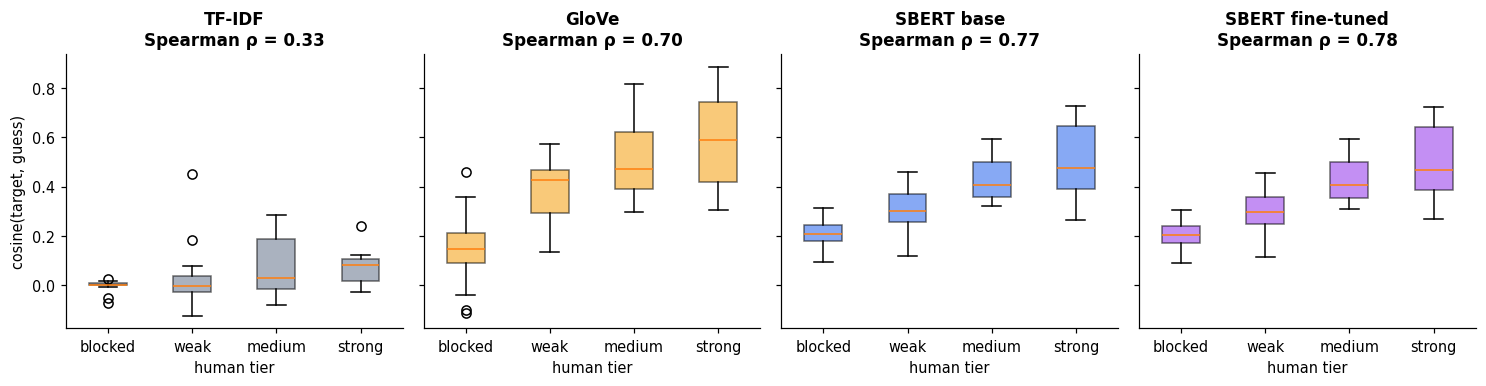

Figure 17. Cosine similarity of the 50 banded cases grouped by the human damage tier
Interpretation: SBERT fine-tuned follows the human ordering best (ρ = 0.78). Overlapping boxes between neighbouring tiers show why a fixed cosine cut-off cannot separate tiers for every target.
Table 20. Agreement between similarity and human tiers


,representation,Spearman ρ (raw cosine vs tier),Spearman ρ (normalised r vs tier),AUC related vs noise,mean cos strong,mean cos blocked
0,TF-IDF,0.330,0.427,0.710,0.072,-0.004
1,GloVe,0.698,0.714,0.992,0.584,0.142
2,SBERT base,0.775,0.810,0.990,0.504,0.206
3,SBERT fine-tuned,0.785,0.815,0.992,0.503,0.199


Interpretation: Normalising cosine per target (r) changes the rank correlation by TF-IDF +0.10, GloVe +0.02, SBERT base +0.04, SBERT fine-tuned +0.03; r mainly removes target-specific offsets so that the same damage curve works for every boss.


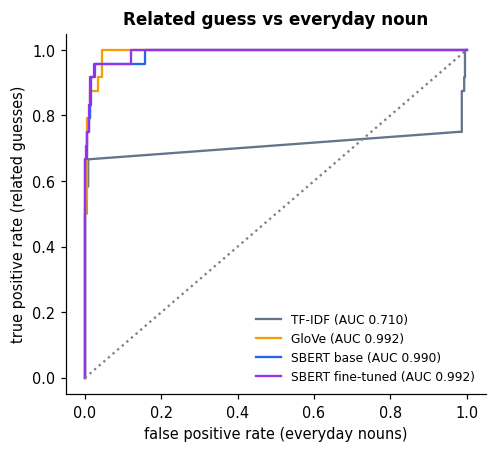

Figure 18. ROC: cosine separates related guesses from everyday nouns
Interpretation: A high AUC means a noise floor taken from everyday nouns sits below almost all genuinely related guesses, which is exactly what the damage normalisation relies on.


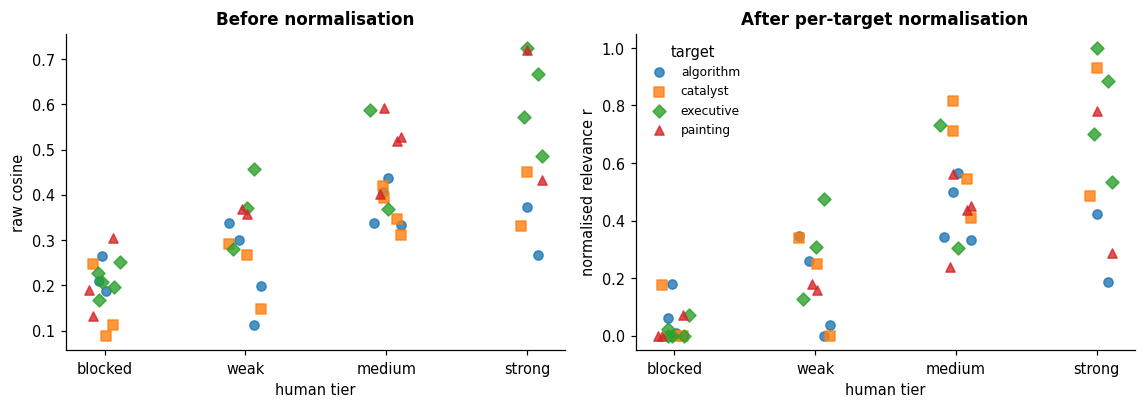

Figure 19. Raw cosine vs normalised relevance per target (SBERT fine-tuned)
Interpretation: Noise floors differ by target (algorithm 0.18, catalyst 0.20, executive 0.21, painting 0.26), so the same raw cosine means different things for different bosses. Normalising to r puts all targets on one 0–1 scale before the damage curve is applied.


In [28]:
# 8. Similarity analysis: does cosine similarity follow human judgement?
# What this cell does:
#   - For each representation: cosine(target, guess) of the 50 banded cases grouped by the human tier
#     (box plot), Spearman rank correlation with the tier, ROC of related guesses vs everyday nouns.
#   - Raw cosine vs normalised relevance r = (cos − noise floor) / (ceiling − noise floor): shows why the
#     game normalises per target before mapping to damage.
_t_sim = time.perf_counter()
TIER_RANK = {t: i for i, t in enumerate(TIER_ORDER)}
SIM_VARIANTS = [v for v in ["TF-IDF + top-k gate", "GloVe + top-k gate", "SBERT base", "SBERT fine-tuned"] if v in CALIBRATED]
SHORT_NAME = {"TF-IDF + top-k gate": "TF-IDF", "GloVe + top-k gate": "GloVe", "SBERT base": "SBERT base",
              "SBERT fine-tuned": "SBERT fine-tuned"}

def pair_table(eng) -> pd.DataFrame:
    """Cosine, noise floor, ceiling and r for every banded case."""
    rows = []
    for row in damage_cases_df.itertuples(index=False):
        cal = eng.target_calibration(row.target, row.required_domain)
        cos = float(eng.encode([clean_text(row.guess)])[0] @ cal["vector"])
        noise, ceiling = eng.bounds(cal)
        rows.append({"target": row.target, "guess": row.guess, "tier": row.human_expected_tier,
                     "cos": cos, "noise": noise, "ceiling": ceiling,
                     "r": float(normalized_relevance(cos, noise, ceiling))})
    return pd.DataFrame(rows)

with section("8. Similarity analysis"):
    PAIRS = {v: pair_table(CALIBRATED[v]["engine"]) for v in SIM_VARIANTS}
    fig, axes = plt.subplots(1, len(PAIRS), figsize=(3.4 * len(PAIRS), 3.6), sharey=True, squeeze=False)
    sim_rows = []
    for ax, (v, df) in zip(axes[0], PAIRS.items()):
        data = [df.loc[df["tier"] == t, "cos"] for t in TIER_ORDER]
        bp = ax.boxplot(data, patch_artist=True)
        ax.set_xticks(range(1, len(TIER_ORDER) + 1), TIER_ORDER)
        for patch in bp["boxes"]:
            patch.set_facecolor(REPR_COLORS.get(SHORT_NAME[v], "#64748b"))
            patch.set_alpha(0.55)
        rho_cos = spearmanr(df["cos"], df["tier"].map(TIER_RANK)).correlation
        rho_r = spearmanr(df["r"], df["tier"].map(TIER_RANK)).correlation
        ax.set_title(f"{SHORT_NAME[v]}\nSpearman ρ = {rho_cos:.2f}")
        ax.set_xlabel("human tier")
        sim_rows.append({"representation": SHORT_NAME[v], "Spearman ρ (raw cosine vs tier)": rho_cos,
                         "Spearman ρ (normalised r vs tier)": rho_r,
                         "AUC related vs noise": INTRINSIC[v]["AUC related vs noise"],
                         "mean cos strong": df.loc[df["tier"] == "strong", "cos"].mean(),
                         "mean cos blocked": df.loc[df["tier"] == "blocked", "cos"].mean()})
    axes[0, 0].set_ylabel("cosine(target, guess)")
    fig.tight_layout()
    similarity_df = pd.DataFrame(sim_rows)
    _b = similarity_df.loc[similarity_df["Spearman ρ (raw cosine vs tier)"].idxmax()]
    save_figure(fig, "cosine_by_tier", "Cosine similarity of the 50 banded cases grouped by the human damage tier",
                "Result 8 Similarity analysis",
                f"{_b['representation']} follows the human ordering best (ρ = {_b['Spearman ρ (raw cosine vs tier)']:.2f}). "
                "Overlapping boxes between neighbouring tiers show why a fixed cosine cut-off cannot separate tiers "
                "for every target.")
    save_table(similarity_df, "similarity_vs_human", "Agreement between similarity and human tiers",
               "Result 8 Similarity analysis",
               "Normalising cosine per target (r) changes the rank correlation by "
               + ", ".join(f"{r['representation']} {r['Spearman ρ (normalised r vs tier)'] - r['Spearman ρ (raw cosine vs tier)']:+.2f}"
                           for r in sim_rows)
               + "; r mainly removes target-specific offsets so that the same damage curve works for every boss.")

    # ROC: related guesses (strong / medium) vs everyday nouns
    fig, ax = plt.subplots(figsize=(4.6, 4.2))
    for v in SIM_VARIANTS:
        eng, df = CALIBRATED[v]["engine"], PAIRS[v]
        pos = df.loc[df["tier"].isin(["strong", "medium"]), "cos"].to_numpy()
        neg = np.concatenate([eng.target_calibration(t, d)["noise_sims"]
                              for t, d in set(zip(damage_cases_df["target"], damage_cases_df["required_domain"]))])
        fpr, tpr, _ = roc_curve(np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos, neg])
        ax.plot(fpr, tpr, label=f"{SHORT_NAME[v]} (AUC {INTRINSIC[v]['AUC related vs noise']:.3f})",
                color=REPR_COLORS.get(SHORT_NAME[v]))
    ax.plot([0, 1], [0, 1], ls=":", color="grey")
    ax.set_xlabel("false positive rate (everyday nouns)")
    ax.set_ylabel("true positive rate (related guesses)")
    ax.set_title("Related guess vs everyday noun")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    save_figure(fig, "roc_related_vs_noise", "ROC: cosine separates related guesses from everyday nouns",
                "Result 8 Similarity analysis",
                "A high AUC means a noise floor taken from everyday nouns sits below almost all genuinely related "
                "guesses, which is exactly what the damage normalisation relies on.")

    # Raw cosine vs normalised r for the best SBERT model
    _sb = "SBERT fine-tuned" if "SBERT fine-tuned" in PAIRS else "SBERT base"
    df = PAIRS[_sb]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
    for t, mk in zip(sorted(df["target"].unique()), "osD^"):
        m = df["target"] == t
        ax1.scatter(df.loc[m, "tier"].map(TIER_RANK) + np.random.default_rng(1).uniform(-0.12, 0.12, m.sum()),
                    df.loc[m, "cos"], marker=mk, label=t, alpha=0.8)
        ax2.scatter(df.loc[m, "tier"].map(TIER_RANK) + np.random.default_rng(1).uniform(-0.12, 0.12, m.sum()),
                    df.loc[m, "r"], marker=mk, label=t, alpha=0.8)
    for ax, lab in ((ax1, "raw cosine"), (ax2, "normalised relevance r")):
        ax.set_xticks(range(len(TIER_ORDER)), TIER_ORDER)
        ax.set_ylabel(lab)
        ax.set_xlabel("human tier")
    ax1.set_title("Before normalisation")
    ax2.set_title("After per-target normalisation")
    ax2.legend(frameon=False, fontsize=8, title="target")
    fig.tight_layout()
    _bounds = df.groupby("target")[["noise", "ceiling"]].first()
    save_figure(fig, "raw_vs_normalised", f"Raw cosine vs normalised relevance per target ({_sb})",
                "Result 8 Similarity analysis",
                "Noise floors differ by target ("
                + ", ".join(f"{t} {r.noise:.2f}" for t, r in _bounds.iterrows())
                + "), so the same raw cosine means different things for different bosses. Normalising to r puts all "
                  "targets on one 0–1 scale before the damage curve is applied.")
log_section("8. Similarity analysis", _t_sim)

## 9. Calibration results

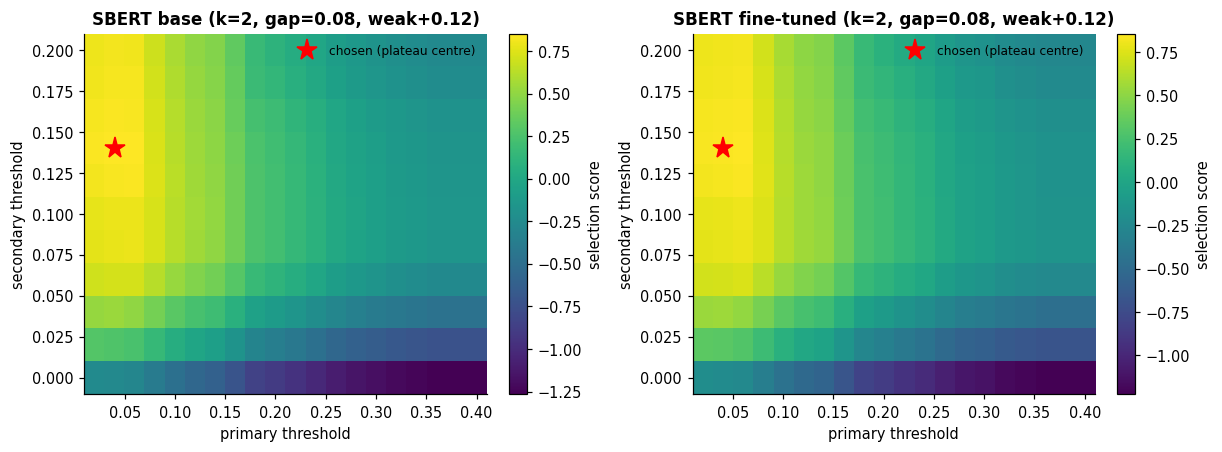

Figure 20. Gate grid search: selection score over the primary and secondary thresholds
Interpretation: The chosen point (red star) is the centre of a flat high-score region (plateau), not the single best cell, so small changes in the data do not move the decision much. SBERT base: primary ≥ 0.04, secondary ≥ 0.14 | SBERT fine-tuned: primary ≥ 0.04, secondary ≥ 0.14


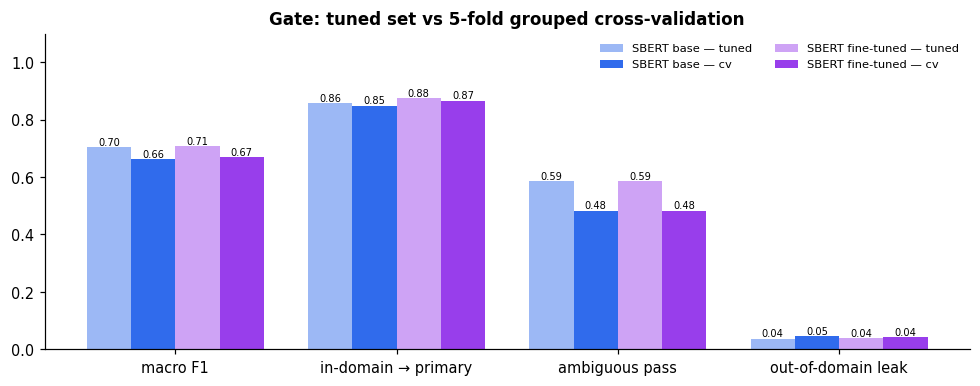

Figure 21. Gate metrics on the tuned set and under 5-fold grouped cross-validation
Interpretation: The drop from tuned to CV is the optimism of choosing thresholds on the same rows; SBERT base: macro F1 −0.042 | SBERT fine-tuned: macro F1 −0.038. A small drop means the thresholds generalise to phrases not used for tuning.


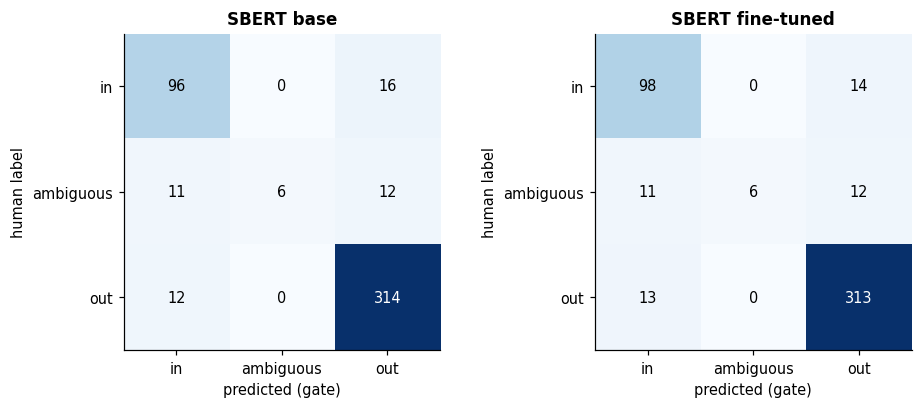

Figure 22. Gate confusion matrix on the 467-row gate tuning set (tuned thresholds)
Interpretation: For SBERT fine-tuned the largest error cell is human 'in_domain' → predicted 'out_of_domain' (14 rows). Only 6/29 ambiguous phrases are recognised as ambiguous: they belong partly to two domains, so the gate tends to call them fully in or fully out. Leaks (human 'out' → predicted in / ambiguous) total 13 rows.


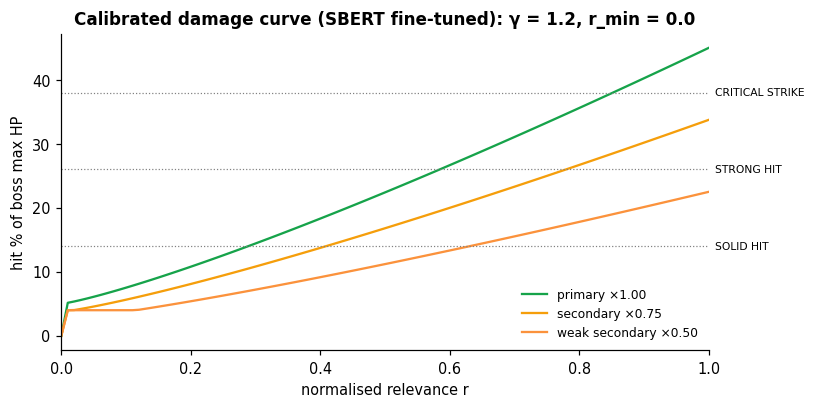

Figure 23. Calibrated damage curve: hit % as a function of relevance r per gate result
Interpretation: hit % = 5 + (45 − 5) · ((r − r_min)/(1 − r_min))^1.2, capped at 45%. γ > 1 makes the curve stricter in the middle, so only clearly relevant guesses reach STRONG / CRITICAL.


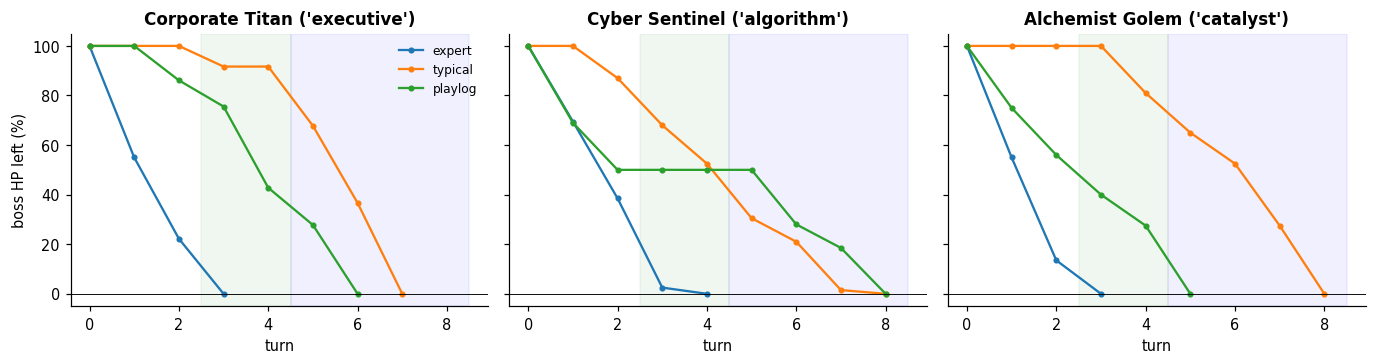

Figure 24. Boss HP per turn for the reference plays (SBERT fine-tuned)
Interpretation: 6/6 pacing goals are met (expert 3–4 turns, typical 5–8; shaded bands). A good player finishes a boss quickly, an average player needs more turns, and nobody wins in one hit because of the per-hit cap.
Table 21. Battle pacing per stage and play style


,model,Enemy,Play,Goal turns,Goal met,Turns to defeat,Critical,Strong,Solid,Graze,No effect / blocked
0,SBERT base,Corporate Titan,expert,3–4,True,4,1,2,1,0,0
1,SBERT base,Corporate Titan,typical,5–8,True,8,0,2,1,2,3
2,SBERT base,Corporate Titan,playlog,—,—,6,0,2,1,2,1
3,SBERT base,Cyber Sentinel,expert,3–4,True,4,0,3,1,0,0
4,SBERT base,Cyber Sentinel,typical,5–8,True,8,0,1,4,2,1
5,SBERT base,Cyber Sentinel,playlog,—,—,8,0,1,3,1,3
6,SBERT base,Alchemist Golem,expert,3–4,True,3,2,0,1,0,0
7,SBERT base,Alchemist Golem,typical,5–8,True,8,1,0,3,1,3
8,SBERT base,Alchemist Golem,playlog,—,—,5,1,0,3,1,0
0,SBERT fine-tuned,Corporate Titan,expert,3–4,True,3,1,1,1,0,0


In [29]:
# 9. Calibration results: gate thresholds, confusion matrix, damage curve, battle pacing
# What this cell does:
#   - Gate grid heatmap (primary × secondary threshold at the chosen k / gap) with the chosen point.
#   - Tuned vs cross-validated gate metrics and the confusion matrix on the gate tuning set.
#   - The calibrated damage curve (hit % vs r) with tier cut-offs, per gate result.
#   - Battle pacing: boss HP after each turn for the expert / typical reference plays.
_t_cal = time.perf_counter()
SBERT_NAMES = [v for v in SBERT_VARIANTS.values() if v in CALIBRATED]

def gate_grid_surface(eng, grid_params) -> np.ndarray:
    """Selection score over primary × secondary with k / gap / weak_extra fixed at the chosen values."""
    frame = gate_set_df
    y = frame["label"].map(LABEL_CODE).to_numpy()
    inp = gate_inputs(eng, frame, [grid_params["k"]])[grid_params["k"]]
    pred = grid_predictions(inp["required"], inp["lead"])
    met = grid_metrics(pred, y, np.ones(len(frame), dtype=bool))
    shape = [len(a) for a in _grid_axes()]
    score = met["score"].reshape(shape)
    gi = GATE_GRID["gap"].index(grid_params["gap"])
    wi = GATE_GRID["weak_extra"].index(grid_params["weak_extra"])
    return score[:, :, gi, wi]

def pacing_table(eng) -> pd.DataFrame:
    """Turns to defeat each boss for the reference plays and the play log (as in the main notebook)."""
    rows, curves = [], []
    for stage in GAME_STAGES:
        t = stage["target"]
        plays = {style: guesses for style, (guesses, _) in REFERENCE_PLAYS[t].items()}
        plays["playlog"] = PLAYER_LOG_GUESSES_V2[t]
        for style, guesses in plays.items():
            battle = eng.simulate_battle(t, stage["domain"], stage["hp"], guesses)
            rng = REFERENCE_PLAYS[t].get(style, (None, None))[1]
            summary = eng.summarize_battle(battle, stage["hp"])
            met = (rng is not None and summary["Turns to defeat"] is not None and rng[0] <= summary["Turns to defeat"] <= rng[1])
            rows.append({"Stage": stage["stage"], "Enemy": stage["enemy"], "Target": t, "Play": style,
                         "Goal turns": f"{rng[0]}–{rng[1]}" if rng else "—", "Goal met": met if rng else "—", **summary})
            valid = battle[battle["Tier"] != "INVALID"]
            curves.append({"target": t, "style": style, "hp0": stage["hp"],
                           "hp": [stage["hp"]] + valid["HP left"].tolist()})
    return pd.DataFrame(rows), curves

with section("9. Calibration results"):
    PACING = {v: pacing_table(CALIBRATED[v]["engine"]) for v in SBERT_NAMES}

    # Gate grid heatmaps
    fig, axes = plt.subplots(1, len(SBERT_NAMES), figsize=(5.6 * len(SBERT_NAMES), 4.2), squeeze=False)
    for ax, v in zip(axes[0], SBERT_NAMES):
        gp = CALIBRATED[v]["gate"]["grid_params"]
        surf = gate_grid_surface(CALIBRATED[v]["engine"], gp)
        im = ax.imshow(surf.T, origin="lower", aspect="auto", cmap="viridis",
                       extent=[GATE_GRID["primary"][0] - 0.01, GATE_GRID["primary"][-1] + 0.01,
                               GATE_GRID["secondary"][0] - 0.01, GATE_GRID["secondary"][-1] + 0.01])
        ax.plot(gp["primary"], gp["secondary"], "r*", ms=14, label="chosen (plateau centre)")
        ax.set_xlabel("primary threshold")
        ax.set_ylabel("secondary threshold")
        ax.set_title(f"{v} (k={gp['k']}, gap={gp['gap']}, weak+{gp['weak_extra']})")
        fig.colorbar(im, ax=ax, fraction=0.046, label="selection score")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout()
    save_figure(fig, "gate_grid_heatmap", "Gate grid search: selection score over the primary and secondary thresholds",
                "Result 9 Calibration",
                "The chosen point (red star) is the centre of a flat high-score region (plateau), not the single best "
                "cell, so small changes in the data do not move the decision much. "
                + " | ".join(f"{v}: primary ≥ {CALIBRATED[v]['gate']['grid_params']['primary']:.2f}, secondary ≥ "
                             f"{CALIBRATED[v]['gate']['grid_params']['secondary']:.2f}" for v in SBERT_NAMES))

    # Tuned vs CV
    _gm = ["macro_f1", "in_domain_primary", "ambiguous_pass", "out_leak"]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    width = 0.8 / (2 * len(SBERT_NAMES))
    i = 0
    for v in SBERT_NAMES:
        for split, alpha in (("tuned", 0.45), ("cv", 0.95)):
            vals = [CALIBRATED[v]["gate"][split][m] for m in _gm]
            bars = ax.bar(np.arange(len(_gm)) + (i - (2 * len(SBERT_NAMES) - 1) / 2) * width, vals, width,
                          color=REPR_COLORS[v], alpha=alpha, label=f"{v} — {split}")
            ax.bar_label(bars, fmt="%.2f", fontsize=6.5)
            i += 1
    ax.set_xticks(range(len(_gm)), ["macro F1", "in-domain → primary", "ambiguous pass", "out-of-domain leak"])
    ax.set_ylim(0, 1.1)
    ax.legend(frameon=False, fontsize=7.5, ncol=2)
    ax.set_title("Gate: tuned set vs 5-fold grouped cross-validation")
    fig.tight_layout()
    save_figure(fig, "gate_tuned_vs_cv", "Gate metrics on the tuned set and under 5-fold grouped cross-validation",
                "Result 9 Calibration",
                "The drop from tuned to CV is the optimism of choosing thresholds on the same rows; "
                + " | ".join(f"{v}: macro F1 −{CALIBRATED[v]['gate']['tuned']['macro_f1'] - CALIBRATED[v]['gate']['cv']['macro_f1']:.3f}"
                             for v in SBERT_NAMES)
                + ". A small drop means the thresholds generalise to phrases not used for tuning.")

    # Confusion matrices
    fig, axes = plt.subplots(1, len(SBERT_NAMES), figsize=(4.4 * len(SBERT_NAMES), 3.8), squeeze=False)
    for ax, v in zip(axes[0], SBERT_NAMES):
        sc = CALIBRATED[v]["gate"]["scored"]
        cm = pd.crosstab(sc["label"], sc["predicted"]).reindex(index=LABELS, columns=LABELS, fill_value=0)
        ax.imshow(cm.values, cmap="Blues")
        ax.set_xticks(range(3), ["in", "ambiguous", "out"])
        ax.set_yticks(range(3), ["in", "ambiguous", "out"])
        for a in range(3):
            for b in range(3):
                ax.text(b, a, cm.iat[a, b], ha="center", va="center",
                        color="white" if cm.iat[a, b] > cm.values.max() / 2 else "black")
        ax.set_xlabel("predicted (gate)")
        ax.set_ylabel("human label")
        ax.set_title(v)
    fig.tight_layout()
    _sc = CALIBRATED[SBERT_NAMES[-1]]["gate"]["scored"]
    _cm = pd.crosstab(_sc["label"], _sc["predicted"]).reindex(index=LABELS, columns=LABELS, fill_value=0)
    _off = _cm.where(~np.eye(3, dtype=bool)).stack()
    _worst = _off.idxmax()
    _amb_n = int((_sc["label"] == "ambiguous").sum())
    _amb_ok = int(_cm.loc["ambiguous", "ambiguous"])
    save_figure(fig, "gate_confusion", f"Gate confusion matrix on the {len(gate_set_df)}-row gate tuning set (tuned thresholds)",
                "Result 9 Calibration",
                f"For {SBERT_NAMES[-1]} the largest error cell is human '{_worst[0]}' → predicted '{_worst[1]}' "
                f"({int(_off.max())} rows). Only {_amb_ok}/{_amb_n} ambiguous phrases are recognised as ambiguous: they belong "
                "partly to two domains, so the gate tends to call them fully in or fully out. Leaks (human 'out' → "
                f"predicted in / ambiguous) total {int(_cm.loc['out_of_domain', ['in_domain', 'ambiguous']].sum())} rows.")

    # Damage curve
    eng = CALIBRATED[SBERT_NAMES[-1]]["engine"]
    r = np.linspace(0, 1, 101)
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    for kind, mult, color in (("primary", 1.0, "#16a34a"), ("secondary", eng.config.domain_secondary_multiplier, "#f59e0b"),
                              ("weak secondary", eng.config.domain_weak_secondary_multiplier, "#fb923c")):
        ax.plot(r, eng.hit_percent(r, mult, True), color=color, label=f"{kind} ×{mult:.2f}")
    for cut, name in eng.config.tier_cuts:
        ax.axhline(cut, ls=":", color="grey", lw=0.8)
        ax.text(1.01, cut, name, fontsize=7, va="center")
    ax.set_xlabel("normalised relevance r")
    ax.set_ylabel("hit % of boss max HP")
    ax.set_xlim(0, 1)
    ax.set_title(f"Calibrated damage curve ({SBERT_NAMES[-1]}): γ = {eng.config.damage_gamma}, "
                 f"r_min = {eng.config.relevance_min}")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    save_figure(fig, "damage_curve", "Calibrated damage curve: hit % as a function of relevance r per gate result",
                "Result 9 Calibration",
                f"hit % = {eng.config.graze_min_percent:g} + ({eng.config.max_hit_percent:g} − {eng.config.graze_min_percent:g}) · "
                f"((r − r_min)/(1 − r_min))^{eng.config.damage_gamma}, capped at {eng.config.max_hit_percent:g}%. "
                "γ > 1 makes the curve stricter in the middle, so only clearly relevant guesses reach STRONG / CRITICAL.")

    # Pacing curves
    _pc = PACING[SBERT_NAMES[-1]][1]
    fig, axes = plt.subplots(1, len(GAME_STAGES), figsize=(4.2 * len(GAME_STAGES), 3.4), sharey=True, squeeze=False)
    for ax, stage in zip(axes[0], GAME_STAGES):
        for c in [c for c in _pc if c["target"] == stage["target"]]:
            ax.plot(range(len(c["hp"])), np.array(c["hp"]) / c["hp0"] * 100, "o-", ms=3, label=c["style"])
        rngs = {s: rr for s, (_, rr) in REFERENCE_PLAYS[stage["target"]].items()}
        for s, (lo, hi) in rngs.items():
            ax.axvspan(lo - 0.5, hi + 0.5, alpha=0.06, color="green" if s == "expert" else "blue")
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(f"{stage['enemy']} ('{stage['target']}')")
        ax.set_xlabel("turn")
    axes[0, 0].set_ylabel("boss HP left (%)")
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    _pd = PACING[SBERT_NAMES[-1]][0]
    _goals = _pd[_pd["Goal met"] != "—"]
    save_figure(fig, "pacing_curves", f"Boss HP per turn for the reference plays ({SBERT_NAMES[-1]})",
                "Result 9 Calibration",
                f"{int((_goals['Goal met'] == True).sum())}/{len(_goals)} pacing goals are met (expert 3–4 turns, "
                "typical 5–8; shaded bands). A good player finishes a boss quickly, an average player needs more "
                "turns, and nobody wins in one hit because of the per-hit cap.")
    save_table(pd.concat({v: PACING[v][0] for v in SBERT_NAMES}, names=["model"]).reset_index(level=0)
               [["model", "Enemy", "Play", "Goal turns", "Goal met", "Turns to defeat", "Critical", "Strong", "Solid", "Graze",
                 "No effect / blocked"]],
               "pacing", "Battle pacing per stage and play style", "Result 9 Calibration")
log_section("9. Calibration results", _t_cal)

## 10. Fine-tuning results

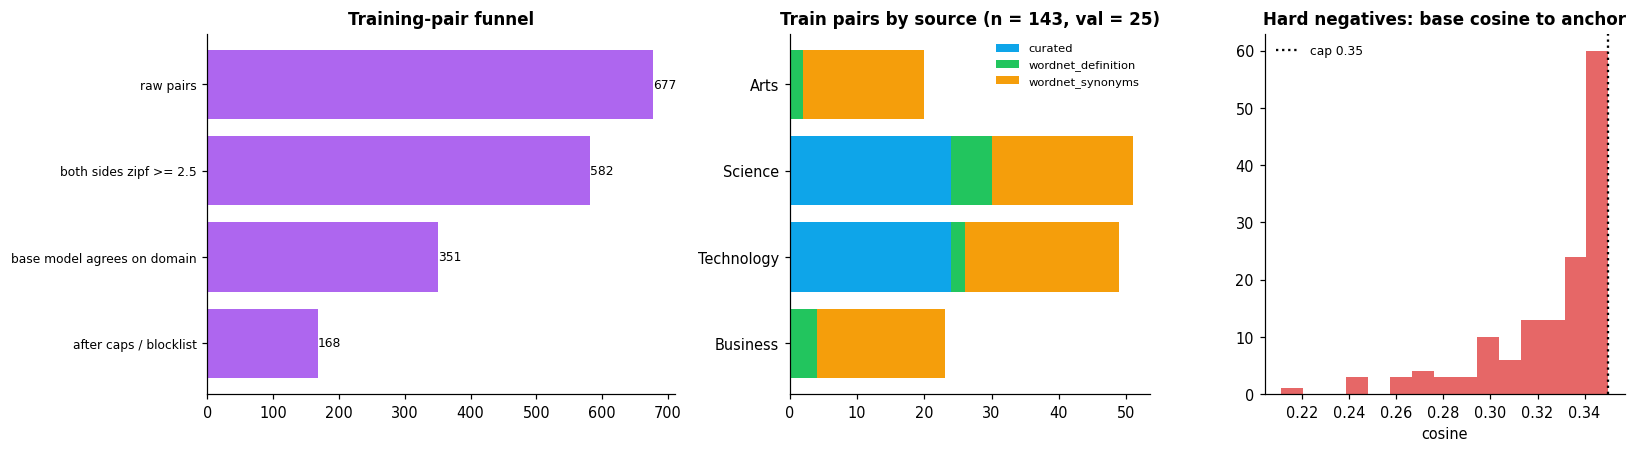

Figure 25. Fine-tuning data: filtering funnel, pair sources and hard-negative difficulty
Interpretation: Filters keep 168 of 677 raw pairs (24.8%): rare words, pairs whose two sides the base model puts in different domains, and over-represented synsets are removed. Hard negatives have mean base cosine 0.33 (max 0.35), close enough to be informative but below the cap so they are not hidden synonyms.
Table 22. Example training triplets (anchor, positive, hard negative)


,anchor,positive,negative,base_cos
0,programming,scheduling,commerce,0.321
1,flick,moving picture,lap,0.305
2,strength,physical energy or intensity,lit,0.296
3,algorithmic program,algorithmic rule,blueprint,0.303
4,experimentation,the testing of an idea,memory,0.340
5,design,innovation,computer programming,0.349
6,circuit,electrical circuit,physics,0.350
7,acid,low ph solution,memory,0.347
8,acceleration,change in velocity,circuit,0.344
9,film,photographic film,revenue,0.349


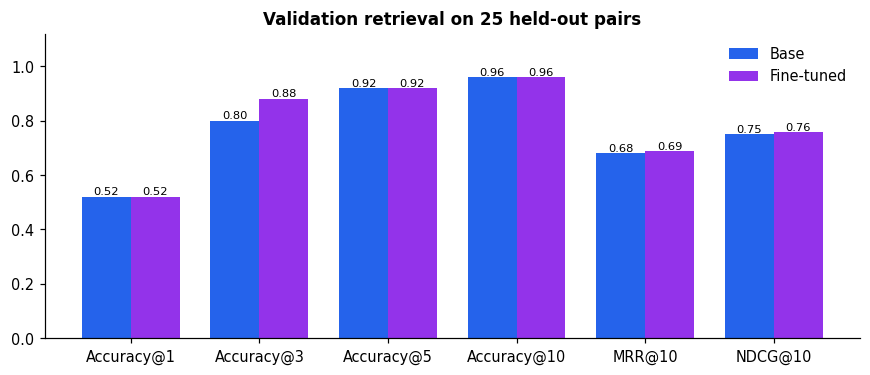

Figure 26. Validation retrieval: Base vs Fine-tuned (find the paired phrase among all candidates)
Interpretation: Fine-tuning changes MRR@10 by +0.008 and Accuracy@1 by +0.000. With only 25 validation pairs one query is 4.0%, so small differences are not reliable on their own.
Table 23. Validation retrieval metrics


,index,Base,Fine-tuned
0,Accuracy@1,0.520,0.520
1,Accuracy@3,0.800,0.880
2,Accuracy@5,0.920,0.920
3,Accuracy@10,0.960,0.960
4,MRR@10,0.681,0.688
5,NDCG@10,0.749,0.756


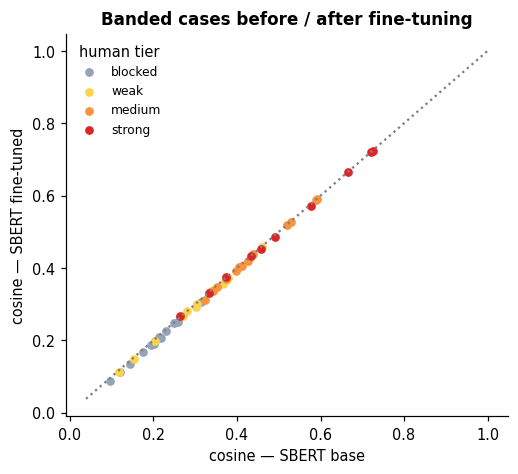

Figure 27. Cosine of each banded case before and after fine-tuning
Interpretation: Mean change by tier: blocked -0.007, weak -0.005, medium -0.004, strong -0.002. Points above the diagonal became more similar. The changes are small: one epoch on 143 pairs with a low learning rate nudges the space rather than rebuilding it.
Table 24. Fine-tuning criterion: AUC must not drop and anisotropy must not rise


,index,AUC related vs noise,Anisotropy (noise-pair mean cos),Mean cos strong/medium,Out-of-domain mean cos (blocked pairs),Mean r blocked,Gate AUC in vs out (debiased score)
0,SBERT base,0.990,0.291,0.461,0.206,0.040,0.952
1,SBERT fine-tuned,0.992,0.281,0.459,0.199,0.043,0.953


Interpretation: Verdict: PASS. AUC 0.990 → 0.992, anisotropy 0.291 → 0.281. Lower anisotropy means unrelated words are pushed further apart, which widens the gap between the noise floor and real hits.


In [30]:
# 10. Fine-tuning results: training data, validation retrieval, and how the embedding space moved
# What this cell does:
#   - Training-data funnel (raw WordNet + curated pairs → filters → final pairs) and pair sources per domain.
#   - Hard-negative difficulty (base-model cosine of anchor vs negative).
#   - Validation retrieval (Accuracy@k, MRR@10, NDCG@10): Base vs Fine-tuned on the held-out pairs.
#   - Base vs Fine-tuned cosine for the banded cases, and the fine-tuning criterion (AUC up, anisotropy down).
_t_ftv = time.perf_counter()
with section("10. Fine-tuning results") as _s:
    FINE_TUNE_VERDICT = None
    if FT_REPORT is None or "SBERT fine-tuned" not in CALIBRATED:
        _s.skip("no fine-tuned checkpoint / report")
    else:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})
        f = pd.Series(FT_REPORT["funnel"])
        bars = ax1.barh(f.index[::-1], f.values[::-1], color="#9333ea", alpha=0.75)
        ax1.bar_label(bars, fontsize=8)
        ax1.set_title("Training-pair funnel")
        ax1.tick_params(axis="y", labelsize=8)
        src = pd.DataFrame(FT_REPORT["sources"]).fillna(0)
        src = src.reindex([d for d in DOMAINS if d in src.index])
        left = np.zeros(len(src))
        for col, color in zip(src.columns, ["#0ea5e9", "#22c55e", "#f59e0b", "#64748b"]):
            ax2.barh(src.index, src[col], left=left, label=col, color=color)
            left += src[col].to_numpy()
        ax2.set_title(f"Train pairs by source (n = {FT_REPORT['train_size']}, val = {FT_REPORT['val_size']})")
        ax2.legend(frameon=False, fontsize=7.5)
        neg = np.array(FT_REPORT["negatives_base_cos"])
        ax3.hist(neg, bins=15, color="#dc2626", alpha=0.7)
        ax3.axvline(FT_CONFIG.hard_negative_max_cos, color="black", ls=":", label=f"cap {FT_CONFIG.hard_negative_max_cos}")
        ax3.set_title("Hard negatives: base cosine to anchor")
        ax3.set_xlabel("cosine")
        ax3.legend(frameon=False, fontsize=8)
        fig.tight_layout()
        _f = list(FT_REPORT["funnel"].values())
        save_figure(fig, "ft_data", "Fine-tuning data: filtering funnel, pair sources and hard-negative difficulty",
                    "Result 10 Fine-tuning",
                    f"Filters keep {_f[-1]} of {_f[0]} raw pairs ({pct(_f[-1] / max(_f[0], 1))}): rare words, pairs whose two "
                    "sides the base model puts in different domains, and over-represented synsets are removed. Hard "
                    f"negatives have mean base cosine {neg.mean():.2f} (max {neg.max():.2f}), close enough to be "
                    "informative but below the cap so they are not hidden synonyms.")
        neg_ex = pd.DataFrame(FT_REPORT["negative_examples"])
        save_table(neg_ex, "ft_triplets", "Example training triplets (anchor, positive, hard negative)",
                   "Method 10 Fine-tuning", show_rows=12)

        ir = pd.DataFrame(FT_REPORT["retrieval"])
        fig, ax = plt.subplots(figsize=(8, 3.5))
        x = np.arange(len(ir.index))
        for i, (col, color) in enumerate(zip(ir.columns, ["#2563eb", "#9333ea"])):
            bars = ax.bar(x + (i - 0.5) * 0.38, ir[col], 0.38, label=col, color=color)
            ax.bar_label(bars, fmt="%.2f", fontsize=7.5)
        ax.set_xticks(x, ir.index)
        ax.set_ylim(0, 1.12)
        ax.set_title(f"Validation retrieval on {FT_REPORT['val_size']} held-out pairs")
        ax.legend(frameon=False)
        fig.tight_layout()
        _d = ir["Fine-tuned"] - ir["Base"] if "Fine-tuned" in ir else None
        save_figure(fig, "ft_retrieval", "Validation retrieval: Base vs Fine-tuned (find the paired phrase among all candidates)",
                    "Result 10 Fine-tuning",
                    (f"Fine-tuning changes MRR@10 by {_d['MRR@10']:+.3f} and Accuracy@1 by {_d['Accuracy@1']:+.3f}. "
                     f"With only {FT_REPORT['val_size']} validation pairs one query is {pct(1 / FT_REPORT['val_size'])}, "
                     "so small differences are not reliable on their own." if _d is not None else ""))
        save_table(ir, "ft_retrieval", "Validation retrieval metrics", "Result 10 Fine-tuning", index=True)

        b, ft = PAIRS["SBERT base"], PAIRS["SBERT fine-tuned"]
        fig, ax = plt.subplots(figsize=(4.8, 4.4))
        for t, color in zip(TIER_ORDER, ["#94a3b8", "#fcd34d", "#fb923c", "#dc2626"]):
            m = b["tier"] == t
            ax.scatter(b.loc[m, "cos"], ft.loc[m, "cos"], color=color, label=t, s=22)
        lim = [min(b["cos"].min(), ft["cos"].min()) - 0.05, 1.0]
        ax.plot(lim, lim, ls=":", color="grey")
        ax.set_xlabel("cosine — SBERT base")
        ax.set_ylabel("cosine — SBERT fine-tuned")
        ax.legend(frameon=False, fontsize=8, title="human tier")
        ax.set_title("Banded cases before / after fine-tuning")
        fig.tight_layout()
        _shift = (ft["cos"] - b["cos"]).groupby(b["tier"]).mean().reindex(TIER_ORDER)
        save_figure(fig, "ft_cosine_shift", "Cosine of each banded case before and after fine-tuning",
                    "Result 10 Fine-tuning",
                    "Mean change by tier: " + ", ".join(f"{t} {v:+.3f}" for t, v in _shift.items())
                    + ". Points above the diagonal became more similar. The changes are small: one epoch on "
                      f"{FT_REPORT['train_size']} pairs with a low learning rate nudges the space rather than rebuilding it.")

        ib, ift = INTRINSIC["SBERT base"], INTRINSIC["SBERT fine-tuned"]
        _crit = pd.DataFrame({"SBERT base": ib, "SBERT fine-tuned": ift}).T
        passed = (ift["AUC related vs noise"] >= ib["AUC related vs noise"]
                  and ift["Anisotropy (noise-pair mean cos)"] <= ib["Anisotropy (noise-pair mean cos)"])
        FINE_TUNE_VERDICT = "PASS" if passed else "NEGATIVE RESULT"
        save_table(_crit, "ft_criterion", "Fine-tuning criterion: AUC must not drop and anisotropy must not rise",
                   "Result 10 Fine-tuning",
                   f"Verdict: {FINE_TUNE_VERDICT}. AUC {ib['AUC related vs noise']:.3f} → {ift['AUC related vs noise']:.3f}, "
                   f"anisotropy {ib['Anisotropy (noise-pair mean cos)']:.3f} → {ift['Anisotropy (noise-pair mean cos)']:.3f}. "
                   "Lower anisotropy means unrelated words are pushed further apart, which widens the gap between the "
                   "noise floor and real hits.", index=True)
log_section("10. Fine-tuning results", _t_ftv)

## 11. Holdout evaluation and error analysis
The holdout targets were never used for tuning, keywords, LDA or the corpus.

Single annotator (annotator_1): these labels are used as final.
Holdout labels: single_annotator | 28 cases | targets ['brand', 'cartoon', 'comet', 'email']
Table 25. Holdout results (28 unseen cases, 4 unseen targets)


,index,cases,gate accuracy,gate macro F1,in-domain -> primary,ambiguous pass,out-of-domain blocked,gate leak (0 dmg),damaging leak,damage in band
0,SBERT base,28.0,0.679,0.470,0.706,0.333,0.875,0.0,1.0,0.607
1,SBERT fine-tuned,28.0,0.679,0.470,0.706,0.333,0.875,0.0,1.0,0.607
2,GloVe + top-k gate,28.0,0.786,0.756,0.706,1.000,1.000,0.0,0.0,0.643


Interpretation: The holdout was not used for any choice above. SBERT base: accuracy 0.679, macro F1 0.470, in-band 0.607, damaging leaks 1 | SBERT fine-tuned: accuracy 0.679, macro F1 0.470, in-band 0.607, damaging leaks 1 | GloVe + top-k gate: accuracy 0.786, macro F1 0.756, in-band 0.643, damaging leaks 0. Macro F1 is lower than accuracy because the holdout has very few ambiguous cases, so one miss there costs a third of the score.


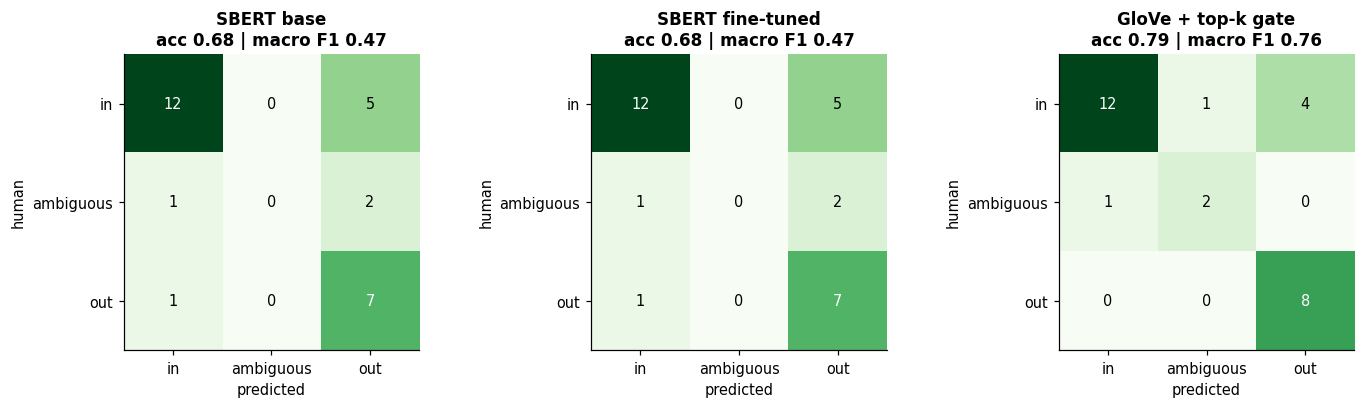

Figure 28. Holdout confusion matrices
Interpretation: Off-diagonal cells are the errors analysed below.


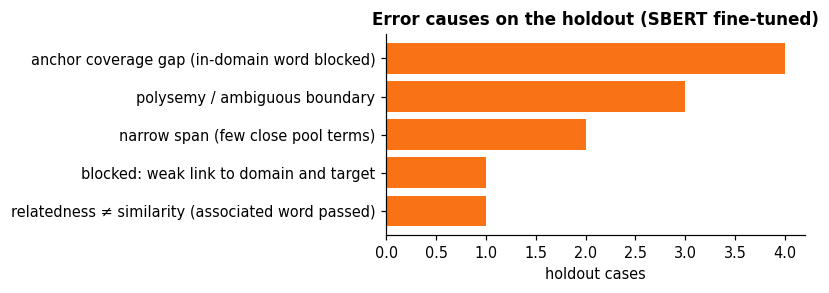

Figure 29. Causes of holdout errors (SBERT fine-tuned)
Interpretation: 11 of 28 cases are wrong in the gate or the damage band. The most common cause is 'anchor coverage gap (in-domain word blocked)' (4 cases). Coverage gaps mean the anchors describe the domain without the vocabulary of the new target (e.g. email words); 'relatedness ≠ similarity' means a word is associated with the target but belongs to another field (e.g. horoscope for comet), which a similarity model cannot tell apart.
Table 26. Holdout errors with cause, nearest LDA topic and anchor coverage (SBERT fine-tuned)


,Target,Guess,Required Domain,Human Label,Predicted Label,Relevance r,Hit %,Expected tier,Predicted Tier,Cause,LDA topic (k=4),topic main domain,words in domain anchors/pool
4,brand,fashion label,Business,ambiguous,out_of_domain,1.00,0.0,weak,BLOCKED — OUT OF DOMAIN,polysemy / ambiguous boundary,—,no LDA word,False
7,email,inbox,Technology,in_domain,out_of_domain,1.00,0.0,strong,BLOCKED — OUT OF DOMAIN,anchor coverage gap (in-domain word blocked),—,no LDA word,False
8,email,spam filter,Technology,in_domain,out_of_domain,0.86,0.0,strong,BLOCKED — OUT OF DOMAIN,anchor coverage gap (in-domain word blocked),—,no LDA word,False
9,email,mail server,Technology,in_domain,out_of_domain,1.00,0.0,strong,BLOCKED — OUT OF DOMAIN,anchor coverage gap (in-domain word blocked),—,no LDA word,False
11,email,newsletter,Technology,in_domain,out_of_domain,1.00,0.0,medium,BLOCKED — OUT OF DOMAIN,anchor coverage gap (in-domain word blocked),—,no LDA word,False
17,comet,light year,Science,in_domain,out_of_domain,0.00,0.0,medium,BLOCKED — OUT OF DOMAIN,blocked: weak link to domain and target,T0,Science,False
18,comet,space shuttle,Science,ambiguous,in_domain,0.56,24.9,weak,SOLID HIT,polysemy / ambiguous boundary,—,no LDA word,False
19,comet,horoscope,Science,out_of_domain,in_domain,0.00,4.0,blocked,WEAK GRAZE,relatedness ≠ similarity (associated word passed),—,no LDA word,False
22,cartoon,caricature,Arts,in_domain,in_domain,0.65,29.1,strong,STRONG HIT,narrow span (few close pool terms),—,no LDA word,False
24,cartoon,puppet show,Arts,in_domain,in_domain,0.90,40.2,medium,CRITICAL STRIKE,narrow span (few close pool terms),T3,Arts,False


Interpretation: 11 of the 11 error cases use words that never appear in the required domain's anchors or term pool, and 9 fall into an LDA topic whose main domain is different — both point to vocabulary coverage, not to the model, as the main source of error.
Table 27. Holdout gate accuracy per target


/tmp/ipykernel_732/3002615147.py:135: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  _per_target = pd.DataFrame({v: r.groupby("Target").apply(lambda g: (g["Predicted Label"] == g["Human Label"]).mean())
/tmp/ipykernel_732/3002615147.py:135: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  _per_target = pd.DataFrame({v: r.groupby("Target").apply(lambda g: (g["Predicted Label"] == g["Human Label"]).mean())
/tmp/i

,Target,SBERT base,SBERT fine-tuned,GloVe + top-k gate
0,brand,0.857,0.857,0.714
1,cartoon,0.857,0.857,1.000
2,comet,0.571,0.571,0.714
3,email,0.429,0.429,0.714


Interpretation: Accuracy differs strongly by target, which matches the error analysis: some new targets are well covered by the anchors and some are not.
Table 28. Project success criteria (True = met)


,criterion,SBERT base,SBERT fine-tuned
0,Holdout gate macro F1 >= 0.75,False,False
1,Holdout damaging leak = 0,False,False
2,Holdout in-domain -> primary >= 80%,False,False
3,Holdout damage in-band >= 70%,False,False
4,Pacing goals met (Section 6 battles),True,True
5,Pacing goals met (LOTO-CV),True,True
6,No tuned parameter on a grid edge,False,False


Interpretation: SBERT base: 2/7 met | SBERT fine-tuned: 2/7 met. Unmet holdout criteria are reported honestly; they come from the coverage gaps above.


In [31]:
# 11. Holdout evaluation (single use) and error analysis
# What this cell does:
#   - Final labels: inline HOLDOUT_ANNOTATIONS + annotator files (majority vote / single annotator / draft).
#   - Evaluates SBERT base, SBERT fine-tuned and the best GloVe variant on the 28 unseen holdout cases
#     (targets brand, email, comet, cartoon were never used for tuning, keywords or LDA).
#   - Confusion matrices, per-target results, success criteria.
#   - Error analysis: every wrong case gets a rule-based cause, its nearest LDA topic and whether its words
#     appear in the required domain's anchors / term pool.
_t_ho = time.perf_counter()

def holdout_eval(eng, cases: list) -> tuple:
    """Quiet version of evaluate_holdout(): (row table, summary dict)."""
    hdf = pd.DataFrame(cases, columns=["target", "guess", "required_domain", "human_label", "human_expected_tier"])
    res = evaluate_test_set(eng, hdf)
    res["Expected tier"] = hdf["human_expected_tier"].values
    hits = res["Hit %"].fillna(0) if "Hit %" in res else pd.Series(0.0, index=res.index)
    res["In band"] = [band_distance(p, TIER_BANDS_V2[t]) == 0 for p, t in zip(hits, res["Expected tier"])]
    kinds = res["Domain Match"].fillna("out_of_domain").to_numpy() if "Domain Match" in res else np.full(len(res), "out_of_domain")
    m = classification_metrics(res["Human Label"], res["Predicted Label"])
    feel = pass_block_metrics(res["Human Label"].to_numpy(), kinds)
    leaks = leak_breakdown(res["Human Label"], kinds, hits)
    spans = {}
    for t, d in set(zip(hdf["target"], hdf["required_domain"])):
        noise, ceiling = eng.raw_bounds(eng.target_calibration(t, d))
        spans[t] = ceiling - noise
    res["Raw span"] = res["Target"].map(spans)
    summary = {"cases": len(res), "gate accuracy": m["accuracy"], "gate macro F1": m["macro_f1"],
               "in-domain -> primary": feel["in_domain_primary"], "ambiguous pass": feel["ambiguous_pass"],
               "out-of-domain blocked": feel["out_block"], "gate leak (0 dmg)": leaks["gate leak (0 dmg)"],
               "damaging leak": leaks["damaging leak"], "damage in band": float(res["In band"].mean())}
    return res, summary

def error_cause(row, span_floor: float) -> str:
    human, pred = row["Human Label"], row["Predicted Label"]
    r = row.get("Relevance r", np.nan)
    if human == "in_domain" and pred == "out_of_domain":
        return "anchor coverage gap (in-domain word blocked)" if (r == r and r >= 0.3) else "blocked: weak link to domain and target"
    if human == "out_of_domain" and pred != "out_of_domain":
        return "relatedness ≠ similarity (associated word passed)"
    if human == "ambiguous" or pred == "ambiguous":
        if human != pred:
            return "polysemy / ambiguous boundary"
    if human != pred:
        return "gate threshold (in-domain not primary)"
    if not row["In band"]:
        if row["Raw span"] <= span_floor + 1e-9:
            return "narrow span (few close pool terms)"
        return "damage too high" if row.get("Hit %", 0) > TIER_BANDS_V2[row["Expected tier"]][1] else "damage too low"
    return "correct"

def nearest_topic(text: str):
    """(topic id, topic's main domain) of a short text under the k = 4 LDA model."""
    r4 = LDA_RESULTS[4]
    bow = lda_dict.doc2bow(lemma_of(text))
    if not bow:
        return None, "no LDA word"
    dist = dict(r4["model"].get_document_topics(bow, minimum_probability=0))
    t = max(dist, key=dist.get)
    return t, r4["topics"].loc[t, "main domain"]

with section("11. Holdout") as _s:
    HOLDOUT_RESULTS = {}
    if not RUN_HOLDOUT:
        _s.skip("RUN_HOLDOUT = False")
        HOLDOUT_LABEL_STATUS = "not run"
    else:
        HOLDOUT_CASES, HOLDOUT_LABEL_STATUS, HOLDOUT_AGREEMENT = consolidate_labels(collect_annotations())
        print(f"Holdout labels: {HOLDOUT_LABEL_STATUS} | {len(HOLDOUT_CASES)} cases | targets "
              f"{sorted({c[0] for c in HOLDOUT_CASES})}")
        _glove = [v for v in ("GloVe + top-k gate", "GloVe + centroid gate") if v in CALIBRATED]
        BEST_GLOVE = max(_glove, key=lambda v: CALIBRATED[v]["gate"]["cv"]["macro_f1"]) if _glove else None
        HOLDOUT_MODELS = SBERT_NAMES + ([BEST_GLOVE] if BEST_GLOVE else [])
        for v in HOLDOUT_MODELS:
            HOLDOUT_RESULTS[v] = holdout_eval(CALIBRATED[v]["engine"], HOLDOUT_CASES)
        holdout_df = pd.DataFrame({v: s for v, (_, s) in HOLDOUT_RESULTS.items()}).T
        save_table(holdout_df, "holdout_summary", f"Holdout results ({len(HOLDOUT_CASES)} unseen cases, {len({c[0] for c in HOLDOUT_CASES})} unseen targets)",
                   "Result 11 Holdout",
                   "The holdout was not used for any choice above. "
                   + " | ".join(f"{v}: accuracy {s['gate accuracy']:.3f}, macro F1 {s['gate macro F1']:.3f}, "
                                f"in-band {s['damage in band']:.3f}, damaging leaks {s['damaging leak']}"
                                for v, (_, s) in HOLDOUT_RESULTS.items())
                   + f". Macro F1 is lower than accuracy because the holdout has very few ambiguous cases, so one "
                     "miss there costs a third of the score.", index=True)

        fig, axes = plt.subplots(1, len(HOLDOUT_RESULTS), figsize=(4.3 * len(HOLDOUT_RESULTS), 3.8), squeeze=False)
        for ax, (v, (res, s)) in zip(axes[0], HOLDOUT_RESULTS.items()):
            cm = pd.crosstab(res["Human Label"], res["Predicted Label"]).reindex(index=LABELS, columns=LABELS, fill_value=0)
            ax.imshow(cm.values, cmap="Greens")
            ax.set_xticks(range(3), ["in", "ambiguous", "out"])
            ax.set_yticks(range(3), ["in", "ambiguous", "out"])
            for a in range(3):
                for b in range(3):
                    ax.text(b, a, cm.iat[a, b], ha="center", va="center",
                            color="white" if cm.iat[a, b] > cm.values.max() / 2 else "black")
            ax.set_title(f"{v}\nacc {s['gate accuracy']:.2f} | macro F1 {s['gate macro F1']:.2f}")
            ax.set_xlabel("predicted")
            ax.set_ylabel("human")
        fig.tight_layout()
        save_figure(fig, "holdout_confusion", "Holdout confusion matrices", "Result 11 Holdout",
                    "Off-diagonal cells are the errors analysed below.")

        _main = "SBERT fine-tuned" if "SBERT fine-tuned" in HOLDOUT_RESULTS else SBERT_NAMES[0]
        res = HOLDOUT_RESULTS[_main][0].copy()
        eng = CALIBRATED[_main]["engine"]
        res["Cause"] = res.apply(lambda row: error_cause(row, eng.span_floor), axis=1)
        _topics = [nearest_topic(g) for g in res["Guess"]]
        res["LDA topic (k=4)"] = [f"T{t}" if t is not None else "—" for t, _ in _topics]
        res["topic main domain"] = [d for _, d in _topics]
        res["words in domain anchors/pool"] = [all(w in REF_LEMMAS[d] for w in lemma_of(g)) if lemma_of(g) else False
                                               for g, d in zip(res["Guess"], res["Required Domain"])]
        HOLDOUT_ERRORS = res[res["Cause"] != "correct"]
        _causes = HOLDOUT_ERRORS["Cause"].value_counts()
        fig, ax = plt.subplots(figsize=(7.5, 0.5 + 0.45 * max(len(_causes), 1)))
        if len(_causes):
            ax.barh(_causes.index[::-1], _causes.values[::-1], color="#f97316")
        ax.set_xlabel("holdout cases")
        ax.set_title(f"Error causes on the holdout ({_main})")
        fig.tight_layout()
        save_figure(fig, "holdout_error_causes", f"Causes of holdout errors ({_main})", "Result 11 Holdout",
                    f"{len(HOLDOUT_ERRORS)} of {len(res)} cases are wrong in the gate or the damage band. "
                    + (f"The most common cause is '{_causes.index[0]}' ({_causes.iloc[0]} cases). " if len(_causes) else "")
                    + "Coverage gaps mean the anchors describe the domain without the vocabulary of the new target "
                      "(e.g. email words); 'relatedness ≠ similarity' means a word is associated with the target but "
                      "belongs to another field (e.g. horoscope for comet), which a similarity model cannot tell apart.")
        save_table(HOLDOUT_ERRORS[["Target", "Guess", "Required Domain", "Human Label", "Predicted Label", "Relevance r",
                                   "Hit %", "Expected tier", "Predicted Tier", "Cause", "LDA topic (k=4)",
                                   "topic main domain", "words in domain anchors/pool"]],
                   "holdout_errors", f"Holdout errors with cause, nearest LDA topic and anchor coverage ({_main})",
                   "Result 11 Holdout",
                   f"{int((~HOLDOUT_ERRORS['words in domain anchors/pool']).sum())} of the {len(HOLDOUT_ERRORS)} error cases "
                   "use words that never appear in the required domain's anchors or term pool, and "
                   f"{int((HOLDOUT_ERRORS['topic main domain'] != HOLDOUT_ERRORS['Required Domain']).sum())} fall into an LDA "
                   "topic whose main domain is different — both point to vocabulary coverage, not to the model, as the "
                   "main source of error.", show_rows=30)
        _per_target = pd.DataFrame({v: r.groupby("Target").apply(lambda g: (g["Predicted Label"] == g["Human Label"]).mean())
                                    for v, (r, _) in HOLDOUT_RESULTS.items()})
        save_table(_per_target, "holdout_per_target", "Holdout gate accuracy per target", "Result 11 Holdout",
                   "Accuracy differs strongly by target, which matches the error analysis: some new targets are well "
                   "covered by the anchors and some are not.", index=True)
        SUCCESS = {}
        for v in SBERT_NAMES:
            edges = {**{f"gate.{k}": x for k, x in CALIBRATED[v]["gate"]["edges"].items()},
                     **{f"damage.{k}": x for k, x in CALIBRATED[v]["damage"]["edges"].items()}}
            SUCCESS[v] = success_criteria(HOLDOUT_RESULTS[v][1], PACING[v][0], CALIBRATED[v]["damage"], edges)
        _succ = pd.concat({v: s.set_index("criterion")["pass"] for v, s in SUCCESS.items()}, axis=1)
        save_table(_succ, "success_criteria", "Project success criteria (True = met)", "Result 11 Holdout",
                   " | ".join(f"{v}: {int(s['pass'].sum())}/{len(s)} met" for v, s in SUCCESS.items())
                   + ". Unmet holdout criteria are reported honestly; they come from the coverage gaps above.",
                   index=True)
log_section("11. Holdout", _t_ho)

## 12–13. Final model selection and findings
The selection rule uses cross-validated evidence only; findings are generated from the computed numbers.

In [32]:
# 12. Findings (generated from the numbers above) + 13. Final model selection
# What this cell does:
#   - Writes the key findings as report-ready sentences, each pointing to its figure / table.
#   - Chooses the final model with a fixed rule on cross-validated evidence (the holdout only confirms):
#       fine-tuned is chosen if the fine-tuning criterion PASSes and its CV score is not lower than Base's
#       (CV score = mean of CV gate macro F1, CV in-domain primary and CV damage in-band).
#   - MODEL_CHOICE = "base" / "fine_tuned" overrides the rule for the game and the export.
#   - Sets the globals used by the Appendix (engine, model, ACTIVE_MODEL, GATE_CAL, DAMAGE_CAL, ...).
_t_fin = time.perf_counter()

def cv_score(v: str) -> float:
    g, d = CALIBRATED[v]["gate"]["cv"], CALIBRATED[v]["damage"]
    return float(np.mean([g["macro_f1"], g["in_domain_primary"], d["cv_in_band"]]))

with section("13. Final model selection"):
    TARGET_BANKS = {}
    for v in SBERT_NAMES:
        with contextlib.redirect_stdout(io.StringIO()):
            TARGET_BANKS[v] = build_target_bank(CALIBRATED[v]["engine"])
    sel_rows = []
    for v in SBERT_NAMES:
        g, d = CALIBRATED[v]["gate"], CALIBRATED[v]["damage"]
        row = {"Model": v, "CV score (selection)": cv_score(v), "Gate macro F1 (CV)": g["cv"]["macro_f1"],
               "In-domain primary (CV)": g["cv"]["in_domain_primary"], "Damage in-band (CV)": d["cv_in_band"],
               "AUC related vs noise": INTRINSIC[v]["AUC related vs noise"],
               "Anisotropy": INTRINSIC[v]["Anisotropy (noise-pair mean cos)"],
               "Playable targets (bank)": int(TARGET_BANKS[v]["eligible"].sum())}
        if v in HOLDOUT_RESULTS:
            s = HOLDOUT_RESULTS[v][1]
            row.update({"Holdout accuracy": s["gate accuracy"], "Holdout macro F1": s["gate macro F1"],
                        "Holdout in-band": s["damage in band"], "Holdout damaging leaks": s["damaging leak"]})
        sel_rows.append(row)
    selection_df = pd.DataFrame(sel_rows).set_index("Model")
    if "SBERT fine-tuned" in selection_df.index:
        _ft_ok = FINE_TUNE_VERDICT == "PASS" and cv_score("SBERT fine-tuned") >= cv_score("SBERT base") - 1e-9
        EVIDENCE_MODEL = "fine_tuned" if _ft_ok else "base"
        SELECTION_REASON = (
            f"Fine-tuning criterion {FINE_TUNE_VERDICT}; CV score {cv_score('SBERT fine-tuned'):.3f} (fine-tuned) vs "
            f"{cv_score('SBERT base'):.3f} (base) → {'fine-tuned' if _ft_ok else 'base'} is selected.")
    else:
        EVIDENCE_MODEL, SELECTION_REASON = "base", "No fine-tuned checkpoint was available → base is selected."
    _best_any = max(CALIBRATED, key=cv_score)
    if _best_any not in SBERT_NAMES:
        SELECTION_REASON += (f" Note: '{_best_any}' has a higher CV score ({cv_score(_best_any):.3f}) than every SBERT model; "
                             "this notebook delivers the SBERT backend, so this result is reported for the team's "
                             "GloVe-vs-SBERT decision rather than hidden.")
    FINAL_MODEL = EVIDENCE_MODEL if MODEL_CHOICE == "auto" else MODEL_CHOICE
    if FINAL_MODEL == "fine_tuned" and "SBERT fine-tuned" not in CALIBRATED:
        print("WARNING: MODEL_CHOICE = 'fine_tuned' but no checkpoint exists — using base.")
        FINAL_MODEL = "base"
    FINAL_VARIANT = SBERT_VARIANTS[FINAL_MODEL]
    save_table(selection_df, "final_selection", "Evidence for the final model choice", "Result 13 Final model",
               SELECTION_REASON + (f" MODEL_CHOICE = '{MODEL_CHOICE}' overrides the rule." if MODEL_CHOICE != "auto" else "")
               + " The holdout columns are shown as confirmation only; they were not used for the choice.", index=True)

    # Globals expected by the Appendix cells (play, export)
    model, ACTIVE_MODEL, MODEL_SOURCE = load_model(FINAL_MODEL)
    engine = CALIBRATED[FINAL_VARIANT]["engine"]
    GATE_CAL, DAMAGE_CAL = CALIBRATED[FINAL_VARIANT]["gate"], CALIBRATED[FINAL_VARIANT]["damage"]
    CALIBRATION_SOURCE = CALIBRATED[FINAL_VARIANT]["calibration"]
    pacing_df = PACING[FINAL_VARIANT][0]
    PARAMS_ON_EDGE = {**{f"gate.{k}": x for k, x in GATE_CAL["edges"].items()},
                      **{f"damage.{k}": x for k, x in DAMAGE_CAL["edges"].items()}}
    holdout_result, holdout_summary = HOLDOUT_RESULTS.get(FINAL_VARIANT, (None, None))
    TARGET_BANK = TARGET_BANKS[FINAL_VARIANT]
    print(f"FINAL MODEL: {FINAL_VARIANT} ({MODEL_SOURCE})")

with section("12. Findings"):
    F = []
    def add(text: str, *refs):
        F.append(text + (f" ({', '.join(refs)})" if refs else ""))
    add(f"The game input is extremely short: {pct(_phrase_len['1 word'].sum() / _phrase_len[['1 word', '2 words', '3 words']].values.sum())} "
        "of all phrases are one word, so bag-of-words methods have almost no context to work with.",
        ref("Table", "phrase_length"))
    add(f"The domain corpus ({len(corpus_df)} documents) covers only "
        f"{pct(coverage_df['Domain corpus'].min())}–{pct(coverage_df['Domain corpus'].max())} of the words players use, while "
        "pretrained vocabularies cover most of them; this rules out training a representation only on project data.",
        ref("Figure", "vocab_coverage"), ref("Table", "oov_rates"))
    add(f"Class-based TF-IDF finds domain-specific keywords, but only {pct(keyword_coverage_df['top-20 keywords in anchors'].mean())} "
        "of them appear in the anchor sentences: the anchors describe each domain broadly rather than listing its vocabulary.",
        ref("Figure", "keywords_freq_vs_ctfidf"), ref("Table", "keyword_anchor_coverage"))
    _nmi4 = LDA_RESULTS[4]["nmi"]
    add(f"LDA topics {'only partly' if _nmi4 < 0.5 else 'largely'} follow the four domains (k = 4: NMI {_nmi4:.2f}, ARI "
        f"{LDA_RESULTS[4]['ari']:.2f}; best coherence at k = {LDA_K}). "
        + ("Word co-occurrence alone does not reproduce the game's domain boundaries, which supports an explicit, "
           "anchor-based gate." if _nmi4 < 0.5 else "The corpus vocabulary itself separates the domains well."),
        ref("Figure", "lda_k_selection"), ref("Figure", "lda_topic_domain_heatmap"))
    _cb = cluster_df.loc[cluster_df["NMI (k=4 vs domain)"].idxmax()]
    add(f"Without labels, K-means on {_cb['representation']} recovers the domains best (NMI {_cb['NMI (k=4 vs domain)']:.3f}).",
        ref("Table", "clustering_metrics"), ref("Figure", "pca_representations"))
    _sb = similarity_df.loc[similarity_df["Spearman ρ (raw cosine vs tier)"].idxmax()]
    add(f"{_sb['representation']} cosine follows the human damage tiers most closely (Spearman ρ "
        f"{_sb['Spearman ρ (raw cosine vs tier)']:.2f}); per-target normalisation is still needed because noise floors "
        "differ between targets.", ref("Figure", "cosine_by_tier"), ref("Figure", "raw_vs_normalised"))
    _bc = comparison_df.loc[comparison_df["Gate macro F1 (CV)"].idxmax()]
    add(f"Under identical calibration and cross-validation, {_bc['Model']} has the best CV gate macro F1 "
        f"({_bc['Gate macro F1 (CV)']:.3f}); " + (f"the largest single improvement comes from '{_eff.idxmax()}' "
                                                  f"({_eff.max():+.3f})." if len(_eff) else ""),
        ref("Table", "fair_comparison"), ref("Table", "one_factor_effects"))
    for v in SBERT_NAMES:
        g = CALIBRATED[v]["gate"]
        add(f"{v}: gate macro F1 {g['tuned']['macro_f1']:.3f} (tuned) vs {g['cv']['macro_f1']:.3f} (CV); in-domain → primary "
            f"{g['cv']['in_domain_primary']:.3f} (CV); damage in-band {CALIBRATED[v]['damage']['tuned_in_band']:.3f} / "
            f"{CALIBRATED[v]['damage']['cv_in_band']:.3f}. "
            + ("The small tuned-to-CV drop shows the plateau-selected thresholds generalise."
               if g["tuned"]["macro_f1"] - g["cv"]["macro_f1"] <= 0.05 else
               "The tuned-to-CV drop is noticeable, so part of the tuned score is optimism from choosing thresholds on the same rows."),
            ref("Figure", "gate_tuned_vs_cv"))
    if FINE_TUNE_VERDICT:
        ib, ift = INTRINSIC["SBERT base"], INTRINSIC["SBERT fine-tuned"]
        add(f"Fine-tuning ({FT_REPORT['train_size']} WordNet / curated pairs, MNRL with hard negatives) gives a {FINE_TUNE_VERDICT}: "
            f"AUC {ib['AUC related vs noise']:.3f} → {ift['AUC related vs noise']:.3f}, anisotropy "
            f"{ib['Anisotropy (noise-pair mean cos)']:.3f} → {ift['Anisotropy (noise-pair mean cos)']:.3f}. "
            + ("Changes are small because the training set and schedule are small (one epoch, low learning rate): the "
               "space is nudged, not rebuilt." if abs(ift["AUC related vs noise"] - ib["AUC related vs noise"]) < 0.01
               else "The change in AUC is larger than 0.01, so fine-tuning measurably moved the space."),
            ref("Figure", "ft_retrieval"), ref("Table", "ft_criterion"))
    if HOLDOUT_RESULTS:
        s = HOLDOUT_RESULTS[FINAL_VARIANT][1]
        add(f"On the unseen holdout the final model reaches gate accuracy {s['gate accuracy']:.3f}, macro F1 {s['gate macro F1']:.3f} "
            f"and damage in-band {s['damage in band']:.3f}, with {s['damaging leak']} damaging leak(s). The most common error "
            "causes are " + ", ".join(f"'{c}' ({n})" for c, n in HOLDOUT_ERRORS["Cause"].value_counts().head(3).items()) + ".",
            ref("Table", "holdout_summary"), ref("Figure", "holdout_error_causes"))
    add(f"Final model: {FINAL_VARIANT}. {SELECTION_REASON}", ref("Table", "final_selection"))
    FINDINGS = F
    _md = "## Key findings\n\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))
    (REPORT_DIR / "findings.md").write_text(_md + "\n")
    display(Markdown(_md))
log_section("12–13. Findings and selection", _t_fin)

Table 29. Evidence for the final model choice


,Model,CV score (selection),Gate macro F1 (CV),In-domain primary (CV),Damage in-band (CV),AUC related vs noise,Anisotropy,Playable targets (bank),Holdout accuracy,Holdout macro F1,Holdout in-band,Holdout damaging leaks
0,SBERT base,0.704,0.663,0.848,0.6,0.990,0.291,141,0.679,0.47,0.607,1
1,SBERT fine-tuned,0.712,0.670,0.866,0.6,0.992,0.281,144,0.679,0.47,0.607,1


Interpretation: Fine-tuning criterion PASS; CV score 0.712 (fine-tuned) vs 0.704 (base) → fine-tuned is selected. Note: 'GloVe + top-k gate' has a higher CV score (0.767) than every SBERT model; this notebook delivers the SBERT backend, so this result is reported for the team's GloVe-vs-SBERT decision rather than hidden. The holdout columns are shown as confirmation only; they were not used for the choice.
FINAL MODEL: SBERT fine-tuned (/content/drive/MyDrive/lexical_combat/models/fine_tuned_lexical_minilm_v3)


## Key findings

1. The game input is extremely short: 71.9% of all phrases are one word, so bag-of-words methods have almost no context to work with. (Table 5)
2. The domain corpus (194 documents) covers only 22.0%–71.1% of the words players use, while pretrained vocabularies cover most of them; this rules out training a representation only on project data. (Fig. 8, Table 16)
3. Class-based TF-IDF finds domain-specific keywords, but only 51.3% of them appear in the anchor sentences: the anchors describe each domain broadly rather than listing its vocabulary. (Fig. 11, Table 10)
4. LDA topics only partly follow the four domains (k = 4: NMI 0.05, ARI 0.03; best coherence at k = 4). Word co-occurrence alone does not reproduce the game's domain boundaries, which supports an explicit, anchor-based gate. (Fig. 12, Fig. 13)
5. Without labels, K-means on SBERT base recovers the domains best (NMI 0.720). (Table 17, Fig. 15)
6. SBERT fine-tuned cosine follows the human damage tiers most closely (Spearman ρ 0.78); per-target normalisation is still needed because noise floors differ between targets. (Fig. 17, Fig. 19)
7. Under identical calibration and cross-validation, GloVe + top-k gate has the best CV gate macro F1 (0.730); the largest single improvement comes from 'GloVe vs TF-IDF (top-k gate)' (+0.313). (Table 18, Table 19)
8. SBERT base: gate macro F1 0.705 (tuned) vs 0.663 (CV); in-domain → primary 0.848 (CV); damage in-band 0.640 / 0.600. The small tuned-to-CV drop shows the plateau-selected thresholds generalise. (Fig. 21)
9. SBERT fine-tuned: gate macro F1 0.707 (tuned) vs 0.670 (CV); in-domain → primary 0.866 (CV); damage in-band 0.640 / 0.600. The small tuned-to-CV drop shows the plateau-selected thresholds generalise. (Fig. 21)
10. Fine-tuning (143 WordNet / curated pairs, MNRL with hard negatives) gives a PASS: AUC 0.990 → 0.992, anisotropy 0.291 → 0.281. Changes are small because the training set and schedule are small (one epoch, low learning rate): the space is nudged, not rebuilt. (Fig. 26, Table 24)
11. On the unseen holdout the final model reaches gate accuracy 0.679, macro F1 0.470 and damage in-band 0.607, with 1 damaging leak(s). The most common error causes are 'anchor coverage gap (in-domain word blocked)' (4), 'polysemy / ambiguous boundary' (3), 'narrow span (few close pool terms)' (2). (Table 25, Fig. 29)
12. Final model: SBERT fine-tuned. Fine-tuning criterion PASS; CV score 0.712 (fine-tuned) vs 0.704 (base) → fine-tuned is selected. Note: 'GloVe + top-k gate' has a higher CV score (0.767) than every SBERT model; this notebook delivers the SBERT backend, so this result is reported for the team's GloVe-vs-SBERT decision rather than hidden. (Table 29)

## 14. Report assets, regression check and run summary

In [33]:
# 14. Report assets, regression check and run summary
# What this cell does:
#   - report_assets.md: every figure / table in order with caption, file, report section and interpretation.
#   - references.md: data sources, models and libraries to cite.
#   - Zips report_assets/ (figures PNG 300 dpi, tables CSV + Markdown, findings.md) for the report writer.
#   - Regression check: key numbers vs the reference Colab run (printed PASS / FAIL, never stops the run).
_t_as = time.perf_counter()
with section("14. Report assets"):
    lines = ["# Report assets", "",
             f"Generated {time.strftime('%Y-%m-%d %H:%M')} | final model: {FINAL_VARIANT} | seed {SEED}", ""]
    for kind in ("Figure", "Table"):
        lines += [f"## {kind}s", ""]
        for a in [a for a in ASSETS if a["kind"] == kind]:
            lines += [f"### {kind} {a['number']}. {a['caption']}", f"- File: `{a['file']}`",
                      f"- Report section: {a['section']}"]
            if a["interpretation"]:
                lines.append(f"- Interpretation: {a['interpretation']}")
            lines.append("")
    (REPORT_DIR / "report_assets.md").write_text("\n".join(lines))
    references = """# References (data, models, libraries)
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks. EMNLP-IJCNLP.
- Wang, W. et al. (2020). MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers. NeurIPS.
- sentence-transformers/all-MiniLM-L6-v2, Hugging Face model card.
- Henderson, M. et al. (2017). Efficient Natural Language Response Suggestion for Smart Reply (multiple negatives ranking loss).
- Pennington, J., Socher, R., & Manning, C. D. (2014). GloVe: Global Vectors for Word Representation. EMNLP.
- Blei, D. M., Ng, A. Y., & Jordan, M. I. (2003). Latent Dirichlet Allocation. JMLR 3.
- Röder, M., Both, A., & Hinneburg, A. (2015). Exploring the Space of Topic Coherence Measures. WSDM (c_v coherence).
- Grootendorst, M. (2022). BERTopic: Neural topic modeling with a class-based TF-IDF procedure. arXiv:2203.05794 (c-TF-IDF).
- Deerwester, S. et al. (1990). Indexing by Latent Semantic Analysis. JASIS (LSA).
- Ethayarajh, K. (2019). How Contextual are Contextualized Word Representations? EMNLP (anisotropy).
- Miller, G. A. (1995). WordNet: A Lexical Database for English. CACM.
- Wikipedia REST API page summaries (CC BY-SA), retrieved for the domain corpus.
- Řehůřek, R., & Sojka, P. (2010). Software Framework for Topic Modelling with Large Corpora (gensim).
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. JMLR 12.
- Bird, S., Klein, E., & Loper, E. (2009). Natural Language Processing with Python (NLTK).
"""
    (REPORT_DIR / "references.md").write_text(references)
    corpus_df[["doc_id", "term", "domain", "source", "title", "n_words", "retrieved_at", "text"]].to_csv(
        REPORT_DIR / "domain_corpus.csv", index=False)
    ZIP_PATH = PATHS.root / "report_assets.zip"
    with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(REPORT_DIR.rglob("*")):
            if p.is_file():
                z.write(p, p.relative_to(REPORT_DIR.parent))
    n_fig = sum(a["kind"] == "Figure" for a in ASSETS)
    n_tab = sum(a["kind"] == "Table" for a in ASSETS)
    print(f"{n_fig} figures + {n_tab} tables → {REPORT_DIR}\nZip: {ZIP_PATH} ({ZIP_PATH.stat().st_size / 1e6:.1f} MB)")
    try:
        from google.colab import files as _colab_files
        _colab_files.download(str(ZIP_PATH))
    except Exception:
        pass

# Regression check: numbers of the reference Colab run (all-MiniLM-L6-v2 base / fine_tuned_lexical_minilm_v3)
REFERENCE_NUMBERS = {
    ("SBERT base", "gate macro F1 tuned"): 0.705, ("SBERT base", "gate macro F1 CV"): 0.663,
    ("SBERT base", "in-domain primary CV"): 0.848, ("SBERT base", "AUC related vs noise"): 0.990,
    ("SBERT base", "anisotropy"): 0.291,
    ("SBERT fine-tuned", "gate macro F1 tuned"): 0.707, ("SBERT fine-tuned", "gate macro F1 CV"): 0.670,
    ("SBERT fine-tuned", "in-domain primary CV"): 0.866, ("SBERT fine-tuned", "AUC related vs noise"): 0.992,
    ("SBERT fine-tuned", "anisotropy"): 0.281,
}

def current_number(v: str, key: str):
    if v not in CALIBRATED:
        return None
    g, im = CALIBRATED[v]["gate"], INTRINSIC[v]
    return {"gate macro F1 tuned": g["tuned"]["macro_f1"], "gate macro F1 CV": g["cv"]["macro_f1"],
            "in-domain primary CV": g["cv"]["in_domain_primary"], "AUC related vs noise": im["AUC related vs noise"],
            "anisotropy": im["Anisotropy (noise-pair mean cos)"]}[key]

with section("14. Regression check"):
    _rows = []
    for (v, key), expected in REFERENCE_NUMBERS.items():
        got = current_number(v, key)
        _rows.append({"model": v, "metric": key, "reference": expected, "this run": got,
                      "match (±0.01)": None if got is None else abs(got - expected) <= 0.01})
    regression_df = pd.DataFrame(_rows)
    _checked = regression_df.dropna(subset=["this run"])
    REGRESSION_RESULT = ("PASS" if len(_checked) and _checked["match (±0.01)"].all()
                         else f"DIFFERENT ({int((~_checked['match (±0.01)'].astype(bool)).sum())} of {len(_checked)} differ)")
    display(regression_df.round(3))
    print(f"Regression vs reference run: {REGRESSION_RESULT}. A retrained checkpoint (TRAIN_FINE_TUNED = 'always') "
          "can legitimately differ slightly; Base numbers should match.")

print("\nRun summary")
display(pd.DataFrame(RUN_LOG)[["section", "status", "reason", "seconds"]])
print(f"Total: {time.perf_counter() - RUN_START:.0f} s | final model: {FINAL_VARIANT} | PERSISTENT: {PERSISTENT} | "
      f"holdout labels: {HOLDOUT_LABEL_STATUS} | regression: {REGRESSION_RESULT}")
log_section("14. Assets", _t_as)

29 figures + 29 tables → /content/drive/MyDrive/lexical_combat/report_assets
Zip: /content/drive/MyDrive/lexical_combat/report_assets.zip (9.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,model,metric,reference,this run,match (±0.01)
0,SBERT base,gate macro F1 tuned,0.705,0.705,True
1,SBERT base,gate macro F1 CV,0.663,0.663,True
2,SBERT base,in-domain primary CV,0.848,0.848,True
3,SBERT base,AUC related vs noise,0.990,0.990,True
4,SBERT base,anisotropy,0.291,0.291,True
5,SBERT fine-tuned,gate macro F1 tuned,0.707,0.707,True
6,SBERT fine-tuned,gate macro F1 CV,0.670,0.670,True
7,SBERT fine-tuned,in-domain primary CV,0.866,0.866,True
8,SBERT fine-tuned,AUC related vs noise,0.992,0.992,True
9,SBERT fine-tuned,anisotropy,0.281,0.281,True


Regression vs reference run: PASS. A retrained checkpoint (TRAIN_FINE_TUNED = 'always') can legitimately differ slightly; Base numbers should match.

Run summary


,section,status,reason,seconds
0,0. Setup,ran,,25.16
1,0.4 Report helpers,ran,,12.92
2,1. Data registry,ran,,0.20
3,2. Text utilities and checks,ran,,0.64
4,1.4 Domain corpus,ran,,10.56
5,2. Data understanding (EDA),ran,,37.80
6,3. Preprocessing,ran,,6.59
7,4. Keyword extraction,ran,,5.79
8,5. Topic modelling (LDA),ran,,42.78
9,3. Engine,ran,,0.05


Total: 359 s | final model: SBERT fine-tuned | PERSISTENT: True | holdout labels: single_annotator | regression: PASS


## Appendix A. Play
Uses the final model from Section 13. `PLAY_INTERACTIVE = False` runs one simulated battle; the Play Game cell below
gives the interactive widget version.

In [34]:
# Appendix A. Play: target bank, simulated battle (default) or interactive game
# What this cell does:
#   - Shows the target bank of the final model and runs one simulated battle (or the input() game).
with section("Appendix A. Play"):
    TARGET_BANK = build_target_bank(engine)
    print("Target bank (eligible / screened) per topic:")
    display(TARGET_BANK.groupby("domain")["eligible"].agg(["sum", "size"])
            .rename(columns={"sum": "eligible", "size": "screened"}))
    print("Rejected examples:")
    display(TARGET_BANK[~TARGET_BANK["eligible"]].groupby("reason").head(2)[["domain", "target", "reason"]])
    if not PLAY_INTERACTIVE:
        print("PLAY_INTERACTIVE = False — one simulated battle (set it to True to play).")
        simulated_battle(engine, TARGET_BANK, SEED)
    elif PLAY_MODE == "classic":
        run_game(engine, GAME_STAGES)
    else:
        print("\nRandom-topic game: 1–3 English words per guess | 'hint' | 'quit'")
        run_game(engine, random_stages(TARGET_BANK, RANDOM_ROUNDS, SEED))

Target bank (eligible / screened) per topic:


,eligible,screened
domain,,
Arts,34,53
Business,44,52
Science,36,50
Technology,30,51


Rejected examples:


,domain,target,reason
6,Business,profit,only 3 good answers
13,Business,chief executive officer,generic / too long
18,Business,board of directors,generic / too long
27,Business,budget,only 1 good answers
43,Business,customer,only 2 good answers
44,Business,client,target itself is out_of_domain
46,Business,logistics,only 3 good answers
50,Business,performance review,target itself is out_of_domain
55,Technology,database,only 2 good answers
62,Technology,data structure,only 1 good answers


PLAY_INTERACTIVE = False — one simulated battle (set it to True to play).
Simulated: Alchemist Golem | target 'hydrogen' (Science) | guesses ['banana', 'spreadsheet', 'element', 'oxidation', 'photosynthesis', 'organic chemistry', 'chemical compound', 'chemical bond']
  Guess: 'banana'
  Step 1 · Domain gate (Science): raw 0.043 − background 0.069 = -0.026 | lead vs best other -0.045 → OUT_OF_DOMAIN
          Domain share (display): Business: 41% | Technology: 25% | Science: 17% | Arts: 17%
  Step 2 · Target relevance: cos 0.242 | noise floor 0.227 | ceiling 0.543 → r = 0.05
  Step 3 · Damage: blocked by the domain gate → 0 HP | BLOCKED — OUT OF DOMAIN
  Latency: 12.1 ms | Enemy HP left: 200

  Guess: 'spreadsheet'
  Step 1 · Domain gate (Science): raw 0.172 − background 0.069 = +0.103 | lead vs best other -0.046 → OUT_OF_DOMAIN
          Domain share (display): Business: 44% | Technology: 37% | Science: 17% | Arts: 2%
  Step 2 · Target relevance: cos 0.081 | noise floor 0.227 | ceiling

,Guess,Cosine,Relevance r,Gate,Generic,Echo,Hit %,Tier,Damage,HP before,HP left
0,banana,0.242,0.05,out_of_domain,False,False,0.0,BLOCKED — OUT OF DOMAIN,0,200,200
1,spreadsheet,0.081,0.00,out_of_domain,False,False,0.0,BLOCKED — OUT OF DOMAIN,0,200,200
2,element,0.414,0.59,primary,False,False,26.3,STRONG HIT,53,200,147
3,oxidation,0.408,0.57,primary,False,False,25.5,SOLID HIT,51,147,96
4,photosynthesis,0.408,0.57,primary,False,False,25.4,SOLID HIT,51,96,45
5,organic chemistry,0.404,0.56,primary,False,False,24.9,SOLID HIT,45,45,0


In [35]:
# Play Game — random topic + random target; type your own guesses in the box below.
# What this cell does:
#   - GameSession: game state (stages, HP, guesses, hints, skips).
#   - HTML cards for each turn, stage summaries and the game summary.
#   - ipywidgets UI (Attack / Hint / Skip / Quit / New game) with a text-mode fallback.
# Uses widgets, so Run all never waits for input. Without ipywidgets: call play_in_text_mode(GAME).

TOPIC_COLORS = {"Business": "#3b82f6", "Technology": "#10b981", "Science": "#a855f7", "Arts": "#f43f5e"}
TIER_COLORS = {"CRITICAL STRIKE": "#ef4444", "STRONG HIT": "#f97316", "SOLID HIT": "#eab308",
               "WEAK GRAZE": "#22c55e", "NO EFFECT": "#71717a", "BLOCKED — OUT OF DOMAIN": "#52525b"}
STATUS_COLORS = {"Defeated": "#22c55e", "Skipped": "#eab308", "Quit": "#f43f5e", "In progress": "#3b82f6"}
GATE_SHORT = {"primary": "primary", "secondary": "secondary", "weak_secondary": "weak secondary",
              "out_of_domain": "blocked"}
GATE_TEXT = {"primary": "PRIMARY — in the topic", "secondary": "SECONDARY — related topic",
             "weak_secondary": "WEAK SECONDARY — loosely related", "out_of_domain": "BLOCKED — wrong topic"}
CARD = "background:#1e1e24;border:1px solid #3f3f46;border-radius:10px;color:#f4f4f5;font-family:sans-serif;"

def _badge(text: str, color: str) -> str:
    """Small coloured label."""
    return (f"<span style='background:{color};color:#fff;padding:2px 8px;border-radius:999px;"
            f"font-size:11px;font-weight:bold;white-space:nowrap'>{_html.escape(text)}</span>")

def _line(label: str, value: str, note: str = "") -> str:
    """One labelled detail line of a turn card."""
    note_html = f"<span style='color:#a1a1aa;font-size:12px'> {note}</span>" if note else ""
    return (f"<div style='display:flex;gap:10px;padding:3px 0;font-size:13px'>"
            f"<div style='width:150px;color:#a1a1aa;flex-shrink:0'>{label}</div>"
            f"<div style='color:#f4f4f5'>{value}{note_html}</div></div>")

def turn_card_html(engine: LexicalCombatEngine, result: dict, hp_before: int, hp_after: int,
                   domain: str, turn: int) -> str:
    """One guess, one detail per line."""
    if not result["valid"]:
        return (f"<div style='{CARD}padding:8px 14px;margin:6px 0;border-color:#a16207'>"
                f"⚠️ <b>Not counted:</b> {_html.escape(result['reason'])}</div>")
    tier = result["tier"]
    color = TIER_COLORS.get(tier, "#71717a")
    damage = result.get("actual_damage", result["damage"])
    share = " · ".join(f"{d} {result['domain_probs'][d]:.0%}" for d in engine.data.domains)
    rival = max((d for d in engine.data.domains if d != domain), key=lambda d: result["domain_scores"][d])
    multipliers = [f"base {result['base_percent']:.1f}%", f"topic ×{result['multiplier']:.2f}"]
    if result["is_generic"]:
        multipliers.append(f"too generic ×{result['generic_multiplier']:.2f}")
    if result["is_echo"]:
        multipliers.append(f"repeat idea ×{result['echo_multiplier']:.2f}")
    if result.get("graze_floor") and result["base_percent"] <= 0:
        multipliers.append(f"in-topic graze floor {engine.config.chip_percent}%")
    damage_line = (" · ".join(multipliers) + f" → <b>{result['hit_percent']:.1f}%</b> of boss HP"
                   if result["domain_allowed"] else "blocked by the topic gate")
    lines = [
        _line("1 · Topic gate", f"<b>{GATE_TEXT[result['domain_match_type']]}</b>",
              f"({domain} score {result['domain_scores'][domain]:+.3f}, lead {result['domain_lead']:+.3f} vs {rival})"),
        _line("&nbsp;&nbsp;&nbsp;Topic share", share),
        _line("2 · Relevance", f"<b>r = {result['relevance']:.2f}</b>",
              f"(cos {result['similarity']:.3f} · noise floor {result['noise_floor']:.3f} · ceiling {result['ceiling']:.3f})"),
        _line("3 · Damage", damage_line),
        _line("&nbsp;&nbsp;&nbsp;Boss HP", f"{hp_before} → <b>{max(hp_after, 0)}</b>",
              f"({result['latency_ms']:.0f} ms)"),
    ]
    head = (f"<div style='display:flex;justify-content:space-between;align-items:center;margin-bottom:6px'>"
            f"<div style='font-size:15px'><span style='color:#a1a1aa'>Turn {turn}</span> · "
            f"<b>'{_html.escape(result['word'])}'</b></div>"
            f"<div>{_badge(tier, color)} <b style='color:{color};font-size:16px;margin-left:6px'>"
            f"{'−' + str(damage) if damage else '0'} HP</b></div></div>")
    return f"<div style='{CARD}padding:10px 14px;margin:8px 0;border-left:5px solid {color}'>{head}{''.join(lines)}</div>"

def _table_html(frame: pd.DataFrame, colors: dict = None) -> str:
    """Dark HTML table; colors maps column -> {value: colour} for badge cells."""
    colors = colors or {}
    head = "".join(f"<th style='text-align:left;padding:6px 10px;color:#a1a1aa;font-size:12px;"
                   f"border-bottom:1px solid #3f3f46'>{_html.escape(str(c))}</th>" for c in frame.columns)
    rows = []
    for _, row in frame.iterrows():
        cells = []
        for c in frame.columns:
            value = row[c]
            text = _badge(str(value), colors[c].get(value, "#52525b")) if c in colors else _html.escape(str(value))
            cells.append(f"<td style='padding:5px 10px;font-size:13px;color:#e4e4e7;border-bottom:1px solid #27272a'>{text}</td>")
        rows.append("<tr>" + "".join(cells) + "</tr>")
    return f"<table style='border-collapse:collapse;width:100%'><tr>{head}</tr>{''.join(rows)}</table>"

def stage_summary_html(stage_log: dict) -> str:
    """Per-stage result: outcome, HP left and every counted guess."""
    color = STATUS_COLORS[stage_log["status"]]
    guesses = pd.DataFrame(stage_log["guesses"]) if stage_log["guesses"] else pd.DataFrame(
        columns=["Turn", "Guess", "Topic gate", "Relevance r", "Damage %", "Damage HP", "Tier", "Boss HP after"])
    total = int(guesses["Damage HP"].sum()) if len(guesses) else 0
    best = guesses.loc[guesses["Damage HP"].idxmax(), "Guess"] if len(guesses) and total > 0 else "—"
    hp_pct = stage_log["hp_left"] / stage_log["hp_max"]
    facts = (f"<div style='display:flex;gap:18px;flex-wrap:wrap;font-size:13px;color:#d4d4d8;margin:8px 0'>"
             f"<div>Outcome {_badge(stage_log['status'], color)}</div>"
             f"<div>Boss HP left <b>{stage_log['hp_left']} / {stage_log['hp_max']}</b> ({hp_pct:.0%})</div>"
             f"<div>Turns <b>{stage_log['turns']}</b></div><div>Total damage <b>{total} HP</b></div>"
             f"<div>Best guess <b>{_html.escape(str(best))}</b></div></div>")
    title = (f"<div style='font-size:16px;font-weight:bold'>📋 Stage {stage_log['stage']} summary — "
             f"{_html.escape(stage_log['enemy'])} · {stage_log['domain']} · target "
             f"<span style='color:#fde047'>'{_html.escape(stage_log['target'])}'</span></div>")
    body = _table_html(guesses, {"Tier": TIER_COLORS}) if len(guesses) else \
        "<div style='color:#a1a1aa;font-size:13px'>No counted guesses.</div>"
    return f"<div style='{CARD}padding:12px 16px;margin:10px 0;border:2px solid {color}'>{title}{facts}{body}</div>"

def game_summary_html(stage_logs: list) -> str:
    """Whole-game table: one row per stage played."""
    rows = []
    for s in stage_logs:
        damage = sum(g["Damage HP"] for g in s["guesses"])
        rows.append({"Stage": s["stage"], "Topic": s["domain"], "Target": s["target"], "Boss": s["enemy"],
                     "Outcome": s["status"], "Boss HP left": f"{s['hp_left']} / {s['hp_max']}",
                     "Turns": s["turns"], "Damage dealt": damage})
    frame = pd.DataFrame(rows)
    defeated = sum(s["status"] == "Defeated" for s in stage_logs)
    turns = sum(s["turns"] for s in stage_logs)
    title = (f"<div style='font-size:18px;font-weight:bold;margin-bottom:8px'>🏁 Game summary — "
             f"{defeated}/{len(stage_logs)} bosses defeated · {turns} turns</div>")
    return f"<div style='{CARD}padding:14px 16px;margin:10px 0;border:2px solid #a855f7'>{title}" \
           f"{_table_html(frame, {'Outcome': STATUS_COLORS})}</div>"

class GameSession:
    """One game: random stages played one guess at a time, with a per-stage log."""

    def __init__(self, engine: LexicalCombatEngine, bank: pd.DataFrame, rounds: int, seed: int):
        self.engine, self.bank, self.rounds = engine, bank, rounds
        self.seed = seed
        self.new_game(seed)

    def new_game(self, seed: int = None) -> None:
        """Draw new stages (topic order, target per topic) and reset."""
        self.seed = self.seed + 1 if seed is None else seed
        self.stages = random_stages(self.bank, self.rounds, self.seed)
        self.index, self.stage_logs, self.quit = 0, [], False
        self._start_stage()

    def _start_stage(self) -> None:
        s = self.stage
        self.hp, self.used, self.turns = s["hp"], set(), 0
        self.stage_logs.append({"stage": s["stage"], "enemy": s["enemy"], "domain": s["domain"],
                                "target": s["target"], "hp_max": s["hp"], "hp_left": s["hp"],
                                "turns": 0, "status": "In progress", "guesses": []})

    @property
    def stage(self) -> dict:
        return self.stages[min(self.index, len(self.stages) - 1)]

    @property
    def current_log(self) -> dict:
        return self.stage_logs[-1]

    @property
    def finished(self) -> bool:
        return self.quit or self.index >= len(self.stages)

    @property
    def records(self) -> list:
        """Defeated stages (kept for compatibility)."""
        return [s for s in self.stage_logs if s["status"] == "Defeated"]

    def status(self) -> str:
        if self.finished:
            return f"Game over — {len(self.records)}/{len(self.stage_logs)} bosses defeated."
        s = self.stage
        return (f"Stage {s['stage']}/{len(self.stages)} · Topic {s['domain'].upper()} · Boss {s['enemy']} · "
                f"Target '{s['target'].upper()}' · HP {self.hp}/{s['hp']} · turns {self.turns}")

    def _end_stage(self, status: str) -> str:
        """Close the current stage; returns its summary HTML."""
        log = self.current_log
        log.update(status=status, hp_left=max(self.hp, 0), turns=self.turns)
        self.index += 1
        summary = stage_summary_html(log)
        if not self.finished:
            self._start_stage()
        return summary

    def attack(self, guess: str) -> list:
        """Score one guess. Returns HTML blocks to show (turn card, then summaries if the stage ended)."""
        if self.finished:
            return [f"<div style='{CARD}padding:8px 14px'>Game over. Press <b>New game</b> to play again.</div>"]
        s = self.stage
        hp_before = self.hp
        result = self.engine.evaluate_attack(guess, s["target"], s["domain"], self.used, s["hp"])
        if result["valid"]:
            result = self.engine.resolve_damage(result, s["hp"], self.hp)
            self.turns += 1
            self.used.add(result["word"])
            self.hp -= result["actual_damage"]
            self.current_log["guesses"].append({
                "Turn": self.turns, "Guess": result["word"], "Topic gate": GATE_SHORT[result["domain_match_type"]],
                "Relevance r": round(result["relevance"], 2), "Damage %": round(result["hit_percent"], 1),
                "Damage HP": result["actual_damage"], "Tier": result["tier"], "Boss HP after": max(self.hp, 0)})
            self.current_log.update(hp_left=max(self.hp, 0), turns=self.turns)
        blocks = [turn_card_html(self.engine, result, hp_before, self.hp, s["domain"], self.turns)]
        if self.hp <= 0:
            blocks.append(self._end_stage("Defeated"))
            if self.finished:
                blocks.append(game_summary_html(self.stage_logs))
        return blocks

    def hint(self) -> list:
        if self.finished:
            return []
        word = self.engine.hint(self.stage["target"], self.stage["domain"], self.used)
        return [f"<div style='{CARD}padding:8px 14px;margin:6px 0;border-color:#06b6d4'>💡 <b>Hint:</b> "
                f"try something like <b style='color:#67e8f9'>{_html.escape(word)}</b></div>"]

    def skip(self) -> list:
        """Give up the current boss and move on."""
        if self.finished:
            return []
        blocks = [self._end_stage("Skipped")]
        if self.finished:
            blocks.append(game_summary_html(self.stage_logs))
        return blocks

    def end_game(self) -> list:
        """Quit now: summary of the current stage (with the boss's HP left) and of the whole game."""
        if self.finished:
            return [game_summary_html(self.stage_logs)] if self.stage_logs else []
        log = self.current_log
        log.update(status="Quit", hp_left=max(self.hp, 0), turns=self.turns)
        self.quit = True
        return [stage_summary_html(log), game_summary_html(self.stage_logs)]

def play_in_text_mode(session: GameSession) -> None:
    """Fallback without widgets: input() loop ('hint', 'skip', 'quit'); prints the summary tables."""
    while not session.finished:
        guess = input(f"[{session.status()}] Your guess: ").strip()
        command = clean_text(guess)
        if command == "quit":
            session.end_game()
            break
        if command == "hint":
            print(f"  Hint: {session.engine.hint(session.stage['target'], session.stage['domain'], session.used)}")
        elif command == "skip":
            session.skip()
        else:
            stage_log = session.current_log
            count = len(stage_log["guesses"])
            session.attack(guess)
            if len(stage_log["guesses"]) > count:
                g = stage_log["guesses"][-1]
                print(f"  {g['Guess']}: {g['Tier']} · r {g['Relevance r']} · -{g['Damage HP']} HP · boss HP {g['Boss HP after']}")
            else:
                print("  Not counted (invalid guess).")
    for s in session.stage_logs:
        print(f"\nStage {s['stage']} {s['enemy']} ({s['domain']}, target '{s['target']}'): {s['status']}, "
              f"boss HP left {s['hp_left']}/{s['hp_max']}, {s['turns']} turns")
        if s["guesses"]:
            display(pd.DataFrame(s["guesses"]))

def build_game_widget(session: GameSession):
    """Topic / target cards, HP bar, input row with Attack / Hint / Skip / Quit / New game, styled log."""
    import ipywidgets as widgets
    from IPython.display import HTML

    header_card = widgets.HTML()
    hp_bar = widgets.IntProgress(min=0, layout=widgets.Layout(width="100%", height="16px", margin="6px 0 12px 0"))
    box = widgets.Text(placeholder="Type 1–3 English words, then Enter or Attack…",
                       layout=widgets.Layout(width="330px", height="36px"))
    btn = widgets.Layout(height="36px", width="auto", margin="0 0 0 6px")
    buttons = {
        "Attack": widgets.Button(description="⚔️ Attack", button_style="danger", layout=btn),
        "Hint": widgets.Button(description="💡 Hint", button_style="info", layout=btn),
        "Skip": widgets.Button(description="⏭️ Skip boss", layout=btn),
        "Quit": widgets.Button(description="🏳️ Quit", button_style="warning", layout=btn),
        "New": widgets.Button(description="🔄 New game", button_style="success", layout=btn),
    }
    log = widgets.Output(layout=widgets.Layout(border="1px solid #3f3f46", padding="6px 10px", margin="12px 0 0 0",
                                               max_height="460px", overflow="auto"))

    def show(blocks: list) -> None:
        with log:
            for block in blocks:
                display(HTML(block))

    def refresh() -> None:
        for name in ("Attack", "Hint", "Skip", "Quit"):
            buttons[name].disabled = session.finished
        box.disabled = session.finished
        if session.finished:
            defeated = len(session.records)
            played = len(session.stage_logs)
            title = "🏆 VICTORY — every boss defeated!" if defeated == len(session.stages) else "🏁 GAME OVER"
            color = "#22c55e" if defeated == len(session.stages) else "#a855f7"
            header_card.value = (f"<div style='{CARD}padding:16px;border:2px solid {color}'>"
                                 f"<div style='font-size:20px;font-weight:bold;color:{color}'>{title}</div>"
                                 f"<div style='margin-top:6px;font-size:14px;color:#d4d4d8'>Defeated <b>{defeated}/{played}</b> "
                                 f"bosses played. The summary tables are below. Press <b>New game</b> to play again.</div></div>")
            hp_bar.max, hp_bar.value = 100, 0
            return
        s = session.stage
        color = TOPIC_COLORS.get(s["domain"], "#eab308")
        hp_left, hp_max = max(session.hp, 0), s["hp"]
        hp_pct = hp_left / hp_max if hp_max else 0
        hp_bar.max, hp_bar.value = hp_max, hp_left
        hp_bar.bar_style = "success" if hp_pct > 0.5 else "warning" if hp_pct > 0.25 else "danger"
        header_card.value = f"""
        <div style="{CARD}padding:14px 16px">
          <div style="display:flex;justify-content:space-between;align-items:center;border-bottom:1px solid #27272a;padding-bottom:8px;margin-bottom:12px">
            <div><span style="background:#27272a;color:#a1a1aa;padding:3px 8px;border-radius:4px;font-size:12px;font-weight:bold">
              STAGE {s['stage']} / {len(session.stages)}</span>
              <span style="margin-left:10px;font-size:16px;font-weight:bold;color:#e4e4e7">👾 Boss: {_html.escape(s['enemy'])}</span></div>
            <div style="font-size:13px;color:#a1a1aa">Turns: <b style="color:#fff;font-size:15px">{session.turns}</b></div>
          </div>
          <div style="display:flex;gap:14px;flex-wrap:wrap;margin-bottom:12px">
            <div style="flex:1;min-width:180px;background:#27272a;border:2px solid {color};border-radius:8px;padding:10px 14px">
              <div style="font-size:11px;letter-spacing:1px;color:{color};font-weight:bold">📌 REQUIRED TOPIC (DOMAIN)</div>
              <div style="font-size:22px;font-weight:900;color:#fff;margin-top:2px">{s['domain'].upper()}</div></div>
            <div style="flex:1;min-width:180px;background:#27272a;border:2px solid #f59e0b;border-radius:8px;padding:10px 14px">
              <div style="font-size:11px;letter-spacing:1px;color:#fbbf24;font-weight:bold">🎯 TARGET WORD</div>
              <div style="font-size:22px;font-weight:900;color:#fde047;margin-top:2px">'{_html.escape(s['target'].upper())}'</div></div>
          </div>
          <div style="display:flex;justify-content:space-between;font-size:13px;font-weight:bold;color:#d4d4d8">
            <span>❤️ BOSS HP</span><span>{hp_left} / {hp_max} HP ({hp_pct:.0%})</span></div>
        </div>"""

    def on_attack(_=None) -> None:
        guess = box.value.strip()
        if not guess or session.finished:
            return
        box.value = ""
        show(session.attack(guess))
        refresh()

    def on_hint(_=None) -> None:
        show(session.hint())

    def on_skip(_=None) -> None:
        show(session.skip())
        refresh()

    def on_quit(_=None) -> None:
        show(session.end_game())
        refresh()

    def on_new(_=None) -> None:
        log.clear_output()
        session.new_game()
        s = session.stage
        show([f"<div style='{CARD}padding:8px 14px'>🎮 New game · {len(session.stages)} stages · first topic "
              f"<b>{s['domain'].upper()}</b>, target <b style='color:#fde047'>'{_html.escape(s['target'].upper())}'</b></div>"])
        refresh()

    buttons["Attack"].on_click(on_attack)
    buttons["Hint"].on_click(on_hint)
    buttons["Skip"].on_click(on_skip)
    buttons["Quit"].on_click(on_quit)
    buttons["New"].on_click(on_new)
    with warnings.catch_warnings():            # Text.on_submit is deprecated but still the simplest Enter hook
        warnings.simplefilter("ignore")
        if hasattr(box, "on_submit"):
            box.on_submit(on_attack)
    refresh()
    controls = widgets.HBox([box, *buttons.values()], layout=widgets.Layout(align_items="center", flex_flow="row wrap"))
    return widgets.VBox([header_card, hp_bar, controls, log], layout=widgets.Layout(max_width="820px", padding="4px"))

with section("Play Game"):
    GAME = GameSession(engine, TARGET_BANK, RANDOM_ROUNDS, SEED)
    print("Type a guess and press Enter or Attack. Hint suggests a word, Skip boss moves on, "
          "Quit ends the game and shows the summary tables, New game draws new topics and targets.")
    try:
        display(build_game_widget(GAME))
    except ImportError:
        print("WARNING: ipywidgets is not available — run play_in_text_mode(GAME) in a new cell to play.")

Type a guess and press Enter or Attack. Hint suggests a word, Skip boss moves on, Quit ends the game and shows the summary tables, New game draws new topics and targets.


## Appendix B. Export for the web game
Runs only with `RUN_WEB_EXPORT = True`; exports the final model's calibrated settings.

In [36]:
# Appendix B. Export for the web game (runs only with RUN_WEB_EXPORT = True)
# What this cell does:
#   - Exports the calibrated EngineConfig, game data and the model id (weights download from Hugging Face).
#   - Saves a fine-tuned checkpoint too when ACTIVE_MODEL == "fine_tuned".
#   - Records golden cases the web package must reproduce.
#   - Writes everything to artifacts/web_export/pretrained/ (copy that folder to the web project).
WEB_EXPORT_VERSION = 1
WEB_EXPORT_DIR = PATHS.artifacts / "web_export" / "pretrained"
GOLDEN_FIELDS = ["valid", "reason", "unknown", "word", "similarity", "noise_floor", "ceiling", "relevance",
                 "domain_match_type", "multiplier", "is_generic", "is_echo", "hit_percent", "damage",
                 "actual_damage", "tier"]


def web_golden_cases(eng: LexicalCombatEngine) -> dict:
    """Inputs and expected outputs the web package must reproduce."""
    def record(target, domain, guess, used, hp_max, hp_now):
        result = eng.evaluate_attack(guess, target, domain, set(used), hp_max)
        result = eng.resolve_damage(result, hp_max, hp_now)
        expected = {k: (float(result[k]) if isinstance(result[k], (float, np.floating)) else result[k])
                    for k in GOLDEN_FIELDS if k in result}
        return {"target": target, "domain": domain, "guess": guess, "used": sorted(used),
                "hp_max": hp_max, "hp_now": hp_now, "expected": expected}, result

    cases = []
    for stage in GAME_STAGES:                         # full battles: echo + used-guess rules
        for style, (guesses, _) in REFERENCE_PLAYS[stage["target"]].items():
            hp, used = stage["hp"], set()
            for g in guesses:
                if hp <= 0:
                    break
                case, result = record(stage["target"], stage["domain"], g, used, stage["hp"], hp)
                cases.append({**case, "source": f"battle {stage['target']} {style}"})
                if result["valid"]:
                    used.add(result["word"])
                    hp -= result["actual_damage"]
    for target, guess, domain, _, _ in TEST_CASES_V2 + DAMAGE_CASES_EXTRA + HOLDOUT_CASES_DRAFT:
        case, _ = record(target, domain, guess, set(), 200, 200)
        cases.append({**case, "source": "labelled pair"})
    rng = random.Random(SEED)
    pool_terms = [(t, d) for d in DOMAINS for t in eng.pools[d][0]]
    targets = [(t, d) for d in DOMAINS for t in extra_targets()[d]]
    for _ in range(30):
        (target, domain), (guess, _) = rng.choice(targets), rng.choice(pool_terms)
        case, _ = record(target, domain, guess, set(), 200, 200)
        cases.append({**case, "source": "random pair"})
    for guess, used in [("", []), ("qwzxv", []), ("executive", []), ("ceo", ["ceo"]),
                        ("one two three four", []), ("Data-Base!", []), ("chief executives", ["chief executive"])]:
        case, _ = record("executive", "Business", guess, used, 200, 200)
        cases.append({**case, "source": "edge case"})
    bank = build_target_bank(eng)
    hints = [{"target": s["target"], "domain": s["domain"], "used": [],
              "hint": eng.hint(s["target"], s["domain"], set())} for s in GAME_STAGES]
    return {"cases": cases, "hints": hints, "span_floor": eng.span_floor,
            "background": {d: float(v) for d, v in eng.background.items()},
            "target_bank": bank[["domain", "target", "eligible", "reason"]].to_dict(orient="records")}


def write_json(path: Path, data) -> None:
    path.write_text(json.dumps(data, ensure_ascii=False, indent=None), encoding="utf-8")


def file_sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


with section("10. Web export") as _s:
    if not RUN_WEB_EXPORT:
        _s.skip("RUN_WEB_EXPORT = False")
    else:
        import sentence_transformers
        import torch
        WEB_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        for _old in WEB_EXPORT_DIR.glob("*"):
            if _old.is_file():
                _old.unlink()
        if ACTIVE_MODEL == "fine_tuned":
            model.save(str(WEB_EXPORT_DIR / "model"))   # local checkpoint; the web encoder prefers it
        write_json(WEB_EXPORT_DIR / "engine_config.json", asdict(engine.config))
        write_json(WEB_EXPORT_DIR / "game_data.json", {
            "domains": DOMAINS, "anchors": DOMAIN_ANCHORS, "examples": DOMAIN_EXAMPLES, "noise_vocab": NOISE_VOCAB,
            "pool_vocab": POOL_VOCAB, "generic_terms": sorted(GENERIC_TERMS_V2),
            "calibration_targets": CALIBRATION_TARGETS, "extra_targets": extra_targets(),
            "game_stages": GAME_STAGES, "boss_names": BOSS_NAMES})
        _golden = web_golden_cases(engine)
        write_json(WEB_EXPORT_DIR / "golden_cases.json", _golden)
        print(f"Golden cases: {len(_golden['cases'])} | eligible targets: "
              f"{sum(r['eligible'] for r in _golden['target_bank'])}")

        _files = {p.name: {"sha256": file_sha256(p), "bytes": p.stat().st_size}
                  for p in sorted(WEB_EXPORT_DIR.glob("*")) if p.is_file()}
        write_json(WEB_EXPORT_DIR / "manifest.json", {
            "export_version": WEB_EXPORT_VERSION, "backend": "pretrained", "created": time.strftime("%Y-%m-%d %H:%M"),
            "model": ACTIVE_MODEL, "model_id": BASE_MODEL_NAME if ACTIVE_MODEL == "base" else "model",
            "model_source": MODEL_SOURCE, "dim": int(model.get_sentence_embedding_dimension()),
            "normalize_embeddings": True, "sentence_transformers": sentence_transformers.__version__,
            "torch": torch.__version__, "files": _files})
        _sizes = pd.Series({n: round(m["bytes"] / 1e6, 3) for n, m in _files.items()}, name="MB")
        display(_sizes.to_frame())
        print(f"Exported {ACTIVE_MODEL} ({MODEL_SOURCE}) to {WEB_EXPORT_DIR}")

Skipped: RUN_WEB_EXPORT = False
